# 11 | WTG159 — Met-mast-referenced sensor assessment

**Primary question:** treating met mast Channel 3 as the chosen reference,
how do WTG159 SCADA and LiDAR differ from it at identical ten-minute timestamps?
Does the difference persist across conditions, or occur in discrete episodes?

The mast IS the primary reference in this notebook. HH is a sensitivity reference;
LiDAR is a second turbine-associated measurement, not the calibration standard.
We do not subtract a fitted site offset from the principal results. That would risk
calibrating away the very discrepancy being investigated.

**Interpretation contract:** “mast-relative bias/offset” means mean(sensor − mast).
It includes sensor error AND possible location/height/flow differences. Selecting
the mast as the working standard does not independently verify its calibration.
Results can establish a persistent reference-relative discrepancy or an abnormal
episode; they do not automatically identify a physically broken component.

Self-contained: reads existing project files; no earlier notebooks need to run.
Raw files and 06–10 outputs are not changed. Each run has a new output directory.

### Start here
Save this notebook in `CU-Capstone-Project/notebooks/alex_notebooks/`, then **Run All** in your existing capstone environment. It reads your saved project files directly; notebooks 06–10 do not need to execute in the same session.

**Use the mast, do not set it aside.** Channel 3 is the working reference throughout. The main result is the measured SCADA-minus-mast and LiDAR-minus-mast difference, with uncertainty and time dependence. A second check examines changes relative to each sensor’s earlier relationship with the mast; it does not replace the direct comparison.

**Do not expect earlier sample counts to repeat.** This analysis intentionally uses fresh SCADA/power records, retains low and anomaly-flagged LiDAR readings when sufficiently complete, and checks modeled wakes at the mast as well as at WTG159. It also reports unscreened/common and individual pairwise comparisons so restrictive screening does not erase the evidence.

The notebook will save actual results only after it runs on your files. No synthetic results are embedded. Settings marked exploratory are not manufacturer acceptance limits.

## 1. Settings and scope
Primary: Channel 3; no power filter, no exclusion based on sensor disagreement.
Primary screened comparison: mast 3–25 m/s; SAME timestamps for SCADA and LiDAR;
<2% predicted wake deficit at WTG159 and both tested mast heights, for all five
tested direction offsets. If sparse, report insufficient coverage; never relax silently.
All-pair and pairwise results are retained alongside the screened comparison.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if hasattr(value, 'to_string') else value)

CONFIG = {
    'project_root': None,
    'fallback_root': r'C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project',
    'scada_file': 'data/processed/scada_data.parquet',
    'mast_file': 'data/processed/metmasts_data.parquet',
    'lidar_file': None,  # Optional explicit path; otherwise use reviewed 06 outputs.
    'coordinate_file': None,
    'dem_file': None,
    'start_date': '2026-05-01',
    'end_date_exclusive': None,
    'target': 'WTG159',
    'scada_wind_column': 'wind_speed',
    'mast_speed_column': 'mm_wind_speed_3',
    'mast_direction_column': 'mm_wind_direction_3',
    'power_unit': 'kW',
    'mast_latitude': 35.089338,
    'mast_longitude': -118.254800,
    # Workbook speed-instrument heights: G8/G9 and G13. These are scenarios,
    # NOT an asserted mapping of Channel 3/HH to physical instruments.
    'mast_height_scenarios_m': [50.4444, 87.63],
    'rotor_diameter_m': 103.0,
    'turbine_hub_height_m': 85.0,
    'fixed_wake_inflow_ms': 8.2,
    'wake_expansion_k': 0.05,
    'direction_offsets_deg': [-10, -5, 0, 5, 10],
    'wake_limit_pct': 2.0,
    'mast_analysis_min_ms': 3.0,
    'mast_analysis_max_ms': 25.0,
    'max_plausible_wind_ms': 50.0,  # Broad plausibility screen, not a fault rule.
    'min_lidar_valid_seconds': 540,
    'bootstrap_draws': 2000,
    'seed': 159,
    'min_ci_records': 50,
    'min_ci_days': 10,
    'historical_baseline_fraction': 0.60,
    'baseline_min_records': 30,
    'baseline_min_days': 5,
    # Exploratory episode rules, not vendor fault limits:
    'large_difference_floor_ms': 3.0,
    'large_difference_fraction_of_mast': 0.30,
    'episode_min_records': 3,
    'flat_window_records': 6,
    'flat_sensor_range_ms': 0.05,
    'flat_mast_range_min_ms': 1.5,
    'known_event_dates': ['2026-05-16', '2026-05-17', '2026-06-08'],
    'plot_event_dates': ['2026-05-16', '2026-05-17', '2026-06-08'],
    'show_plots': True,
    'make_plots': True,
}
SENSORS = {'scada_ms': 'SCADA', 'lidar_ms': 'LiDAR'}
STEP = pd.Timedelta(minutes=10)
CT_SPEEDS = np.array([3,4,5,6,7,8,9,10,11,12,12.5,14,16,18,20,25.])
CT_POINTS = np.array([.95,.92,.88,.83,.80,.77,.70,.58,.44,.31,.25,.16,.11,.08,.06,.03])

## 2. Reviewed sources and assumptions
- SCADA: original processed Parquet, `wind_speed` is primary. Retain KPI wind
  and both electrical-power fields separately. No value-based unit guessing.
- LiDAR: prefer `06_research_synthesis/02_lidar_all_10min.csv` (keeps missing and
  low-speed intervals). Otherwise use `05_scada_lidar_matched.csv` and explicitly
  report its inherited selection; raw daily CSVs are the final fallback.
- Mast: Channel 3 speed/direction; HH and Channel 2 retained as context. Do not
  replace Channel 3 with whichever channel gives the preferred result.
- `Alta Met 10(1).xlsx`: Instrumentation G8/G9 = 87.63 m and G13 = 50.4444 m;
  N8/N9/N13 name WindSpeed_85, WindSP_Sonic_85, WindSP_Sonic_50. The physical
  signal-to-processed-column mapping is not in that workbook. No shear correction
  or channel remapping is invented. AF8 documents a mounting concern but supplies
  no resolved validity period for our processed channels. No dates are removed on
  that basis. Credentials/network settings in the workbook are NOT copied here.
- UTC and ten-minute interval labels follow the project convention; no lag/clock
  corrections are optimized to improve agreement.
- Same provisional Jensen physics as 07/08, extended to the mast as a receptor,
  not a wake-producing turbine. The tower's own flow distortion is not modeled.

In [2]:
def turbine_id(value):
    if pd.isna(value):
        return pd.NA
    m = re.fullmatch(r'(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?', str(value).strip().upper())
    if not m:
        raise ValueError(f'Unrecognized turbine ID: {value!r}')
    return 'WTG' + str(int(m.group(1)))


def find_root(cfg):
    if cfg['project_root'] is not None:
        root = Path(cfg['project_root']).expanduser().resolve()
        if not (root / cfg['scada_file']).is_file():
            raise FileNotFoundError(f'SCADA source missing beneath {root}')
        return root
    seeds = [Path.cwd(), Path(cfg['fallback_root'])]
    if '__file__' in globals():
        seeds.insert(0, Path(__file__).resolve().parent)
    for seed in seeds:
        for p in (seed, *seed.parents):
            if (p / cfg['scada_file']).is_file():
                return p
    raise FileNotFoundError('Save in notebooks/alex_notebooks/ or set CONFIG["project_root"].')


def source_path(root, override, filename):
    if override is not None:
        p = Path(override)
        p = p if p.is_absolute() else root / p
        if not p.is_file():
            raise FileNotFoundError(p)
        return p
    hits = sorted((root / 'data').rglob(filename))
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected one {filename} under data/; found {len(hits)}. Set an explicit path.')
    return hits[0]


def read_table(path):
    return pd.read_parquet(path) if path.suffix.lower() == '.parquet' else pd.read_csv(path, low_memory=False)


def standardize_time(df, name, audit, require_10min=True):
    df = df.copy()
    if not df.columns.is_unique:
        raise ValueError(f'{name}: duplicate columns.')
    if not any(c in df.columns for c in ['timestamp', 'utc']):
        df = df.reset_index()
    c = next((c for c in ['timestamp', 'utc'] if c in df), None)
    if c is None or pd.api.types.is_numeric_dtype(df[c]):
        raise ValueError(f'{name}: expected an explicit datetime timestamp/utc field.')
    df['timestamp'] = pd.to_datetime(df[c], utc=True, errors='coerce')
    bad = df.timestamp.isna()
    audit.append({'source': name, 'check': 'invalid_time_rows_excluded', 'count': int(bad.sum())})
    df = df.loc[~bad].copy()
    if require_10min and (df.timestamp != df.timestamp.dt.floor('10min')).any():
        raise ValueError(f'{name}: labels not on the ten-minute grid; no automatic rounding or shifting.')
    return df


def assert_unique(df, keys, name):
    if df.duplicated(keys).any():
        raise ValueError(f'{name}: duplicate {keys}; resolve source records, do not average silently.')


def boolean_values(s):
    values = s.astype(str).str.strip().str.lower()
    return values.map({'true': True, '1': True, '1.0': True, 'false': False, '0': False, '0.0': False}).astype('boolean')


def numeric(s):
    return pd.to_numeric(s, errors='coerce').replace([np.inf, -np.inf], np.nan)


def stamp(value):
    x = pd.Timestamp(value)
    return x.tz_localize('UTC') if x.tzinfo is None else x.tz_convert('UTC')


def save_table(df, name, out):
    df.to_csv(out / (name + '.csv'), index=False)


def finish_figure(fig, name, cfg, out):
    fig.tight_layout()
    fig.savefig(out / (name + '.png'), dpi=180, bbox_inches='tight')
    if cfg['show_plots']:
        plt.show()
    plt.close(fig)

## 3. Load fresh SCADA, mast, and LiDAR separately
Do not reuse the cached SCADA/power columns from 06's matched CSV. This avoids
inheriting earlier power gaps or silently restricting SCADA to LiDAR availability.
The main comparison retains the June 8 low-LiDAR anomaly and known 06 flags.

In [3]:
def load_lidar(root, cfg, audit, provenance):
    old = root / 'data/processed/06_research_synthesis'
    candidates = [old / '02_lidar_all_10min.csv', old / '05_scada_lidar_matched.csv']
    if cfg['lidar_file'] is not None:
        p = Path(cfg['lidar_file'])
        candidates = [p if p.is_absolute() else root / p]
    p = next((p for p in candidates if p.is_file()), None)
    if p is not None:
        d = read_table(p)
        if 'turbine' not in d and 'turbine' in d.index.names:
            d = d.reset_index()
        if 'turbine' not in d:
            raise KeyError('LiDAR file needs turbine IDs.')
        d['turbine'] = d.turbine.map(turbine_id)
        d = standardize_time(d.loc[d.turbine.eq(cfg['target'])], 'LiDAR saved output', audit)
        assert_unique(d, ['timestamp'], 'WTG159 LiDAR')
        col = next((c for c in ['mean_speed','lidar_speed'] if c in d), None)
        if col is None:
            raise KeyError('LiDAR output needs mean_speed or lidar_speed.')
        d['lidar_ms'] = numeric(d[col])
        if 'valid_seconds' in d:
            d['lidar_valid_seconds'] = numeric(d.valid_seconds)
            # Completeness only: low measured wind is not discarded as an anomaly.
            d['lidar_complete'] = d.lidar_valid_seconds.ge(cfg['min_lidar_valid_seconds'])
            selection = '10-min aggregate: >=540 valid seconds; no >=3 m/s LiDAR mean screen'
        else:
            d['lidar_valid_seconds'] = np.nan
            d['lidar_complete'] = d.lidar_ms.notna()
            selection = 'Fallback matched file: inherited 06 validity/matching; completeness not independently rechecked'
            warnings.warn(selection)
        d['legacy_lidar_flag'] = boolean_values(d.flagged_interval) if 'flagged_interval' in d else pd.Series(pd.NA,index=d.index,dtype='boolean')
        provenance['lidar_file'] = str(p)
        provenance['lidar_selection'] = selection
    else:
        paths = sorted((root / 'data/raw/lidar_data' / f"WTG_T{cfg['target'][3:]}").glob('*.csv'))
        if not paths:
            raise FileNotFoundError('No saved 06 LiDAR aggregate/matched file or raw WTG_T159 daily CSVs.')
        parts = []
        for p in paths:
            r = pd.read_csv(p, usecols=lambda c: c in ['timestamp','utc','lidar_wsp','sensor1_wsp'])
            r = standardize_time(r, p.name, audit, require_10min=False)
            assert_unique(r, ['timestamp'], p.name)
            if 'lidar_wsp' not in r:
                raise KeyError(f'{p}: no lidar_wsp.')
            u = numeric(r.lidar_wsp)
            r['u'] = u.where(u.between(0,35))
            s = numeric(r.sensor1_wsp) if 'sensor1_wsp' in r else pd.Series(np.nan,index=r.index)
            r['high'] = (u.between(0,50) & s.between(0,50) & s.gt(20)).astype(int)
            r['flag'] = (r.high.eq(1) & u.lt(8)).astype(int)
            q = r.set_index('timestamp').resample('10min').agg(lidar_ms=('u','mean'),lidar_valid_seconds=('u','count'),high=('high','sum'),flag=('flag','sum'))
            q['lidar_complete'] = q.lidar_valid_seconds.ge(cfg['min_lidar_valid_seconds'])
            q['legacy_lidar_flag'] = q.high.ge(120) & (q.flag / q.high.replace(0,np.nan)).ge(.5)
            if 'sensor1_wsp' not in r:
                q['legacy_lidar_flag'] = pd.NA
            parts.append(q.reset_index())
        d = pd.concat(parts, ignore_index=True)
        assert_unique(d, ['timestamp'], 'Raw LiDAR ten-minute aggregates')
        provenance['lidar_file'] = str(paths[0].parent)
        provenance['lidar_selection'] = 'Rebuilt raw daily data, no minimum LiDAR mean-speed filter'
    return d[['timestamp','lidar_ms','lidar_complete','lidar_valid_seconds','legacy_lidar_flag']]


def load_measurements(root, cfg):
    audit, provenance = [], {}
    sp, mp = root / cfg['scada_file'], root / cfg['mast_file']
    s = read_table(sp)
    if 'turbine' not in s and 'turbine' in s.index.names:
        s = s.reset_index()
    if 'turbine' not in s:
        raise KeyError('SCADA needs turbine IDs.')
    s['turbine'] = s.turbine.map(turbine_id)
    s = standardize_time(s.loc[s.turbine.eq(cfg['target'])], 'SCADA', audit)
    assert_unique(s, ['timestamp'], 'WTG159 SCADA')
    wc = cfg['scada_wind_column']
    if wc not in s:
        raise KeyError(f'Missing primary SCADA field {wc}. Choose explicitly in CONFIG.')
    keep = ['timestamp',wc] + [c for c in ['KPI_wind_speed','wind_speed','real_power_ac','KPI_real_power_ac','air_density'] if c in s and c != wc]
    s = s[list(dict.fromkeys(keep))].copy()
    for col in s.columns.difference(['timestamp']):
        s[col] = numeric(s[col])
    s['scada_ms'] = s[wc]
    s['scada_kpi_ms'] = s['KPI_wind_speed'] if 'KPI_wind_speed' in s else np.nan
    scale = {'kW':1.,'W':.001,'MW':1000.}.get(cfg['power_unit'])
    if scale is None:
        raise ValueError('Specify power_unit as kW, W, or MW.')
    s['power_original_kw'] = s.real_power_ac * scale if 'real_power_ac' in s else np.nan
    s['power_kpi_kw'] = s.KPI_real_power_ac * scale if 'KPI_real_power_ac' in s else np.nan
    s = s[['timestamp','scada_ms','scada_kpi_ms','power_original_kw','power_kpi_kw']]
    m = standardize_time(read_table(mp), 'Mast', audit)
    assert_unique(m, ['timestamp'], 'Met mast')
    required = [cfg['mast_speed_column'], cfg['mast_direction_column']]
    if not set(required).issubset(m):
        raise KeyError(f'Missing mast fields: {set(required)-set(m.columns)}')
    mast_cols = list(dict.fromkeys(required + [c for c in ['mm_wind_speed_hh','mm_wind_direction_hh','mm_wind_speed_2','mm_wind_direction_2'] if c in m]))
    m = m[['timestamp'] + mast_cols].copy()
    for c in mast_cols:
        m[c] = numeric(m[c])
    m['mast_ms'] = m[cfg['mast_speed_column']]
    m['mast_direction'] = m[cfg['mast_direction_column']]
    m['mast_hh_ms'] = m['mm_wind_speed_hh'] if 'mm_wind_speed_hh' in m else np.nan
    m['mast_hh_direction'] = m['mm_wind_direction_hh'] if 'mm_wind_direction_hh' in m else np.nan
    m = m[['timestamp','mast_ms','mast_direction','mast_hh_ms','mast_hh_direction'] + [c for c in ['mm_wind_speed_2','mm_wind_direction_2'] if c in m]]
    if s.empty or m.empty:
        raise ValueError('No WTG159 SCADA or mast records.')
    start = max(s.timestamp.min().floor('D'),m.timestamp.min().floor('D'))
    if cfg['start_date']:
        start = max(start, stamp(cfg['start_date']))
    end = min(s.timestamp.max(),m.timestamp.max()) + STEP
    if cfg['end_date_exclusive']:
        end = min(end,stamp(cfg['end_date_exclusive']))
    if end <= start:
        raise ValueError('No SCADA/mast overlap in requested dates.')
    index = pd.date_range(start,end,freq='10min',inclusive='left',name='timestamp')
    d = s.set_index('timestamp').reindex(index).join(m.set_index('timestamp').reindex(index))
    lidar = load_lidar(root,cfg,audit,provenance).set_index('timestamp')
    d = d.join(lidar.reindex(index))
    d['lidar_complete'] = d.lidar_complete.eq(True)
    d['legacy_lidar_flag'] = boolean_values(d.legacy_lidar_flag)
    # Retain original numerics; validity masks, not replacements, select metrics.
    for col in ['scada_ms','scada_kpi_ms','lidar_ms','mast_ms','mast_hh_ms']:
        d[col + '_valid'] = d[col].between(0,cfg['max_plausible_wind_ms'])
    d['lidar_ms_valid'] &= d.lidar_complete
    for col in ['mast_direction','mast_hh_direction']:
        d[col] = d[col].where(d[col].between(0,360)) % 360
    d['mast_direction_difference_hh_deg'] = abs((d.mast_direction-d.mast_hh_direction+180)%360-180)
    d['mast_speed_difference_hh_ms'] = d.mast_ms-d.mast_hh_ms
    d['scada_minus_mast_ms'] = d.scada_ms-d.mast_ms
    d['lidar_minus_mast_ms'] = d.lidar_ms-d.mast_ms
    d['known_event_day'] = d.index.strftime('%Y-%m-%d').isin(cfg['known_event_dates'])
    provenance.update({'scada_file':str(sp),'mast_file':str(mp),'primary_wind_column':wc,
                       'primary_mast_column':cfg['mast_speed_column'],'source_times_assumed_UTC':True})
    return d, audit, provenance

## 4. Screen turbine AND mast for modeled wakes
Same Jensen U=8.2, k=.05 and candidate Ct=.756. Terrain elevations affect
geometrical separation only. WTG159 is excluded as its own source but may affect
the mast receptor. Both documented mast speed heights are checked separately;
passing these does not establish every intermediate height or real airflow is clear.
No mast speed is “corrected” by dividing by the predicted wake deficit.

In [4]:
def load_geometry(root,cfg,provenance):
    from pyproj import Transformer
    import rasterio
    from rasterio.warp import transform
    cp = source_path(root,cfg['coordinate_file'],'turbine_coordinate_ALTA10.csv')
    dp = source_path(root,cfg['dem_file'],'elevation.tif')
    f = pd.read_csv(cp)
    required = ['Turbine_ID','Latitude','Longitude']
    if not set(required).issubset(f):
        raise KeyError(f'Coordinates need {required}')
    f['turbine'] = f.Turbine_ID.map(turbine_id)
    if f.turbine.isna().any():
        raise ValueError('Missing geometry turbine IDs.')
    assert_unique(f,['turbine'],'Geometry')
    for col in ['Latitude','Longitude']:
        f[col] = numeric(f[col])
    if not (f.Latitude.between(-90,90)&f.Longitude.between(-180,180)).all():
        raise ValueError('Invalid turbine coordinates.')
    tr = Transformer.from_crs('EPSG:4326','EPSG:32611',always_xy=True)
    f['x'],f['y'] = tr.transform(f.Longitude.to_numpy(),f.Latitude.to_numpy())
    mx,my = tr.transform(cfg['mast_longitude'],cfg['mast_latitude'])
    with rasterio.open(dp) as dem:
        if dem.crs is None:
            raise ValueError('DEM has no CRS.')
        xx,yy = transform('EPSG:32611',dem.crs,f.x.tolist()+[mx],f.y.tolist()+[my])
        z = [float(a[0]) if not np.ma.is_masked(a[0]) else np.nan for a in dem.sample(zip(xx,yy),masked=True)]
    if not np.isfinite(z).all():
        raise ValueError('DEM does not cover mast and all turbines; no flat terrain substituted.')
    f['elevation_m'] = z[:-1]
    target = f.loc[f.turbine.eq(cfg['target'])]
    if len(target)!=1:
        raise ValueError('WTG159 missing from coordinate file.')
    t=target.iloc[0]
    geo = {'mast_x':mx,'mast_y':my,'mast_ground_m':z[-1],
           'target_x':t.x,'target_y':t.y,'target_ground_m':t.elevation_m,
           'distance_km':float(np.hypot(t.x-mx,t.y-my)/1000),
           'target_minus_mast_ground_m':float(t.elevation_m-z[-1])}
    provenance.update({'coordinate_file':str(cp),'terrain_file':str(dp)})
    return f,geo


def wake_receptors(farm,geo,cfg):
    u=cfg['fixed_wake_inflow_ms']
    ct=float(np.interp(u,CT_SPEEDS,CT_POINTS)) if 4<=u<25 else 0.
    h=cfg['turbine_hub_height_m']; D=cfg['rotor_diameter_m']; k=cfg['wake_expansion_k']
    targets=[('WTG159',geo['target_x'],geo['target_y'],geo['target_ground_m']+h)]
    targets += [(f'Mast_{height:g}m',geo['mast_x'],geo['mast_y'],geo['mast_ground_m']+height) for height in cfg['mast_height_scenarios_m']]
    rows=[]
    for angle in range(0,360,5):
        theta=np.deg2rad(angle); dx,dy=-np.sin(theta),-np.cos(theta)
        for name,x,y,z in targets:
            source=farm.loc[~farm.turbine.eq(cfg['target'])] if name=='WTG159' else farm
            ex=x-source.x.to_numpy(); ey=y-source.y.to_numpy()
            along=ex*dx+ey*dy; across=-ex*dy+ey*dx
            vert=z-(source.elevation_m.to_numpy()+h)
            positive=np.maximum(along,0)
            radius=D/2+k*positive
            center=(1-np.sqrt(1-ct))/(1+2*k*positive/D)**2
            deficit=np.where((along>0)&(np.hypot(across,vert)<=radius),center,0.)
            rows.append({'receptor':name,'wind_from_deg':angle,'deficit_pct':100*min(np.sqrt(np.sum(deficit**2)),1.)})
    return pd.DataFrame(rows),ct


def assign_wakes(d,lookup,cfg):
    table=lookup.pivot(index='wind_from_deg',columns='receptor',values='deficit_pct').reindex(range(0,360,5))
    receptors=table.columns.tolist(); matrix=table.to_numpy(float)
    for dircol,prefix in [('mast_direction','primary'),('mast_hh_direction','hh')]:
        valid=d[dircol].notna(); a=d[dircol].fillna(0).to_numpy()
        outputs=[]
        for offset in cfg['direction_offsets_deg']:
            b=(np.floor(((a+offset)%360+2.5)/5).astype(int)%72)
            outputs.append(matrix[b,:])
        stack=np.stack(outputs); maximum=stack.max(axis=0)
        nominal=outputs[cfg['direction_offsets_deg'].index(0)]
        maximum[~valid.to_numpy(),:]=np.nan; nominal[~valid.to_numpy(),:]=np.nan
        mast_pos=[i for i,r in enumerate(receptors) if r.startswith('Mast_')]
        j=receptors.index('WTG159')
        d[prefix+'_target_wake_max_pct']=maximum[:,j]
        d[prefix+'_mast_wake_max_pct']=maximum[:,mast_pos].max(axis=1)
        d[prefix+'_target_wake_nominal_pct']=nominal[:,j]
        d[prefix+'_mast_wake_nominal_pct']=nominal[:,mast_pos].max(axis=1)
        d[prefix+'_joint_low_wake']=((maximum<cfg['wake_limit_pct']).all(axis=1)&valid.to_numpy())
    d['mast_analysis_range']=d.mast_ms.between(cfg['mast_analysis_min_ms'],cfg['mast_analysis_max_ms'])
    d['common_valid']=d.mast_analysis_range & d.scada_ms_valid & d.lidar_ms_valid
    d['primary_sample']=d.common_valid & d.primary_joint_low_wake
    return d

## 5. Direct reference-relative results (no learned calibration)
Report mean/median(sensor − mast), MAE, RMSE, interval counts, and days.
CIs resample whole UTC days and preserve the paired sample. They quantify sampling
uncertainty, not mast calibration, site-flow, timing, or wake-model uncertainty.
A three-calendar-day nonoverlapping block sensitivity is also reported; it is not
a guarantee of independence between blocks. These are pointwise intervals.

In [5]:
def block_ci(series,cfg,block_days=1,seed=None):
    s=pd.to_numeric(series, errors='coerce').astype(float).replace([np.inf,-np.inf],np.nan).dropna()
    nday=s.index.normalize().nunique()
    if len(s)<cfg['min_ci_records'] or nday<cfg['min_ci_days']:
        return np.nan,np.nan
    labels=((s.index.normalize()-s.index.min().normalize()).days//block_days)
    agg=s.groupby(labels).agg(['sum','count'])
    if len(agg)<cfg['min_ci_days']:
        return np.nan,np.nan
    rng=np.random.default_rng(cfg['seed'] if seed is None else seed)
    indices=rng.integers(0,len(agg),size=(cfg['bootstrap_draws'],len(agg)))
    v=agg['sum'].to_numpy()[indices].sum(axis=1)/agg['count'].to_numpy()[indices].sum(axis=1)
    return tuple(np.quantile(v,[.025,.975]))


def summarize(d,mask,sensor,reference,label,cfg):
    g=d.loc[mask,[sensor,reference]].replace([np.inf,-np.inf],np.nan).dropna()
    diff=g[sensor]-g[reference]
    lo,hi=block_ci(diff,cfg)
    return {'sample':label,'sensor':SENSORS.get(sensor,sensor),'reference':reference,
            'n':len(g),'days':g.index.normalize().nunique(),
            'mean_sensor_ms':g[sensor].mean(),'mean_mast_ms':g[reference].mean(),
            'mean_difference_ms':diff.mean(),'median_difference_ms':diff.median(),
            'mae_ms':diff.abs().mean(),'rmse_ms':float(np.sqrt((diff**2).mean())),
            'ci_low_ms':lo,'ci_high_ms':hi,
            'legacy_flagged_n':int(d.loc[g.index,'legacy_lidar_flag'].eq(True).sum()),
            'ci_status':'reported' if np.isfinite(lo) else 'insufficient records/days'}


def reference_summaries(d,cfg):
    masks={
        'All common valid (no wake or power exclusion)':d.common_valid,
        'PRIMARY: joint low-predicted-wake':d.primary_sample,
        'Primary + mast 7-10 m/s':d.primary_sample & d.mast_ms.between(7,10),
        'Primary + original power 100-2850 kW':d.primary_sample & d.power_original_kw.between(100,2850),
        'Primary excluding documented event dates':d.primary_sample & ~d.known_event_day,
        'Primary excluding known legacy flags':d.primary_sample & d.legacy_lidar_flag.eq(False).fillna(False),
    }
    rows=[summarize(d,m,s,'mast_ms',name,cfg) for name,m in masks.items() for s in SENSORS]
    for s in SENSORS:
        m=d.mast_analysis_range & d[s+'_valid'] & d.primary_joint_low_wake
        rows.append(summarize(d,m,s,'mast_ms','Pairwise low-wake (not same sample across sensors)',cfg))
    common_hh=d.primary_sample & d.mast_hh_ms_valid & d.mast_hh_ms.between(3,25)
    for s in SENSORS:
        for ref in ['mast_ms','mast_hh_ms']:
            rows.append(summarize(d,common_hh,s,ref,'Same timestamps: Channel 3 vs HH reference',cfg))
        hh_gate=d.common_valid & d.mast_hh_ms_valid & d.mast_hh_ms.between(3,25) & d.hh_joint_low_wake
        rows.append(summarize(d,hh_gate,s,'mast_hh_ms','HH direction + HH reference sensitivity',cfg))
    report=pd.DataFrame(rows)
    primary=d.loc[d.primary_sample].copy()
    contrasts=[]
    for name,delta in {
        'SCADA minus LiDAR (same mast cancels)': primary.scada_ms-primary.lidar_ms,
        'Absolute distance from mast: SCADA minus LiDAR': (primary.scada_ms-primary.mast_ms).abs()-(primary.lidar_ms-primary.mast_ms).abs(),
    }.items():
        lo,hi=block_ci(delta,cfg)
        contrasts.append({'contrast':name,'n':len(delta),'days':delta.index.normalize().nunique(),
                          'mean_ms':delta.mean(),'ci_low_ms':lo,'ci_high_ms':hi})
    block_rows=[]
    for s in SENSORS:
        delta=primary[s]-primary.mast_ms
        for days in [1,3]:
            lo,hi=block_ci(delta,cfg,block_days=days)
            block_rows.append({'sensor':SENSORS[s],'block_calendar_days':days,'mean_difference_ms':delta.mean(),'ci_low_ms':lo,'ci_high_ms':hi})
    return report,pd.DataFrame(contrasts),pd.DataFrame(block_rows)


def grouped_summaries(d,cfg):
    primary=d.loc[d.primary_sample].copy()
    primary['month']=primary.index.strftime('%Y-%m')
    primary['mast_speed_bin']=pd.cut(primary.mast_ms,bins=[3,5,7,9,11,13,15,20,25],include_lowest=True)
    primary['direction_sector_deg']=((np.floor((primary.mast_direction+15)%360/30)*30)%360).astype(int)
    results={}
    for col in ['month','mast_speed_bin','direction_sector_deg']:
        rows=[]
        for key,g in primary.groupby(col,observed=True):
            for s in SENSORS:
                row=summarize(g,pd.Series(True,index=g.index),s,'mast_ms',str(key),cfg)
                row['grouping']=col
                rows.append(row)
        results[col]=pd.DataFrame(rows)
    return results

## 6. Detect episodes without hiding the disagreements
Large disagreement: |sensor − mast| >= max(3 m/s, 30% of mast) in the same sign
for >=3 consecutive labels. Near-flat: six consecutive sensor values span <=0.05
m/s while the mast spans >=1.5 m/s. These are explicit investigative triggers,
NOT diagnosed malfunctions. Gaps break runs. Detection does not require LiDAR for
the SCADA test or a generating power value. Also report how many episode records
pass the stricter joint-wake screen and have other-sensor/mast-HH corroboration.

In [6]:
def run_bounds(mask,min_length=1):
    a=np.asarray(mask,dtype=bool)
    edge=np.diff(np.r_[False,a,False].astype(int))
    return [(a,b) for a,b in zip(np.flatnonzero(edge==1),np.flatnonzero(edge==-1)) if b-a>=min_length]


def detect_episodes(d,cfg):
    rows=[]
    for s in SENSORS:
        valid=d.mast_analysis_range & d[s+'_valid']
        residual=d[s]-d.mast_ms
        limit=np.maximum(cfg['large_difference_floor_ms'],cfg['large_difference_fraction_of_mast']*d.mast_ms)
        masks={
            'Sustained higher than mast':valid & residual.ge(limit),
            'Sustained lower than mast':valid & residual.le(-limit),
        }
        w=cfg['flat_window_records']
        own=d[s].where(valid); ref=d.mast_ms.where(valid)
        ow=own.rolling(w,min_periods=w).max()-own.rolling(w,min_periods=w).min()
        rw=ref.rolling(w,min_periods=w).max()-ref.rolling(w,min_periods=w).min()
        ends=(ow.le(cfg['flat_sensor_range_ms']) & rw.ge(cfg['flat_mast_range_min_ms'])).fillna(False).to_numpy()
        flat=np.zeros(len(d),dtype=bool)
        for end in np.flatnonzero(ends):
            flat[end-w+1:end+1]=True
        masks['Near-flat sensor while mast changes']=pd.Series(flat,index=d.index)
        other='lidar_ms' if s=='scada_ms' else 'scada_ms'
        for kind,mask in masks.items():
            minlen=1 if kind.startswith('Near-flat') else cfg['episode_min_records']
            spans=run_bounds(mask.fillna(False),minlen)
            full=np.zeros(len(d),bool)
            for begin,end in spans:
                full[begin:end]=True
                q=d.iloc[begin:end]
                oth=q[other].where(q[other+'_valid'])-q.mast_ms
                rows.append({'sensor':SENSORS[s],'reason':kind,
                    'first_timestamp_label_utc':str(q.index[0]),'last_timestamp_label_utc':str(q.index[-1]),
                    'n_records':len(q),'nominal_minutes':10*len(q),
                    'mean_sensor_ms':q[s].mean(),'mean_mast_ms':q.mast_ms.mean(),
                    'mean_sensor_minus_mast_ms':(q[s]-q.mast_ms).mean(),
                    'max_abs_difference_ms':(q[s]-q.mast_ms).abs().max(),
                    'joint_low_wake_n':int(q.primary_joint_low_wake.sum()),
                    'other_sensor_available_n':int(oth.notna().sum()),
                    'mean_other_sensor_minus_mast_ms':oth.mean(),
                    'mast_hh_available_n':int(q.mast_hh_ms_valid.sum()),
                    'mean_channel3_minus_hh_ms':q.mast_speed_difference_hh_ms.where(q.mast_hh_ms_valid).mean(),
                    'known_06_flag_n':int(q.legacy_lidar_flag.eq(True).sum())})
            suffix={'Sustained higher than mast':'high_episode','Sustained lower than mast':'low_episode','Near-flat sensor while mast changes':'flat_episode'}[kind]
            d[s+'_'+suffix]=full
    cols=['sensor','reason','first_timestamp_label_utc','last_timestamp_label_utc','n_records','nominal_minutes',
          'mean_sensor_ms','mean_mast_ms','mean_sensor_minus_mast_ms','max_abs_difference_ms','joint_low_wake_n',
          'other_sensor_available_n','mean_other_sensor_minus_mast_ms','mast_hh_available_n','mean_channel3_minus_hh_ms','known_06_flag_n']
    return d,pd.DataFrame(rows,columns=cols)

## 7. Secondary historical consistency check — not absolute calibration
On earlier dates learn median(sensor − mast) in 30-degree x 2 m/s bins. Compare
later measurements with that relationship. This can detect change but can absorb
any bias already present earlier. Do NOT use these fitted offsets to “correct” the
primary direct-mast results. Both channels get separate baselines; neither is truth.
Dates already inspected in this project are a retrospective test, not untouched data.

In [7]:
def historical_check(d,cfg):
    days=d.index.normalize().unique()
    split=days[min(max(int(len(days)*cfg['historical_baseline_fraction']),1),len(days)-1)]
    sector=(np.floor((d.mast_direction+15)%360/30)).astype('Int64')
    speed=(np.floor((d.mast_ms-3)/2)).where(d.mast_analysis_range).astype('Int64')
    summaries=[]; baselines=[]
    for sensor in SENSORS:
        work=pd.DataFrame({'sector':sector,'speed_bin':speed,'difference':d[sensor]-d.mast_ms,
                           'day':d.index.normalize(),'eligible':d.primary_sample},index=d.index)
        train=work.loc[(work.index<split)&work.eligible]
        rows=[]
        for (sec,spd),g in train.groupby(['sector','speed_bin'],observed=True):
            rows.append({'sector':int(sec),'speed_bin':int(spd),'baseline_n':len(g),'baseline_days':g.day.nunique(),
                         'baseline_difference_ms':g.difference.median()})
        b=pd.DataFrame(rows,columns=['sector','speed_bin','baseline_n','baseline_days','baseline_difference_ms'])
        b['supported']=b.baseline_n.ge(cfg['baseline_min_records'])&b.baseline_days.ge(cfg['baseline_min_days'])
        m=work.reset_index().merge(b,on=['sector','speed_bin'],how='left',validate='many_to_one').set_index('timestamp').reindex(d.index)
        prediction=(d.mast_ms+m.baseline_difference_ms).where(m.supported.eq(True))
        residual=(d[sensor]-prediction).where(d.primary_sample & (d.index>=split))
        d[sensor+'_historical_expected_ms']=prediction
        d[sensor+'_historical_residual_ms']=residual
        lo,hi=block_ci(residual,cfg)
        n_later=int((d.primary_sample & (d.index>=split)).sum())
        summaries.append({'sensor':SENSORS[sensor],'later_start_utc':str(split),'later_primary_n':n_later,
                          'supported_later_n':int(residual.notna().sum()),'supported_later_days':residual.dropna().index.normalize().nunique(),
                          'mean_change_from_earlier_relationship_ms':residual.mean(),'ci_low_ms':lo,'ci_high_ms':hi})
        b['sensor']=SENSORS[sensor]; baselines.append(b)
    return d,pd.DataFrame(summaries),pd.concat(baselines,ignore_index=True),split

## 8. Figures and an auditable conclusion table
Separate figures keep axes readable. Positive residual means higher than the mast.
Event plots include all available measurements, not only the strict comparison
sample. Missing power stays missing; it is not interpreted as zero generation.

In [8]:
def make_figures(d,summary,groups,episodes,farm,geo,cfg,out):
    if not cfg['make_plots']:
        return
    p=d.loc[d.primary_sample]
    fig,ax=plt.subplots(figsize=(9,6))
    ax.scatter(farm.x,farm.y,s=18,label='Modeled turbines')
    ax.scatter([geo['target_x']],[geo['target_y']],marker='D',s=95,label='WTG159')
    ax.scatter([geo['mast_x']],[geo['mast_y']],marker='*',s=180,label='Met mast: primary reference')
    ax.plot([geo['mast_x'],geo['target_x']],[geo['mast_y'],geo['target_y']],linestyle='--',linewidth=1)
    ax.set(title=f"Mast–WTG159 reference geometry | {geo['distance_km']:.2f} km",xlabel='UTM 11N easting (m)',ylabel='UTM 11N northing (m)')
    ax.set_aspect('equal'); ax.legend(); ax.grid(alpha=.2)
    finish_figure(fig,'11_site_reference_geometry',cfg,out)
    for s,label in SENSORS.items():
        fig,ax=plt.subplots(figsize=(8,6))
        ax.scatter(p.mast_ms,p[s],s=8,alpha=.22,label=f'{label} vs primary mast; n={len(p):,}')
        ax.plot([0,30],[0,30],linestyle='--',label='Equal reported speeds')
        ax.set(xlabel='Met mast Channel 3 (m/s)',ylabel=f'WTG159 {label} (m/s)',title=f'{label} against the chosen mast reference\nJoint low-predicted-wake, matched timestamps')
        ax.legend(); ax.grid(alpha=.2)
        finish_figure(fig,f'11_{label.lower()}_vs_mast',cfg,out)
    primary=summary.loc[summary['sample'].eq('PRIMARY: joint low-predicted-wake')]
    fig,ax=plt.subplots(figsize=(9,4))
    for j,r in enumerate(primary.itertuples(index=False)):
        if np.isfinite(r.mean_difference_ms):
            ax.plot(r.mean_difference_ms,j,'o')
        if np.isfinite(r.ci_low_ms):
            ax.hlines(j,r.ci_low_ms,r.ci_high_ms)
    ax.axvline(0,linestyle='--',label='No mean difference from mast')
    ax.set_yticks(range(len(primary))); ax.set_yticklabels(primary.sensor)
    ax.set(xlabel='Mean(sensor − mast) in m/s; 95% day-bootstrap interval',title='Direct met-mast-referenced mean differences')
    ax.grid(axis='x',alpha=.2); ax.legend()
    finish_figure(fig,'11_primary_mast_relative_intervals',cfg,out)
    for group_key,name in [('month','Month'),('mast_speed_bin','Mast speed bin (m/s)')]:
        table=groups[group_key]
        if table.empty:
            continue
        labels=list(dict.fromkeys(table['sample']))
        fig,ax=plt.subplots(figsize=(11,5))
        for s,label in SENSORS.items():
            z=table.loc[table.sensor.eq(label)].set_index('sample').reindex(labels)
            x=np.arange(len(labels)) + (-.08 if s=='scada_ms' else .08)
            ax.plot(x,z.mean_difference_ms,marker='o',label=label)
            ax.vlines(x,z.ci_low_ms,z.ci_high_ms,alpha=.6)
        ax.axhline(0,linestyle='--')
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels,rotation=30 if group_key=='mast_speed_bin' else 0)
        ax.set(xlabel=name,ylabel='Mean(sensor − mast), m/s',title='Mast-relative differences in the primary sample\nPointwise intervals; separate descriptive groups')
        ax.legend();ax.grid(alpha=.2)
        finish_figure(fig,'11_primary_by_'+group_key,cfg,out)
    fig,ax=plt.subplots(figsize=(12,5))
    for s,label in SENSORS.items():
        daily=(d[s]-d.mast_ms).where(d.primary_sample).resample('D').mean()
        ax.plot(daily.index,daily,label=label,linewidth=1)
    ax.axhline(0,linestyle='--');ax.set(title='Daily mast-relative differences | joint low-predicted-wake',ylabel='Daily mean(sensor − mast), m/s',xlabel='UTC day')
    ax.legend();ax.grid(alpha=.2);fig.autofmt_xdate()
    finish_figure(fig,'11_daily_mast_relative_differences',cfg,out)
    for date in cfg['plot_event_dates']:
        start=stamp(date); idx=pd.date_range(start,periods=144,freq='10min',name='timestamp')
        q=d.reindex(idx)
        if q.mast_ms.notna().sum()==0:
            continue
        fig,ax=plt.subplots(figsize=(12,5))
        ax.plot(q.index,q.mast_ms,label='Mast Channel 3 — primary',linewidth=2.3)
        ax.plot(q.index,q.mast_hh_ms,label='Mast HH — sensitivity',linestyle='--')
        ax.plot(q.index,q.scada_ms.where(q.scada_ms_valid.eq(True)),label='WTG159 SCADA')
        ax.plot(q.index,q.lidar_ms.where(q.lidar_ms_valid.eq(True)),label='WTG159 LiDAR')
        ax.set(title=f'WTG159 compared directly with mast | {date}\nAll available valid measurements; not only screened records',xlabel='Timestamp label (UTC)',ylabel='Reported wind speed (m/s)')
        ax.legend(ncol=2,fontsize=8);ax.grid(alpha=.2);fig.autofmt_xdate()
        finish_figure(fig,'11_event_wind_'+date,cfg,out)
        fig,ax=plt.subplots(figsize=(12,4))
        ax.plot(q.index,q.power_original_kw,label='real_power_ac (fresh source)')
        if q.power_kpi_kw.notna().any():
            ax.plot(q.index,q.power_kpi_kw,linestyle='--',label='KPI_real_power_ac (separate version)')
        ax.set(title=f'WTG159 actual-power context | {date}\nNo power curve or inferred wind speed',xlabel='Timestamp label (UTC)',ylabel='Electrical power (kW)')
        ax.legend();ax.grid(alpha=.2);fig.autofmt_xdate()
        finish_figure(fig,'11_event_power_'+date,cfg,out)


def conclusion_table(summary,episodes,cfg):
    rows=[]
    for s,label in SENSORS.items():
        r=summary.loc[summary['sample'].eq('PRIMARY: joint low-predicted-wake') & summary.sensor.eq(label)].iloc[0]
        if not np.isfinite(r.ci_low_ms):
            finding='Insufficient screened data for a mean-offset interval'
        elif r.ci_low_ms>0:
            finding='Positive mast-relative mean difference supported'
        elif r.ci_high_ms<0:
            finding='Negative mast-relative mean difference supported'
        else:
            finding='Mean difference interval includes zero; not proof of equivalence'
        e=episodes.loc[episodes.sensor.eq(label)]
        rows.append({'sensor':label,'primary_n':r.n,'primary_days':r.days,
                     'mean_sensor_minus_mast_ms':r.mean_difference_ms,'ci_low_ms':r.ci_low_ms,'ci_high_ms':r.ci_high_ms,
                     'mae_ms':r.mae_ms,'rmse_ms':r.rmse_ms,'reference_relative_finding':finding,
                     'candidate_episodes_all_conditions':len(e),
                     'instrument_fault_status':'Not determined from these comparisons alone',
                     'reference_basis':'Mast Channel 3 selected as working standard; no site-transfer calibration applied'})
    return pd.DataFrame(rows)

## 9. Run the analysis
Output tables separate raw reference-relative disagreement, episode evidence,
and historical change. The conclusion table never converts a statistically
nonzero difference into a hardware diagnosis. Results are conditional on using
the selected mast channel as the reference under the stated site assumptions.

Project: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project 
Output: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z
LiDAR source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\06_research_synthesis\02_lidar_all_10min.csv
LiDAR selection: 10-min aggregate: >=540 valid seconds; no >=3 m/s LiDAR mean screen

COVERAGE (stage denominators shown, no silent relaxation)


,stage,records,days,pct_of_full_grid
0,"SCADA valid, irrespective of LiDAR",20711,146,95.066
1,LiDAR complete and plausible,15238,134,69.944
2,Mast within 3-25 m/s,20609,146,94.597
3,All three valid: common comparison,15078,134,69.210
4,Common + target-only low predicted wake,13925,134,63.917
5,PRIMARY: common + target and mast low predicte...,13919,134,63.890



PRIMARY RESULTS RELATIVE TO MAST


,sensor,primary_n,primary_days,mean_sensor_minus_mast_ms,ci_low_ms,ci_high_ms,mae_ms,rmse_ms
0,SCADA,13919,134,0.682,0.340,1.028,2.336,3.055
1,LiDAR,13919,134,-1.164,-1.407,-0.937,2.062,2.775


SCADA: Positive mast-relative mean difference supported.
LiDAR: Negative mast-relative mean difference supported.

SENSITIVITY / SEPARATE PAIRWISE RESULTS


,sample,sensor,reference,n,days,mean_difference_ms,ci_low_ms,ci_high_ms
0,All common valid (no wake or power exclusion),SCADA,mast_ms,15078,134,0.495,0.157,0.833
1,All common valid (no wake or power exclusion),LiDAR,mast_ms,15078,134,-1.211,-1.439,-0.994
2,PRIMARY: joint low-predicted-wake,SCADA,mast_ms,13919,134,0.682,0.340,1.028
3,PRIMARY: joint low-predicted-wake,LiDAR,mast_ms,13919,134,-1.164,-1.407,-0.937
4,Primary + mast 7-10 m/s,SCADA,mast_ms,3653,127,0.004,-0.241,0.265
5,Primary + mast 7-10 m/s,LiDAR,mast_ms,3653,127,-1.004,-1.207,-0.800
6,Primary + original power 100-2850 kW,SCADA,mast_ms,10725,126,0.021,-0.202,0.243
7,Primary + original power 100-2850 kW,LiDAR,mast_ms,10725,126,-1.218,-1.418,-1.014
8,Primary excluding documented event dates,SCADA,mast_ms,13607,131,0.560,0.251,0.882
9,Primary excluding documented event dates,LiDAR,mast_ms,13607,131,-1.114,-1.349,-0.888


... (2 outputs left out)


CANDIDATE EPISODES


,sensor,reason,first_timestamp_label_utc,last_timestamp_label_utc,n_records,nominal_minutes,mean_sensor_ms,mean_mast_ms,mean_sensor_minus_mast_ms,max_abs_difference_ms,joint_low_wake_n,other_sensor_available_n,mean_other_sensor_minus_mast_ms,mast_hh_available_n,mean_channel3_minus_hh_ms,known_06_flag_n
0,SCADA,Sustained higher than mast,2026-05-01 00:50:00+00:00,2026-05-01 01:20:00+00:00,4,40,13.203,9.526,3.677,3.908,4,4,2.161,4,-0.793,0
1,SCADA,Sustained higher than mast,2026-05-01 02:50:00+00:00,2026-05-01 03:10:00+00:00,3,30,14.974,11.340,3.635,3.713,3,3,2.246,3,-0.561,0
2,SCADA,Sustained higher than mast,2026-05-01 08:50:00+00:00,2026-05-01 09:10:00+00:00,3,30,15.851,11.688,4.163,4.591,3,3,2.332,3,-0.869,0
3,SCADA,Sustained higher than mast,2026-05-04 02:40:00+00:00,2026-05-04 03:10:00+00:00,4,40,12.913,9.187,3.726,4.307,4,4,2.369,4,-0.468,0
4,SCADA,Sustained higher than mast,2026-05-04 06:40:00+00:00,2026-05-04 07:00:00+00:00,3,30,22.372,15.770,6.602,7.914,3,3,1.599,3,-0.980,0
5,SCADA,Sustained higher than mast,2026-05-04 08:10:00+00:00,2026-05-04 08:50:00+00:00,5,50,21.981,14.321,7.659,8.205,5,1,3.359,5,-1.364,0
6,SCADA,Sustained higher than mast,2026-05-04 09:10:00+00:00,2026-05-04 09:50:00+00:00,5,50,21.800,16.144,5.656,6.456,5,1,0.453,5,-1.334,0
7,SCADA,Sustained higher than mast,2026-05-04 12:30:00+00:00,2026-05-04 12:50:00+00:00,3,30,17.922,13.193,4.729,5.334,3,3,2.770,3,-0.984,0
8,SCADA,Sustained higher than mast,2026-05-04 21:40:00+00:00,2026-05-04 22:00:00+00:00,3,30,14.638,10.713,3.925,4.177,3,3,2.251,3,-0.939,0
9,SCADA,Sustained higher than mast,2026-05-05 08:40:00+00:00,2026-05-05 09:00:00+00:00,3,30,12.034,8.685,3.349,3.578,3,3,2.248,3,-1.005,0



HISTORICAL CHANGE — NOT ABSOLUTE CALIBRATION


,sensor,later_start_utc,later_primary_n,supported_later_n,supported_later_days,mean_change_from_earlier_relationship_ms,ci_low_ms,ci_high_ms
0,SCADA,2026-07-31 00:00:00+00:00,4978,4877,49,-1.402,-1.741,-1.064
1,LiDAR,2026-07-31 00:00:00+00:00,4978,4877,49,-1.181,-1.460,-0.904


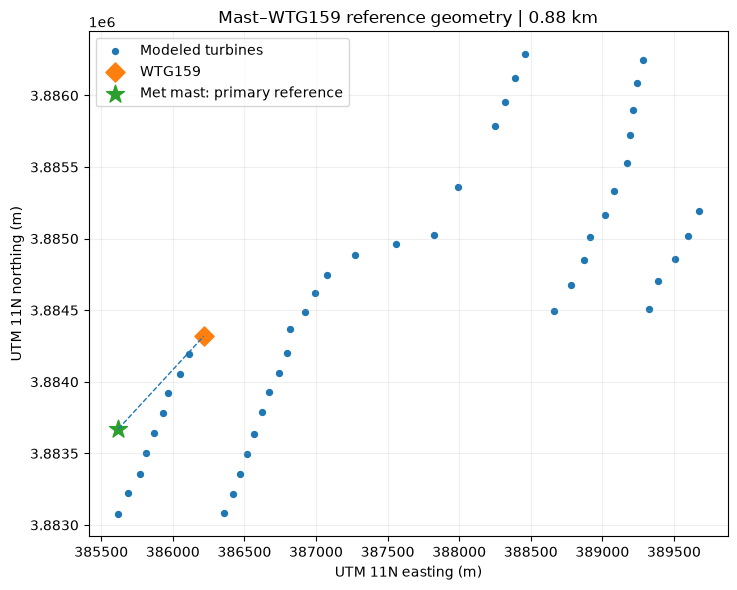

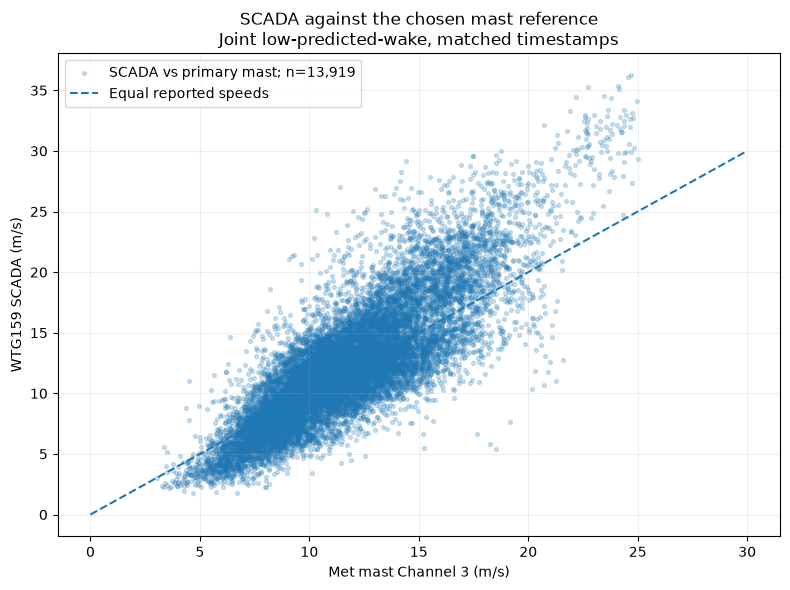

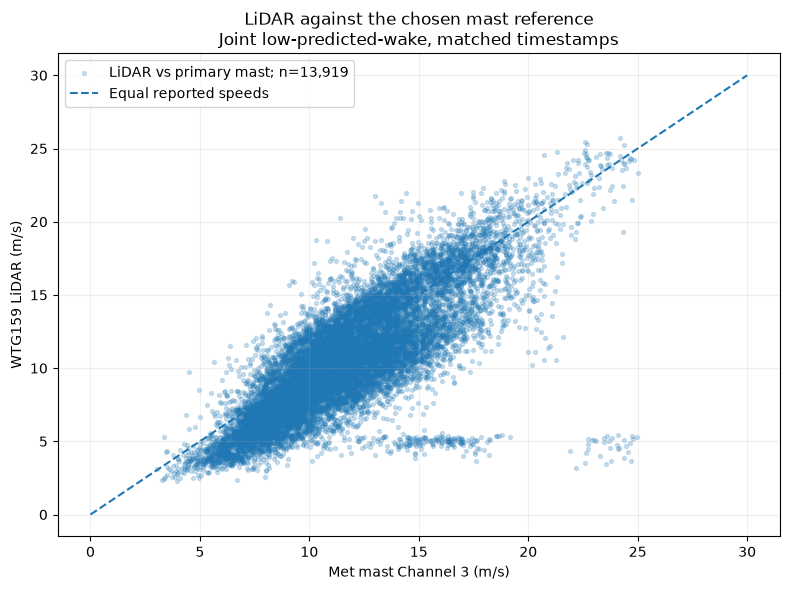

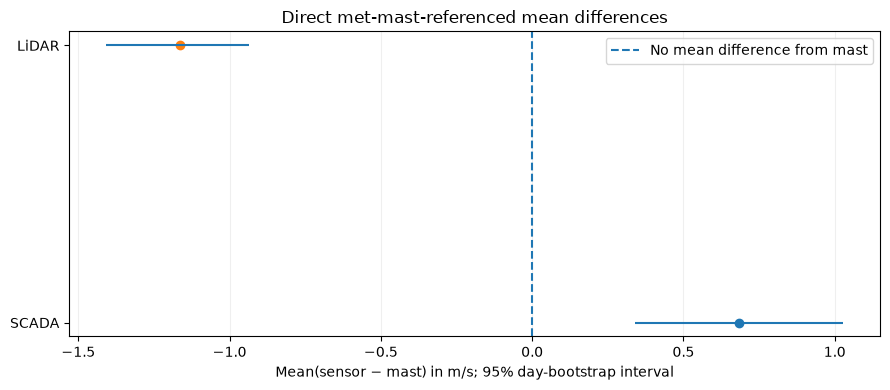

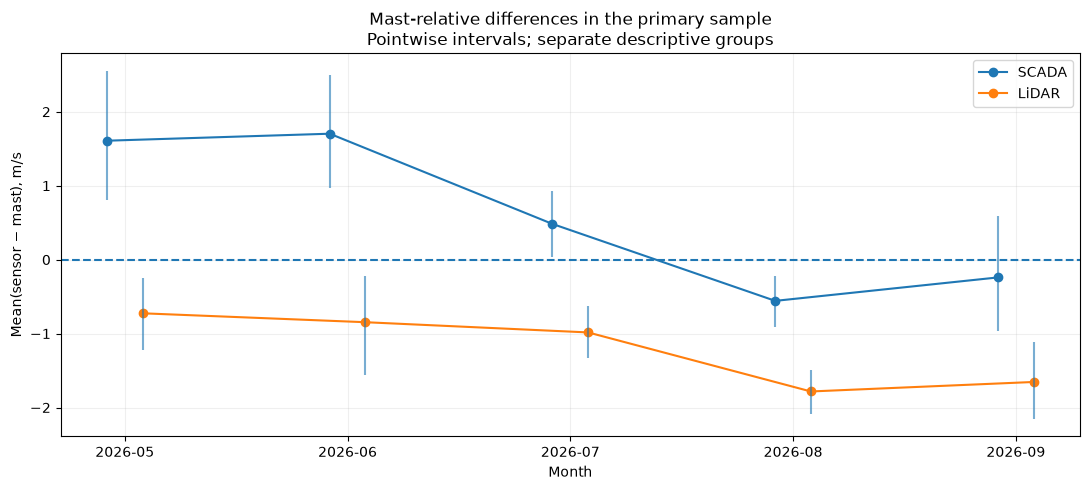

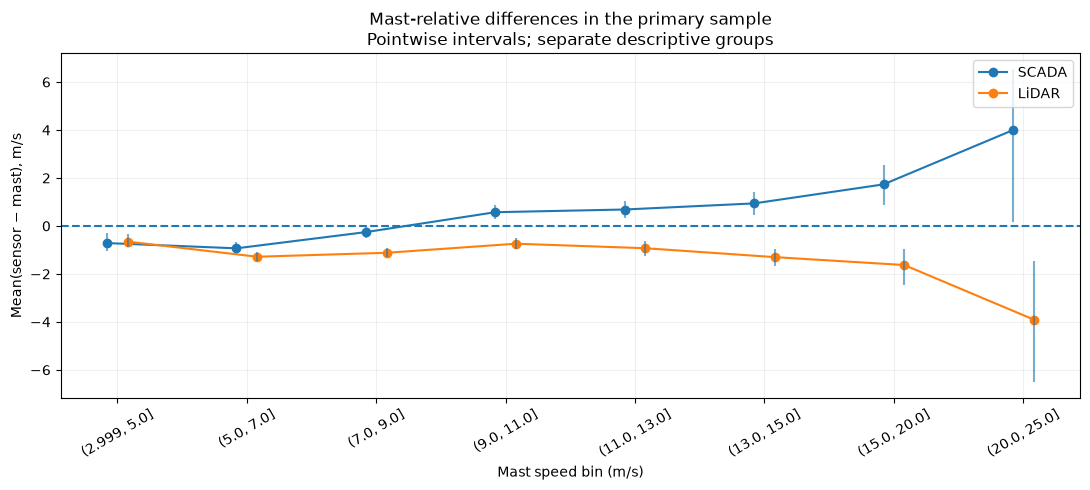

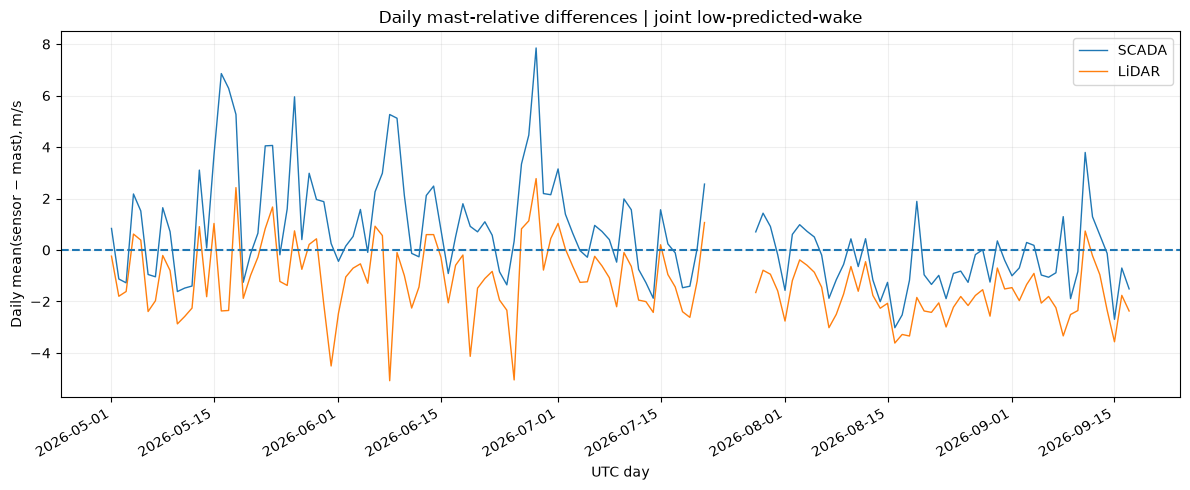

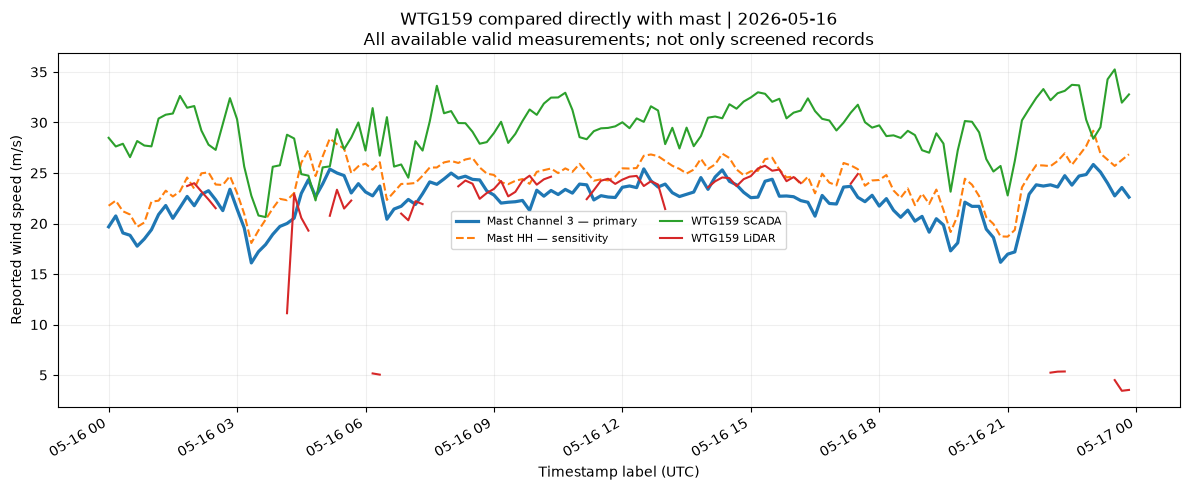

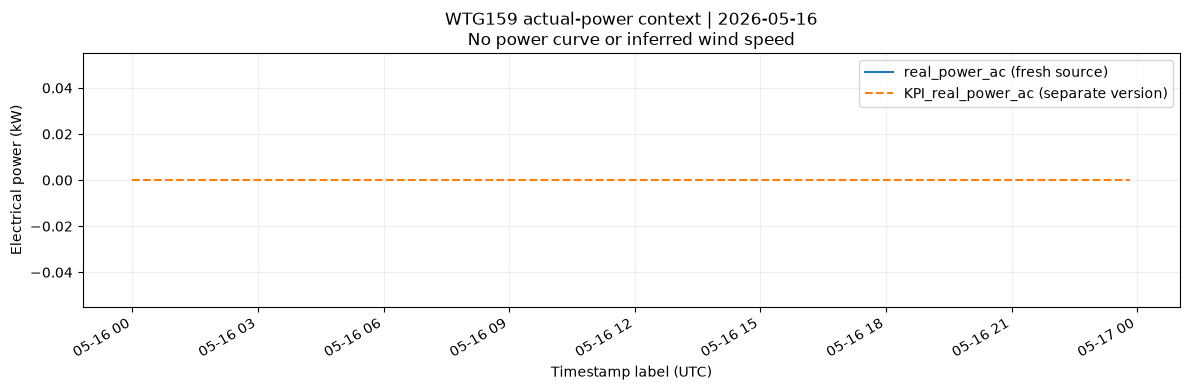

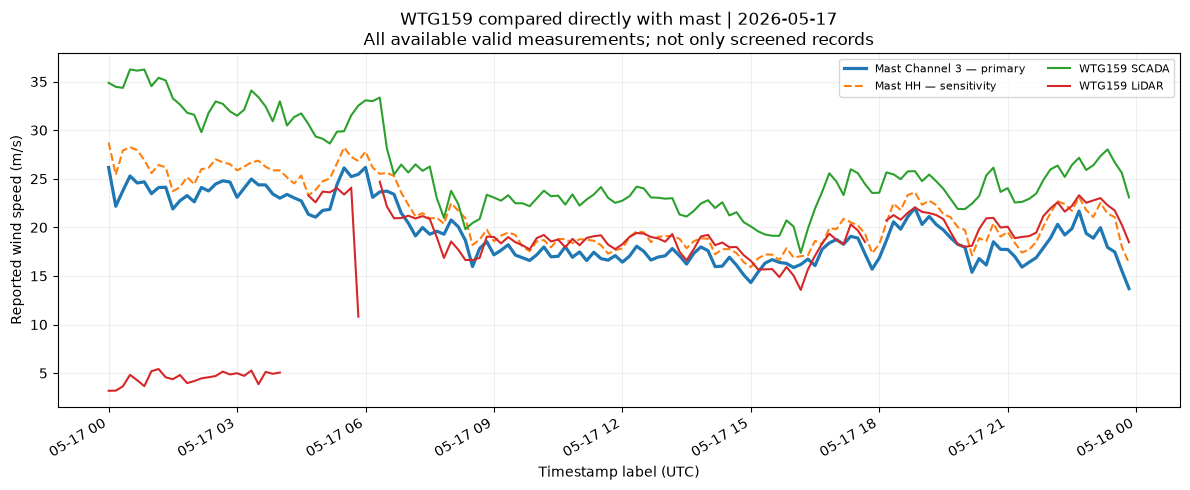

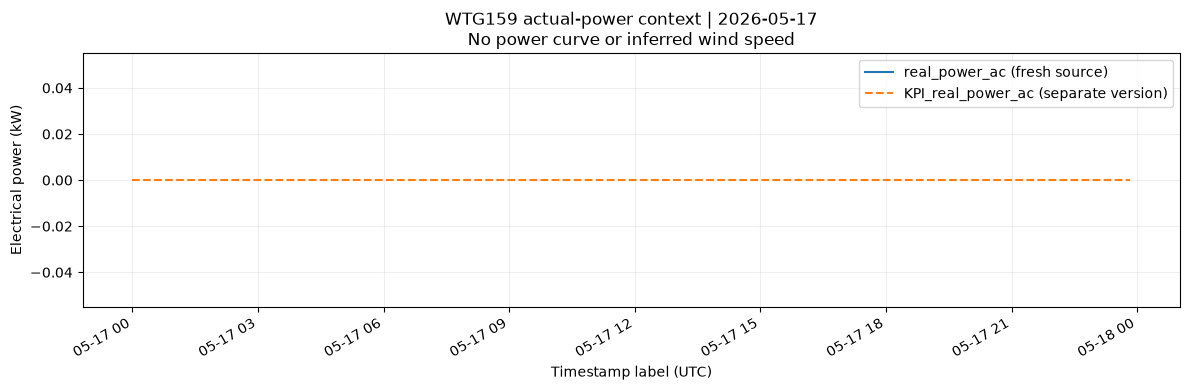

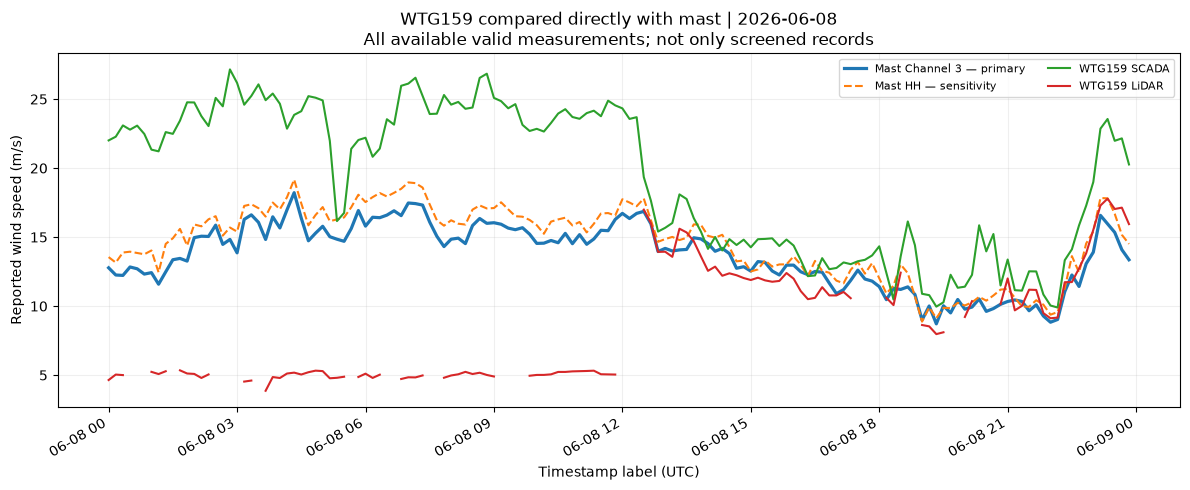

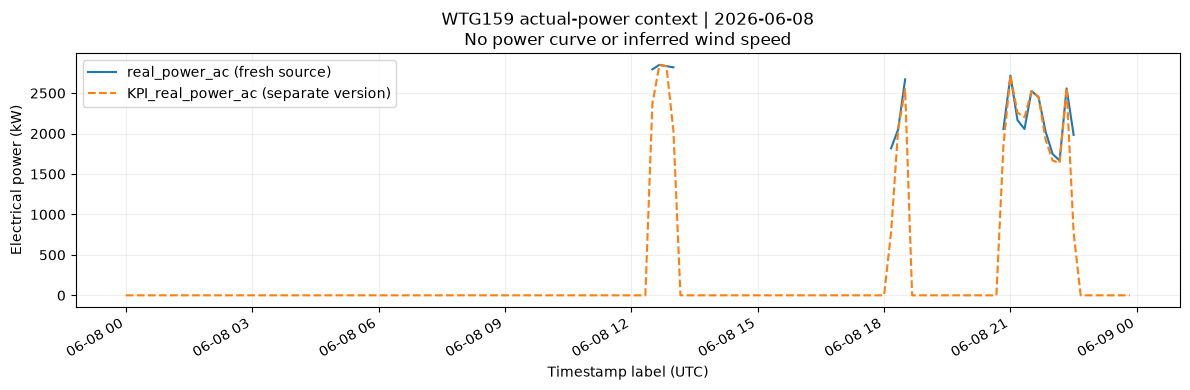


Saved: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z
Mast is the working reference. Mean differences, episode flags and historical change are separate findings.


In [9]:
def run_analysis(config=None):
    cfg=dict(CONFIG if config is None else config)
    if cfg['target']!='WTG159' or 0 not in cfg['direction_offsets_deg']:
        raise ValueError('This notebook is focused on WTG159; offsets must include zero.')
    if not cfg['mast_height_scenarios_m'] or not 0<cfg['historical_baseline_fraction']<1:
        raise ValueError('Invalid mast height scenarios or baseline fraction.')
    root=find_root(cfg)
    out=root/'data/processed/11_WTG159_mast_reference'/('run_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    out.mkdir(parents=True,exist_ok=False)
    print('Project:',root,'\nOutput:',out)
    d,audit,provenance=load_measurements(root,cfg)
    print('LiDAR source:',provenance['lidar_file'])
    print('LiDAR selection:',provenance['lidar_selection'])
    farm,geo=load_geometry(root,cfg,provenance)
    lookup,ct=wake_receptors(farm,geo,cfg)
    d=assign_wakes(d,lookup,cfg)
    d,episodes=detect_episodes(d,cfg)
    summary,contrasts,block_sensitivity=reference_summaries(d,cfg)
    groups=grouped_summaries(d,cfg)
    d,historical,baselines,split=historical_check(d,cfg)
    decisions=conclusion_table(summary,episodes,cfg)
    coverage=[]
    for name,mask in [
        ('SCADA valid, irrespective of LiDAR',d.scada_ms_valid),
        ('LiDAR complete and plausible',d.lidar_ms_valid),
        ('Mast within 3-25 m/s',d.mast_analysis_range),
        ('All three valid: common comparison',d.common_valid),
        ('Common + target-only low predicted wake',d.common_valid & d.primary_target_wake_max_pct.lt(cfg['wake_limit_pct'])),
        ('PRIMARY: common + target and mast low predicted wake',d.primary_sample),
    ]:
        coverage.append({'stage':name,'records':int(mask.sum()),'days':d.index[mask].normalize().nunique(),
                         'pct_of_full_grid':100*mask.mean()})
    coverage=pd.DataFrame(coverage)
    reference_check=pd.DataFrame([{'comparison':'Channel 3 − HH',
        'paired_speed_n':int((d.mast_ms_valid & d.mast_hh_ms_valid).sum()),
        'mean_speed_difference_ms':d.mast_speed_difference_hh_ms.where(d.mast_ms_valid & d.mast_hh_ms_valid).mean(),
        'median_abs_speed_difference_ms':d.mast_speed_difference_hh_ms.where(d.mast_ms_valid & d.mast_hh_ms_valid).abs().median(),
        'paired_direction_n':int(d.mast_direction_difference_hh_deg.notna().sum()),
        'median_abs_direction_difference_deg':d.mast_direction_difference_hh_deg.median()}])
    event_rows=[]
    for date in cfg['known_event_dates']:
        mask=d.index.strftime('%Y-%m-%d')==date
        for s in SENSORS:
            m=mask & d.mast_analysis_range & d[s+'_valid']
            r=summarize(d,m,s,'mast_ms',date,cfg)
            r['low_wake_records']=int((m & d.primary_joint_low_wake).sum())
            r['original_power_available_n']=int(d.loc[m,'power_original_kw'].notna().sum())
            r['kpi_power_available_n']=int(d.loc[m,'power_kpi_kw'].notna().sum())
            event_rows.append(r)
    event_report=pd.DataFrame(event_rows)
    for name,table in [
        ('11_reference_relative_summary',summary),('11_sensor_contrast_same_timestamps',contrasts),
        ('11_block_length_sensitivity',block_sensitivity),('11_sample_coverage',coverage),
        ('11_mast_channel_consistency',reference_check),('11_candidate_episodes',episodes),
        ('11_documented_event_summary',event_report),('11_historical_change_summary',historical),
        ('11_earlier_condition_baselines',baselines),('11_interpretation_table',decisions),
        ('11_input_audit',pd.DataFrame(audit)),('11_geometry',pd.DataFrame([geo])),
        ('11_directional_wake_receptors',lookup)]:
        save_table(table,name,out)
    for key,table in groups.items():
        save_table(table,'11_primary_by_'+key,out)
    save_table(d.reset_index(),'11_all_aligned_observations',out)
    print('\nCOVERAGE (stage denominators shown, no silent relaxation)');display(coverage.round(3))
    print('\nPRIMARY RESULTS RELATIVE TO MAST')
    display(decisions[['sensor','primary_n','primary_days','mean_sensor_minus_mast_ms','ci_low_ms','ci_high_ms','mae_ms','rmse_ms']].round(3))
    for row in decisions.itertuples(index=False):
        print(f'{row.sensor}: {row.reference_relative_finding}.')
    print('\nSENSITIVITY / SEPARATE PAIRWISE RESULTS')
    display(summary[['sample','sensor','reference','n','days','mean_difference_ms','ci_low_ms','ci_high_ms']].round(3))
    print('\nKNOWN EVENT DAYS (descriptive; not independent intervals)');display(event_report.round(3))
    print('\nCANDIDATE EPISODES');display(episodes.head(20).round(3))
    print('\nHISTORICAL CHANGE — NOT ABSOLUTE CALIBRATION');display(historical.round(3))
    make_figures(d,summary,groups,episodes,farm,geo,cfg,out)
    provenance.update({'config':cfg,'candidate_Ct':ct,'history_split_utc':str(split),
                       'mast_height_note':'documented alternative speed-sensor heights; processed-channel mapping unresolved',
                       'numpy_version':np.__version__,'pandas_version':pd.__version__,
                       'input_date_start':str(d.index.min()),'input_date_end':str(d.index.max())})
    (out/'11_run_settings.json').write_text(json.dumps(provenance,indent=2,default=str),encoding='utf-8')
    lines=['# WTG159 — met-mast-referenced results','',
        'Reference: mast Channel 3. Both sensors use identical timestamps in the primary analysis.',
        f'Coordinates give mast–WTG159 separation {geo["distance_km"]:.3f} km; ground elevation difference {geo["target_minus_mast_ground_m"]:.2f} m.',
        'No fitted correction is subtracted from the primary results. Power does not select the primary sample.','']
    for r in decisions.itertuples(index=False):
        lines.append(f'- {r.sensor}: n={r.primary_n}, days={r.primary_days}; mean(sensor − mast)={r.mean_sensor_minus_mast_ms:.3f} m/s; day-bootstrap interval [{r.ci_low_ms:.3f}, {r.ci_high_ms:.3f}]. {r.reference_relative_finding}.')
    lines += ['', '## Reading the results',
        'A nonzero mean establishes a reference-relative difference, not which physical component is wrong. A near-zero mean is not equivalence; inspect MAE, RMSE and episodes.',
        'Compare all-common, screened, event-excluded and HH-reference rows. Same-timestamp absolute-distance contrasts describe which source is closer to the mast, not which is calibrated.',
        'Legacy flags and historical events were retained in the primary analysis; sensitivity exclusions are shown separately.',
        'The mast is used as the designated working standard. Its workbook supports location/instrument metadata, not a verified processed-channel mapping or a site-transfer calibration.',
        'Wake screening checks WTG159 and two documented mast height scenarios with fixed physics. It does not simulate terrain flow, tower distortion or omitted upstream farms.',
        'Historical baseline results detect change only; earlier sensor offsets can be absorbed. No correction is applied to original data.',
        'Day and three-day intervals capture resampling variability, not all serial dependence or systematic uncertainties.',
        'Candidate episodes and thresholds are exploratory. No automated broken/healthy classification or power-derived wind reconstruction is used.',
        '', '## Research-paper outputs',
        'Primary table: 11_interpretation_table.csv; data attrition: 11_sample_coverage.csv; event evidence: 11_documented_event_summary.csv and 11_candidate_episodes.csv.',
        'Figures: primary mast-relative intervals; direct sensor-versus-mast scatter; month/speed dependence; event wind and fresh-source power.',
        '', 'Final stopping point: report the supported mast-relative discrepancies, persistent versus episodic behavior, and attribution limits. Do not change filters to force a fault diagnosis.']
    (out/'11_RESULTS_AND_INTERPRETATION.md').write_text('\n'.join(lines),encoding='utf-8')
    print('\nSaved:',out)
    print('Mast is the working reference. Mean differences, episode flags and historical change are separate findings.')
    return {'aligned':d,'summary':summary,'decisions':decisions,'episodes':episodes,'coverage':coverage,
            'contrasts':contrasts,'groups':groups,'historical':historical,'output_dir':out}

mast_results = run_analysis(CONFIG)


### WTG159 — Data Quality and Sensor Validation Notes

Our met-mast validation analysis identified persistent differences between WTG159's SCADA and LiDAR wind-speed measurements.

Across 13,919 matched ten-minute observations under low-predicted-wake conditions:

- **SCADA** reported an average wind speed 0.682 m/s higher than the met mast.
- **LiDAR** reported an average wind speed 1.164 m/s lower than the met mast.
- During mast wind speeds of 7–10 m/s, SCADA nearly matched the mast on average, while LiDAR remained approximately 1.0 m/s lower.
- Unusual LiDAR behavior was also identified on May 16–17 and June 8.

These findings suggest potential measurement discrepancies, particularly within the LiDAR system. However, differences between sensor locations and unverified instrument configurations prevent us from confirming a physical sensor fault.

#### Why We Are Comparing KPI and Non-KPI Data

We noticed that the original `real_power_ac` column contains substantially more missing values than `KPI_real_power_ac` on certain dates.

For example, on June 8:
- `real_power_ac`: 18 available observations.
- `KPI_real_power_ac`: 144 available observations.

This raises questions about how the KPI variables are processed and whether they contain filtered, adjusted, or substituted values.

**The goal of this check** is to compare missing-value percentages for matching KPI and non-KPI variables, determine which fields have better coverage, and identify where additional data processing may be occurring.

Missing values (`NaN`) and numerical zeros are treated separately. More complete data does not necessarily mean more accurate data.

**Next step:** Review the missing-data results before deciding which SCADA fields should be used in our final sensor-validation analysis.



## 10. What to read first
1. **11_interpretation_table.csv:** direct SCADA and LiDAR differences from the mast.
2. **11_sample_coverage.csv:** how much evidence remains after screening BOTH sites.
3. **June 8 event figure + 11_documented_event_summary.csv:** which measured report
   departs from the mast, when it changes, and whether fresh power is available.
4. **11_primary_by_month / mast_speed_bin:** persistence and condition dependence.
5. **11_historical_change_summary.csv:** later changes, NOT absolute calibration.

A definite conclusion may be “persistent positive mast-relative difference,”
“intermittent large negative disagreement,” or “insufficient screened coverage.”
It need not be a forced physical fault label. Keep the mast-centered result as the
main finding; report spatial uncertainty once alongside it rather than abandoning
the comparison. Stop after these defined checks unless an output exposes a data bug.

In [10]:

import pandas as pd
from pathlib import Path
from IPython.display import display

# =====================================================
# KPI vs NON-KPI MISSING DATA CHECK
# =====================================================

PROJECT = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

# Change to None to analyze all 47 turbines
TURBINE = "WTG159"

# Load ORIGINAL processed SCADA data
df = pd.read_parquet(
    PROJECT / "data/processed/scada_data.parquet"
)

if "turbine" not in df.columns:
    df = df.reset_index()

# Filter by turbine if requested
if TURBINE is not None:
    turbine_number = int(
        "".join(c for c in TURBINE if c.isdigit())
    )

    ids = pd.to_numeric(
        df["turbine"].astype(str)
        .str.extract(r"(\d+)(?:\.0)?$")[0],
        errors="coerce"
    )

    df = df[ids == turbine_number].copy()

print(f"Turbine: {TURBINE or 'All turbines'}")
print(f"Total SCADA records: {len(df):,}")

# Find matching KPI and non-KPI column pairs
pairs = [
    (col[4:], col)
    for col in df.columns
    if col.startswith("KPI_") and col[4:] in df.columns
]

results = []

for original, kpi in pairs:

    original_missing = df[original].isna()
    kpi_missing = df[kpi].isna()

    results.append({
        "Variable": original,
        "Non-KPI Missing": original_missing.sum(),
        "Non-KPI Missing %": round(
            original_missing.mean() * 100, 2
        ),
        "KPI Missing": kpi_missing.sum(),
        "KPI Missing %": round(
            kpi_missing.mean() * 100, 2
        ),
        "KPI Present / Non-KPI Missing": (
            original_missing & ~kpi_missing
        ).sum()
    })

missing_summary = pd.DataFrame(results)

if missing_summary.empty:
    print("No matching KPI / non-KPI column pairs found.")
else:
    missing_summary = missing_summary.sort_values(
        "Non-KPI Missing %",
        ascending=False
    )

    display(missing_summary)

    print("\nAverage missing percentage across matched columns:")
    print(
        "Non-KPI:",
        round(missing_summary["Non-KPI Missing %"].mean(), 2),
        "%"
    )
    print(
        "KPI:",
        round(missing_summary["KPI Missing %"].mean(), 2),
        "%"
    )


Turbine: WTG159
Total SCADA records: 39,018


,Variable,Non-KPI Missing,Non-KPI Missing %,KPI Missing,KPI Missing %,KPI Present / Non-KPI Missing
0,real_power_ac,14610,37.44,1582,4.05,13059
1,wind_speed,1716,4.40,2067,5.30,0



Average missing percentage across matched columns:
Non-KPI: 20.92 %
KPI: 4.68 %


WTG159 — MONTHLY MISSING DATA (%)


,Month,Total Records,real_power_ac Missing %,KPI_real_power_ac Missing %,wind_speed Missing %,KPI_wind_speed Missing %
0,2026-01,4416,49.64,1.31,0.70,0.82
1,2026-02,4032,39.26,10.91,10.96,11.09
2,2026-03,4464,46.35,0.00,3.58,4.73
3,2026-04,4320,32.66,0.00,0.19,1.46
4,2026-05,4464,45.09,0.00,0.00,0.83
5,2026-06,4320,37.52,0.39,0.35,0.58
6,2026-07,4464,40.19,20.83,20.83,21.24
7,2026-08,4464,15.57,0.16,0.02,3.58
8,2026-09,4074,30.24,3.19,3.17,3.44



MONTHS WITH THE MOST MISSING NON-KPI POWER


,Month,Total Records,real_power_ac Missing,real_power_ac Missing %,KPI_real_power_ac Missing %,KPI Power Present / Non-KPI Missing,KPI Power Zeros
0,2026-01,4416,2192,49.64,1.31,2152,2158
2,2026-03,4464,2069,46.35,0.00,2069,2071
4,2026-05,4464,2013,45.09,0.00,2013,2016
6,2026-07,4464,1794,40.19,20.83,864,872
1,2026-02,4032,1583,39.26,10.91,1144,1142


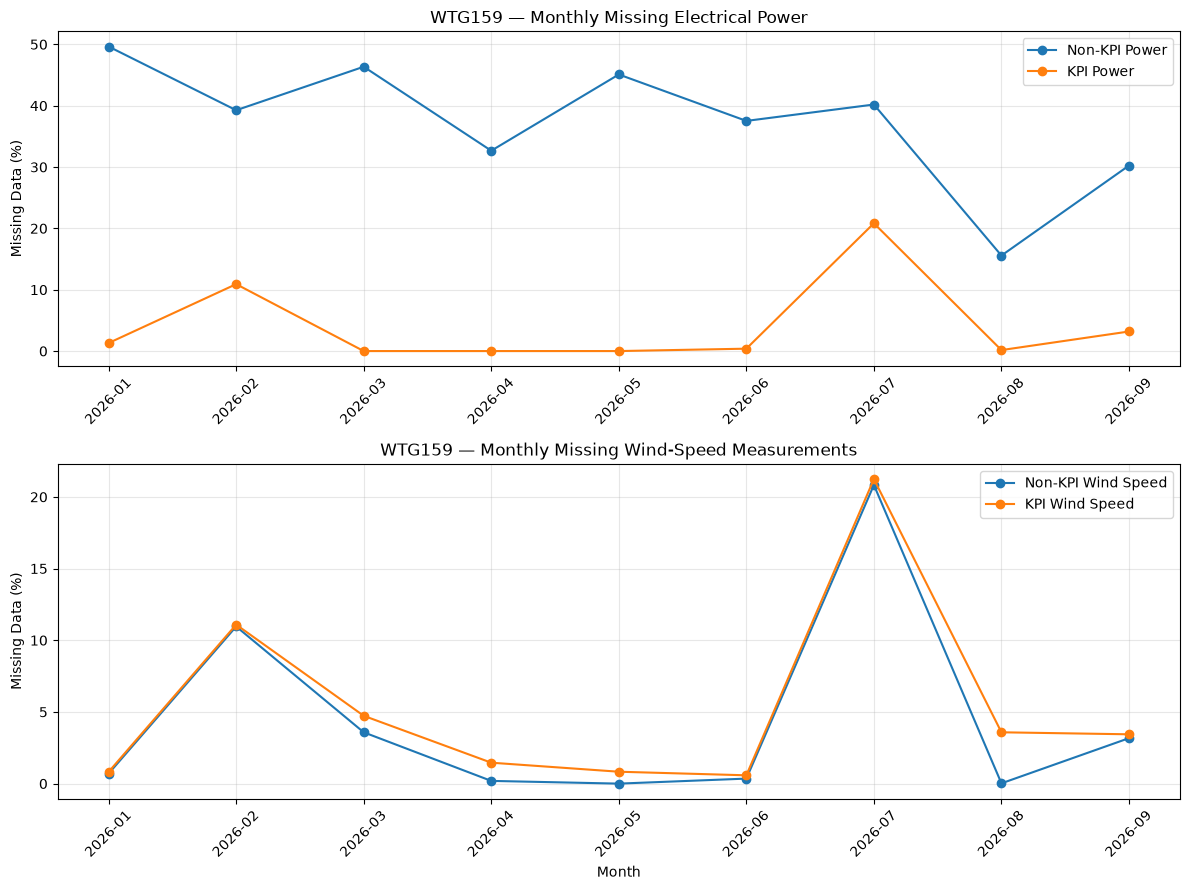

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# =====================================================
# WTG159 — MONTHLY KPI VS NON-KPI MISSING DATA
# =====================================================

monthly = df.copy()

# Find timestamp column
if "utc" not in monthly.columns and "timestamp" not in monthly.columns:
    monthly = monthly.reset_index()

time_col = next(
    (c for c in ["utc", "timestamp"] if c in monthly.columns),
    None
)

if time_col is None:
    raise KeyError("Cannot find utc or timestamp column.")

monthly["month"] = pd.to_datetime(
    monthly[time_col],
    errors="coerce",
    utc=True
).dt.strftime("%Y-%m")

monthly = monthly.dropna(subset=["month"])

# Columns to investigate
columns = [
    "real_power_ac",
    "KPI_real_power_ac",
    "wind_speed",
    "KPI_wind_speed"
]

missing = [c for c in columns if c not in monthly.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")

# =====================================================
# 1. Calculate missing values by month
# =====================================================

results = []

for month, group in monthly.groupby("month", sort=True):

    row = {
        "Month": month,
        "Total Records": len(group)
    }

    for col in columns:

        row[f"{col} Missing"] = group[col].isna().sum()

        row[f"{col} Missing %"] = round(
            group[col].isna().mean() * 100, 2
        )

    row["KPI Power Present / Non-KPI Missing"] = (
        group["real_power_ac"].isna()
        & group["KPI_real_power_ac"].notna()
    ).sum()

    row["KPI Power Zeros"] = (
        pd.to_numeric(
            group["KPI_real_power_ac"],
            errors="coerce"
        ) == 0
    ).sum()

    results.append(row)

monthly_summary = pd.DataFrame(results)

# =====================================================
# 2. Display monthly missing percentages
# =====================================================

print("WTG159 — MONTHLY MISSING DATA (%)")

display(
    monthly_summary[
        ["Month", "Total Records"] +
        [f"{c} Missing %" for c in columns]
    ]
)

# =====================================================
# 3. Identify months with most missing data
# =====================================================

print("\nMONTHS WITH THE MOST MISSING NON-KPI POWER")

display(
    monthly_summary.nlargest(
        5, "real_power_ac Missing %"
    )[
        [
            "Month",
            "Total Records",
            "real_power_ac Missing",
            "real_power_ac Missing %",
            "KPI_real_power_ac Missing %",
            "KPI Power Present / Non-KPI Missing",
            "KPI Power Zeros"
        ]
    ]
)

# =====================================================
# 4. Plot monthly missing percentages
# =====================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9)
)

# Electrical power
axes[0].plot(
    monthly_summary["Month"],
    monthly_summary["real_power_ac Missing %"],
    marker="o",
    label="Non-KPI Power"
)

axes[0].plot(
    monthly_summary["Month"],
    monthly_summary["KPI_real_power_ac Missing %"],
    marker="o",
    label="KPI Power"
)

axes[0].set_title(
    "WTG159 — Monthly Missing Electrical Power"
)

axes[0].set_ylabel("Missing Data (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Wind speed
axes[1].plot(
    monthly_summary["Month"],
    monthly_summary["wind_speed Missing %"],
    marker="o",
    label="Non-KPI Wind Speed"
)

axes[1].plot(
    monthly_summary["Month"],
    monthly_summary["KPI_wind_speed Missing %"],
    marker="o",
    label="KPI Wind Speed"
)

axes[1].set_title(
    "WTG159 — Monthly Missing Wind-Speed Measurements"
)

axes[1].set_xlabel("Month")
axes[1].set_ylabel("Missing Data (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [12]:
# =====================================================
# WTG159 — Do missing original power values become KPI zeros?
# =====================================================

import pandas as pd
from IPython.display import display

check = monthly.copy()

raw_missing = check["real_power_ac"].isna()

kpi_power = pd.to_numeric(
    check["KPI_real_power_ac"],
    errors="coerce"
)

check["Raw Missing + KPI Zero"] = (
    raw_missing & kpi_power.eq(0)
)

check["Raw Missing + KPI Nonzero"] = (
    raw_missing & kpi_power.notna() & kpi_power.ne(0)
)

check["Raw Missing + KPI Missing"] = (
    raw_missing & kpi_power.isna()
)

check["Raw Present + KPI Zero"] = (
    ~raw_missing & kpi_power.eq(0)
)

result = check.groupby("month")[
    [
        "Raw Missing + KPI Zero",
        "Raw Missing + KPI Nonzero",
        "Raw Missing + KPI Missing",
        "Raw Present + KPI Zero"
    ]
].sum().astype(int)

display(result)

,Raw Missing + KPI Zero,Raw Missing + KPI Nonzero,Raw Missing + KPI Missing,Raw Present + KPI Zero
month,,,,
2026-01,2152,0,40,6
2026-02,1141,3,439,1
2026-03,2069,0,0,2
2026-04,1411,0,0,7
2026-05,2013,0,0,3
2026-06,1607,0,14,2
2026-07,864,0,930,8
2026-08,694,1,0,16
2026-09,1104,0,128,2


Using output: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z

Matched observations: 3653
Distinct days: 127

OVERALL MAST COMPARISON


,group,observations,days,scada_minus_mast_mean,scada_minus_mast_low,scada_minus_mast_high,lidar_minus_mast_mean,lidar_minus_mast_low,lidar_minus_mast_high,scada_minus_lidar_mean,scada_minus_lidar_low,scada_minus_lidar_high
0,All low-wake observations,3653,127,0.004,-0.241,0.265,-1.004,-1.216,-0.795,1.008,0.924,1.102
1,Exclude May 16–17 and June 8,3645,126,0.001,-0.246,0.278,-1.007,-1.211,-0.810,1.007,0.922,1.098



MAST-RELATIVE DIFFERENCES BY WIND DIRECTION


,wind_from_sector,observations,days,scada_minus_mast_mean,lidar_minus_mast_mean,scada_minus_lidar_mean,supported
0,015°–045°,2,1,-1.809,-2.212,0.402,False
1,225°–255°,19,7,-1.737,-2.334,0.597,False
2,255°–285°,617,94,-0.323,-1.228,0.905,True
3,285°–315°,2988,125,0.106,-0.931,1.037,True
4,315°–345°,27,12,-2.432,-2.962,0.530,False



DIRECTION × MAST SPEED RESULTS


,direction_center,mast_speed_bin,n,days,scada_minus_mast_ms,lidar_minus_mast_ms,scada_minus_lidar_ms,supported
0,30,7–8,2,1,-1.809,-2.212,0.402,False
1,240,7–8,10,5,-2.198,-2.617,0.419,False
2,240,8–9,4,2,-1.544,-1.970,0.425,False
3,240,9–10,5,3,-0.971,-2.059,1.088,False
4,270,7–8,226,73,-0.723,-1.367,0.644,True
5,270,8–9,252,70,-0.233,-1.204,0.970,True
6,270,9–10,139,51,0.167,-1.046,1.213,True
7,300,7–8,677,107,-0.238,-1.001,0.763,True
8,300,8–9,1032,119,-0.103,-1.067,0.964,True
9,300,9–10,1279,123,0.457,-0.784,1.241,True


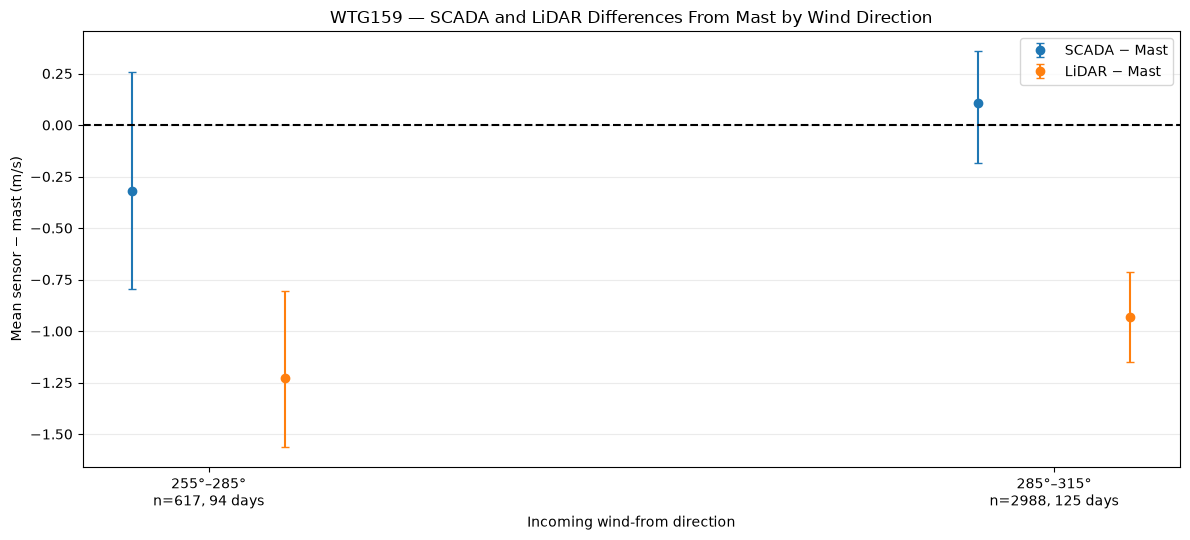

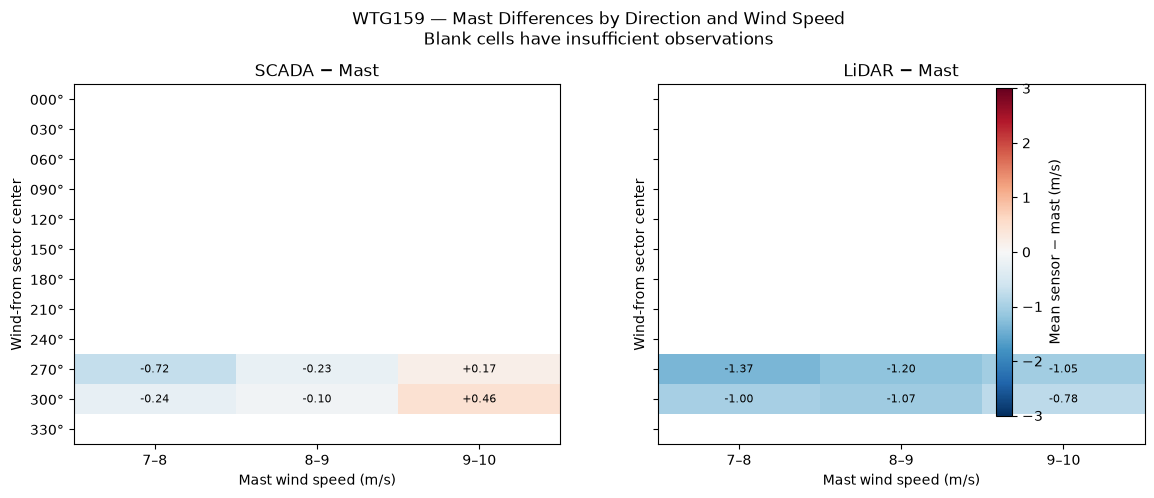


WTG159 DIRECTION AND SPEED ANALYSIS COMPLETE
Saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z\11B_direction_speed
Results are mast-relative measurement differences, not confirmed instrument calibration errors.


In [13]:

# ============================================================
# 11B — WTG159: Mast Differences by Wind Direction and Speed
# Uses existing 11_ outputs; wake model is NOT changed.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. Locate the previous notebook's output
# ------------------------------------------------------------

PROJECT_11B = Path(globals().get(
    "PROJECT_ROOT",
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
))

BASE_11B = (
    PROJECT_11B / "data/processed/11_WTG159_mast_reference"
)

if (
    isinstance(globals().get("mast_results"), dict)
    and "output_dir" in mast_results
):
    RUN_11B = Path(mast_results["output_dir"])
else:
    complete_runs = sorted(
        [
            p for p in BASE_11B.glob("run_*")
            if (p / "11_all_aligned_observations.csv").exists()
        ],
        reverse=True
    )

    if not complete_runs:
        raise FileNotFoundError("Run notebook 11 first.")

    RUN_11B = complete_runs[0]

OUTPUT_11B = RUN_11B / "11B_direction_speed"
OUTPUT_11B.mkdir(exist_ok=True)

print("Using output:", RUN_11B)

# ------------------------------------------------------------
# 2. Load the original matched observations
# ------------------------------------------------------------

df = pd.read_csv(
    RUN_11B / "11_all_aligned_observations.csv",
    low_memory=False
)

required = [
    "timestamp",
    "primary_sample",
    "scada_ms",
    "lidar_ms",
    "mast_ms",
    "mast_direction",
    "primary_target_wake_max_pct",
    "primary_mast_wake_max_pct"
]

missing = set(required) - set(df.columns)

if missing:
    raise KeyError(f"Missing expected columns: {missing}")

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True,
    errors="coerce"
)

if (
    df["timestamp"].isna().any()
    or df["timestamp"].duplicated().any()
):
    raise ValueError("Invalid or duplicated timestamps.")

# Read the saved Boolean selection explicitly.
selection = (
    df["primary_sample"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if not selection.isin(
    ["true", "false", "1", "0", "1.0", "0.0"]
).all():
    raise ValueError("Unknown primary_sample values.")

df["primary_sample"] = selection.isin(
    ["true", "1", "1.0"]
)

numeric_columns = [
    "scada_ms",
    "lidar_ms",
    "mast_ms",
    "mast_direction",
    "primary_target_wake_max_pct",
    "primary_mast_wake_max_pct"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------------------
# 3. Select the exact conditions we want
# ------------------------------------------------------------

# Reuse 11's original joint low-wake selection.
# Only add the mast 7–10 m/s restriction.
valid = (
    df["primary_sample"]
    & df["mast_ms"].between(7, 10)
    & df[
        ["scada_ms", "lidar_ms", "mast_ms", "mast_direction"]
    ].notna().all(axis=1)
)

data = df.loc[valid].copy().sort_values("timestamp")

if data.empty:
    raise ValueError("No qualifying observations found.")

# Verify the saved wake classification.
if not (
    data["primary_target_wake_max_pct"].lt(2)
    & data["primary_mast_wake_max_pct"].lt(2)
).all():
    raise ValueError("Saved observations failed the wake check.")

print("\nMatched observations:", len(data))
print(
    "Distinct days:",
    data["timestamp"].dt.floor("D").nunique()
)

# ------------------------------------------------------------
# 4. Calculate the three measurement differences
# ------------------------------------------------------------

data["scada_minus_mast"] = (
    data["scada_ms"] - data["mast_ms"]
)

data["lidar_minus_mast"] = (
    data["lidar_ms"] - data["mast_ms"]
)

data["scada_minus_lidar"] = (
    data["scada_ms"] - data["lidar_ms"]
)

data["day"] = data["timestamp"].dt.floor("D")

# Center 30-degree sectors on 0, 30, 60 ... 330.
data["direction_sector"] = (
    np.floor(
        ((data["mast_direction"] % 360) + 15) / 30
    ).astype(int) * 30
) % 360

data["speed_bin"] = pd.cut(
    data["mast_ms"],
    bins=[7, 8, 9, 10],
    labels=["7–8", "8–9", "9–10"],
    include_lowest=True
)

event_dates = [
    "2026-05-16",
    "2026-05-17",
    "2026-06-08"
]

data["known_event_day"] = (
    data["timestamp"]
    .dt.strftime("%Y-%m-%d")
    .isin(event_dates)
)

# ------------------------------------------------------------
# 5. Day-block bootstrap helper
# ------------------------------------------------------------

BOOTSTRAPS = 2000
MIN_OBS = 60
MIN_DAYS = 10

def day_bootstrap(group, variable, seed=159):

    valid = group[["day", variable]].dropna()

    if (
        len(valid) < MIN_OBS
        or valid["day"].nunique() < MIN_DAYS
    ):
        return np.nan, np.nan

    daily = valid.groupby("day")[variable].agg(
        ["sum", "count"]
    )

    rng = np.random.default_rng(seed)

    draws = rng.integers(
        0,
        len(daily),
        size=(BOOTSTRAPS, len(daily))
    )

    means = (
        daily["sum"].to_numpy()[draws].sum(axis=1)
        / daily["count"].to_numpy()[draws].sum(axis=1)
    )

    return tuple(
        np.quantile(means, [0.025, 0.975])
    )


def summarize(group, label, seed=159):

    result = {
        "group": label,
        "observations": len(group),
        "days": group["day"].nunique()
    }

    variables = [
        "scada_minus_mast",
        "lidar_minus_mast",
        "scada_minus_lidar"
    ]

    for i, var in enumerate(variables):

        result[f"{var}_mean"] = group[var].mean()

        low, high = day_bootstrap(
            group, var, seed=seed + i
        )

        result[f"{var}_low"] = low
        result[f"{var}_high"] = high

    return result

# ------------------------------------------------------------
# 6. Overall results and anomaly-date sensitivity
# ------------------------------------------------------------

overall = pd.DataFrame([
    summarize(
        data,
        "All low-wake observations",
        seed=159
    ),
    summarize(
        data[~data["known_event_day"]],
        "Exclude May 16–17 and June 8",
        seed=259
    )
])

print("\nOVERALL MAST COMPARISON")
display(overall.round(3))

# ------------------------------------------------------------
# 7. Compare wind-direction sectors
# ------------------------------------------------------------

sector_results = pd.DataFrame([
    {
        "direction_center": int(direction),
        "wind_from_sector": (
            f"{(int(direction)-15)%360:03d}°–"
            f"{(int(direction)+15)%360:03d}°"
        ),
        **summarize(group, str(direction), seed=1000+int(direction))
    }
    for direction, group in data.groupby(
        "direction_sector", sort=True
    )
])

sector_results = sector_results.sort_values(
    "direction_center"
)

sector_results["supported"] = (
    sector_results["observations"] >= MIN_OBS
) & (
    sector_results["days"] >= MIN_DAYS
)

print("\nMAST-RELATIVE DIFFERENCES BY WIND DIRECTION")

display(
    sector_results[
        [
            "wind_from_sector",
            "observations",
            "days",
            "scada_minus_mast_mean",
            "lidar_minus_mast_mean",
            "scada_minus_lidar_mean",
            "supported"
        ]
    ].round(3)
)

# ------------------------------------------------------------
# 8. Compare direction AND mast-speed bins together
# ------------------------------------------------------------

joint_rows = []

for (direction, speed_bin), group in data.groupby(
    ["direction_sector", "speed_bin"],
    observed=True
):

    joint_rows.append({
        "direction_center": int(direction),
        "mast_speed_bin": str(speed_bin),
        "n": len(group),
        "days": group["day"].nunique(),
        "scada_minus_mast_ms":
            group["scada_minus_mast"].mean(),
        "lidar_minus_mast_ms":
            group["lidar_minus_mast"].mean(),
        "scada_minus_lidar_ms":
            group["scada_minus_lidar"].mean()
    })

joint = pd.DataFrame(joint_rows)

# Exploratory minimum for displaying these descriptive cells.
joint["supported"] = (
    joint["n"] >= 30
) & (
    joint["days"] >= 7
)

print("\nDIRECTION × MAST SPEED RESULTS")
display(joint.round(3))

# ------------------------------------------------------------
# 9. Graph 1: Directional comparison
# ------------------------------------------------------------

plot_data = sector_results[
    sector_results["supported"]
].copy()

if not plot_data.empty:

    fig, ax = plt.subplots(figsize=(12, 5.5))

    x = np.arange(len(plot_data))

    series = [
        ("scada_minus_mast", "SCADA − Mast", -0.09),
        ("lidar_minus_mast", "LiDAR − Mast", 0.09)
    ]

    for prefix, label, offset in series:

        mean = plot_data[f"{prefix}_mean"].to_numpy()
        lower = plot_data[f"{prefix}_low"].to_numpy()
        upper = plot_data[f"{prefix}_high"].to_numpy()

        ax.errorbar(
            x + offset,
            mean,
            yerr=np.vstack(
                [mean - lower, upper - mean]
            ),
            fmt="o",
            capsize=3,
            label=label
        )

    ax.axhline(
        0, color="black", linestyle="--"
    )

    labels = [
        f"{row.wind_from_sector}\n"
        f"n={row.observations}, {row.days} days"
        for row in plot_data.itertuples(index=False)
    ]

    ax.set_xticks(x)
    ax.set_xticklabels(labels)

    ax.set_title(
        "WTG159 — SCADA and LiDAR Differences "
        "From Mast by Wind Direction"
    )
    ax.set_ylabel("Mean sensor − mast (m/s)")
    ax.set_xlabel("Incoming wind-from direction")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_11B / "11B_direction_mast_differences.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

else:
    print("No direction sectors have sufficient observations.")

# ------------------------------------------------------------
# 10. Graph 2: Direction and speed heatmaps
# ------------------------------------------------------------

all_directions = list(range(0, 360, 30))
speed_labels = ["7–8", "8–9", "9–10"]

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    sharex=True, sharey=True
)

for ax, metric, title in [
    (axes[0], "scada_minus_mast_ms", "SCADA − Mast"),
    (axes[1], "lidar_minus_mast_ms", "LiDAR − Mast")
]:

    matrix_table = joint[
        joint["supported"]
    ].pivot(
        index="direction_center",
        columns="mast_speed_bin",
        values=metric
    ).reindex(
        index=all_directions,
        columns=speed_labels
    )

    matrix = np.ma.masked_invalid(
        matrix_table.to_numpy(dtype=float)
    )

    image = ax.imshow(
        matrix,
        aspect="auto",
        cmap="RdBu_r",
        vmin=-3,
        vmax=3
    )

    ax.set_xticks(range(len(speed_labels)))
    ax.set_xticklabels(speed_labels)

    ax.set_yticks(range(len(all_directions)))
    ax.set_yticklabels(
        [f"{d:03d}°" for d in all_directions]
    )

    ax.set_title(title)
    ax.set_xlabel("Mast wind speed (m/s)")
    ax.set_ylabel("Wind-from sector center")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):

            if np.isfinite(matrix[i, j]):
                ax.text(
                    j, i,
                    f"{matrix[i, j]:+.2f}",
                    ha="center",
                    va="center",
                    fontsize=8
                )

fig.colorbar(
    image,
    ax=axes,
    shrink=0.85,
    label="Mean sensor − mast (m/s)"
)

fig.suptitle(
    "WTG159 — Mast Differences by Direction and Wind Speed\n"
    "Blank cells have insufficient observations"
)

fig.subplots_adjust(top=0.83, right=0.89)

fig.savefig(
    OUTPUT_11B / "11B_direction_speed_heatmaps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 11. Save tables
# ------------------------------------------------------------

overall.to_csv(
    OUTPUT_11B / "11B_overall_comparison.csv",
    index=False
)

sector_results.to_csv(
    OUTPUT_11B / "11B_direction_results.csv",
    index=False
)

joint.to_csv(
    OUTPUT_11B / "11B_direction_speed_results.csv",
    index=False
)

data.to_csv(
    OUTPUT_11B / "11B_selected_observations.csv",
    index=False
)

print("\nWTG159 DIRECTION AND SPEED ANALYSIS COMPLETE")
print("Saved to:", OUTPUT_11B)
print(
    "Results are mast-relative measurement differences, "
    "not confirmed instrument calibration errors."
)


Using WTG159 reference run: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z
Non-event training records: 13,605 across 131 days
Supported reference cells: 16 of 33

TYPICAL NON-EVENT LiDAR–MAST RELATIONSHIP


,sector_center_deg,mast_speed_band,n,days,typical_lidar_minus_mast_ms,unexpected_low_threshold_ms
11,270,11–13 m/s,143,29,-0.25,7.57
12,270,13–15 m/s,86,14,-0.68,6.19
7,270,3–5 m/s,48,26,-0.92,3.00
8,270,5–7 m/s,255,69,-1.57,3.00
9,270,7–9 m/s,477,88,-1.55,3.53
10,270,9–11 m/s,264,57,-1.69,5.04
19,300,11–13 m/s,2794,125,-1.03,7.29
20,300,13–15 m/s,2312,108,-1.39,8.31
21,300,15–17 m/s,1291,77,-1.21,9.25
22,300,17–19 m/s,661,43,-0.82,7.90



EVENT SUMMARY — CHECK REFERENCE COVERAGE


,date_utc,slots,nonmissing_three_sources_n,joint_low_wake_n,reference_supported_n,unsupported_joint_low_wake_n,high_mast_above_25_ms_n,mean_lidar_minus_mast_ms,mean_scada_minus_mast_ms,mean_unexpected_departure_supported_ms,single_low_threshold_records,sustained_low_records,sustained_episodes
0,2026-05-16,144,98,66,33,33,5,-3.68,7.07,0.43,4,0,0
1,2026-05-17,144,144,132,109,23,6,-2.93,6.40,1.82,4,0,0
2,2026-06-08,144,144,114,114,0,0,-5.33,5.57,-3.92,29,18,4



SUSTAINED UNEXPECTEDLY LOW LiDAR EPISODES


,first_utc,last_label_utc,records,minutes,mean_mast_ms,mean_scada_ms,mean_lidar_ms,mean_expected_lidar_ms,mean_lidar_departure_ms,most_negative_departure_ms
0,2026-06-08 03:40:00+00:00,2026-06-08 04:30:00+00:00,6,60,16.42,24.30,4.81,15.25,-10.44,-12.22
1,2026-06-08 05:50:00+00:00,2026-06-08 06:20:00+00:00,4,40,16.39,21.62,4.95,15.18,-10.23,-10.85
2,2026-06-08 06:50:00+00:00,2026-06-08 07:20:00+00:00,4,40,17.20,25.97,4.84,16.28,-11.43,-11.81
3,2026-06-08 08:30:00+00:00,2026-06-08 09:00:00+00:00,4,40,16.06,25.71,5.04,14.85,-9.81,-9.97


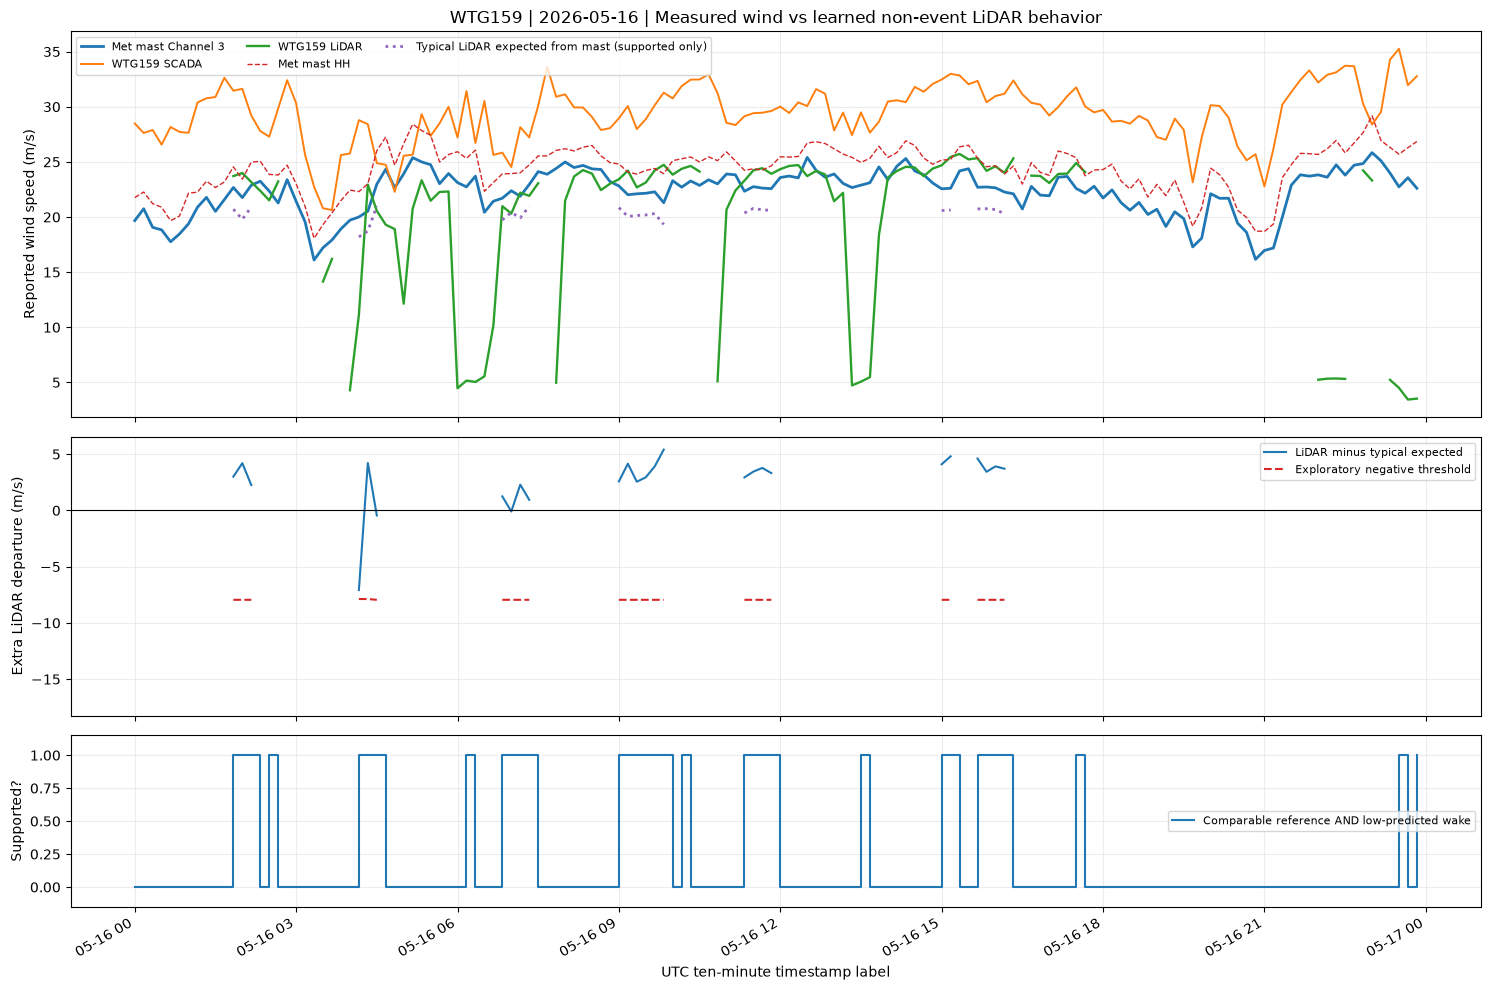

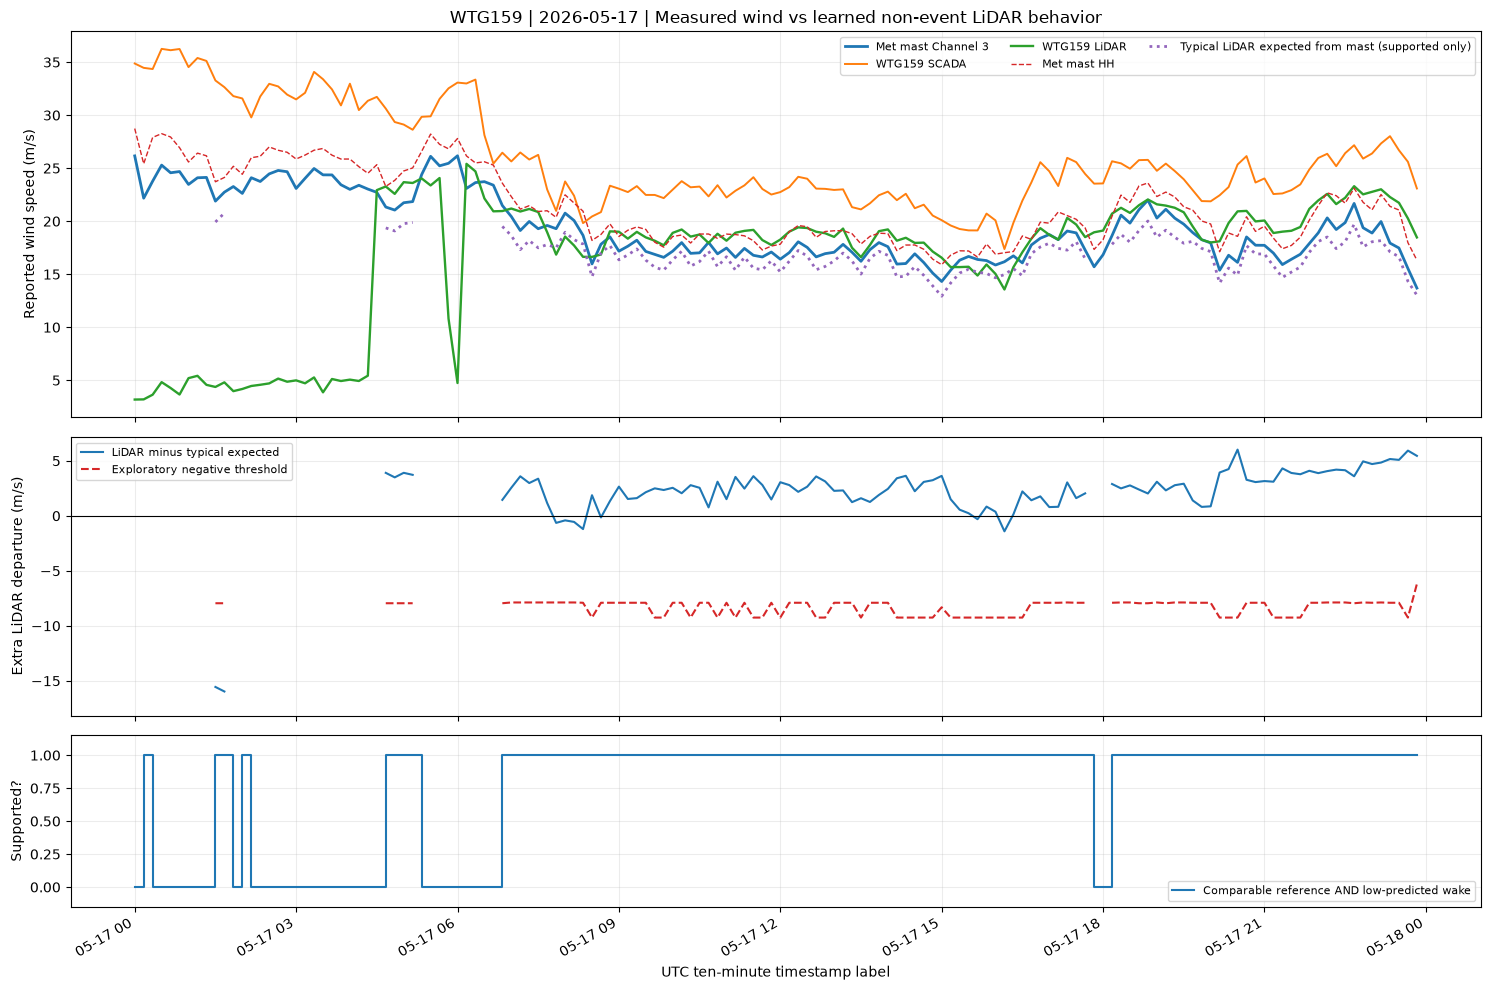

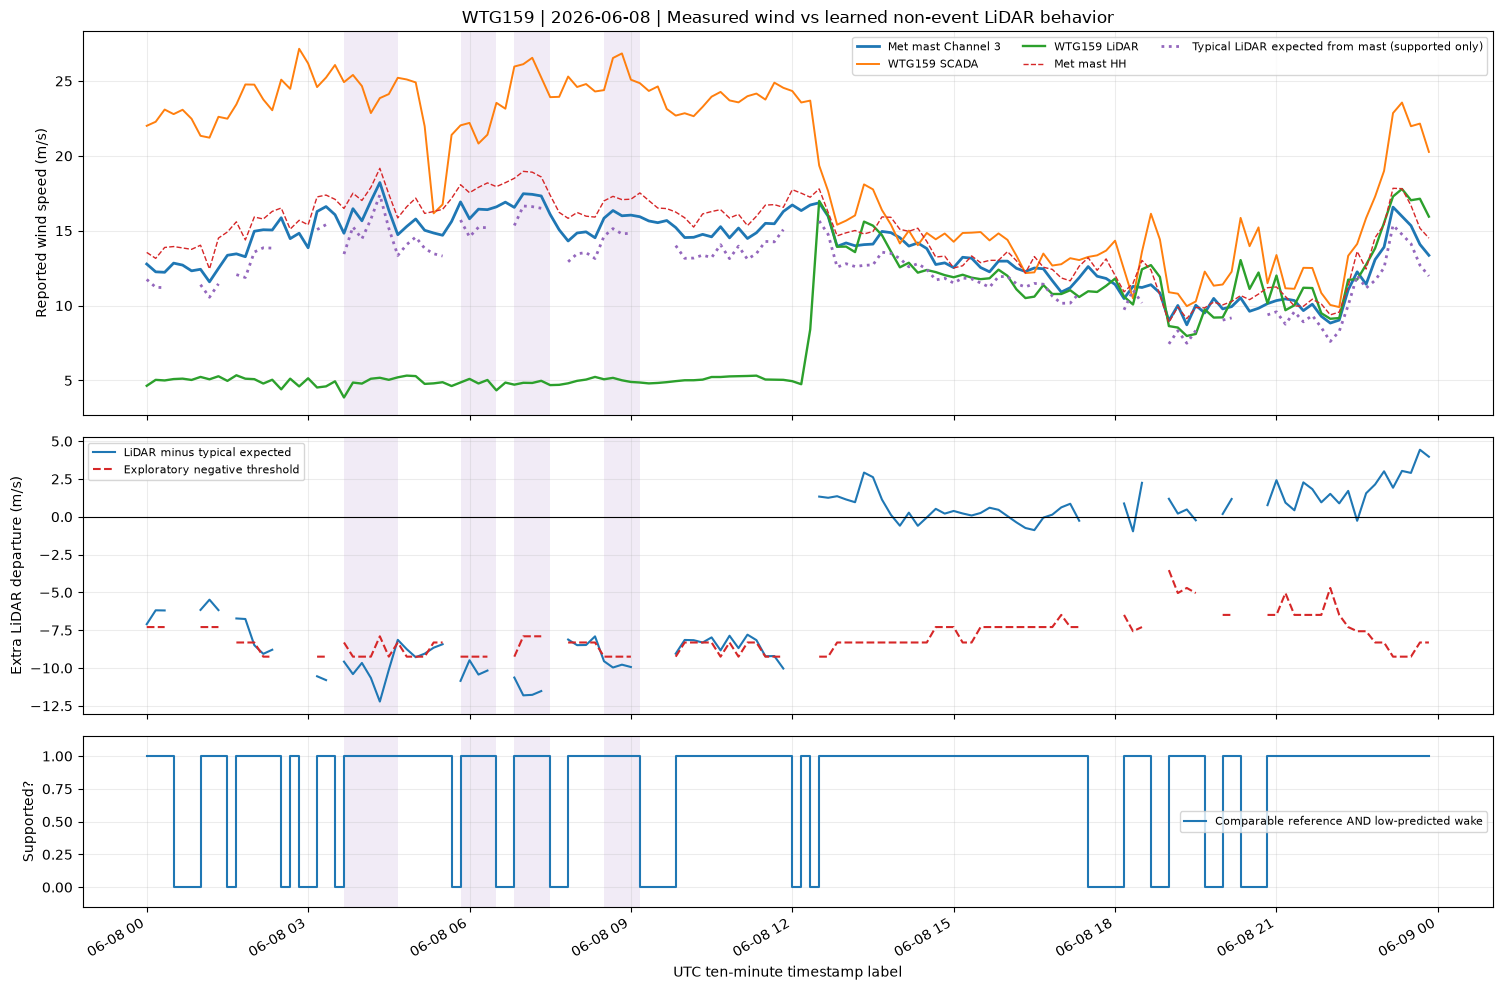


SIX-TURBINE HISTORICAL ANOMALY COMPARISON


,turbine,high_sensor_seconds,anomalous_low_seconds,intervals,pct_of_eligible_high_sensor_seconds
0,WTG159,122793,47982,432,39.08
1,WTG170,39386,7,432,0.02
2,WTG171,58832,1752,432,2.98
3,WTG173,43021,4,432,0.01
4,WTG180,124419,5,432,0.00
5,WTG184,62942,0,432,0.00


Percentages use seconds with Sensor 1 >20 m/s as the denominator, not all recorded seconds.

WTG159 FINAL LiDAR EVENT DIAGNOSTIC COMPLETE

Results saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\11_WTG159_mast_reference\run_20261102T034255815719Z\11D_final_event_diagnostic

A sustained departure from expected LiDAR behavior is evidence of an unusual measurement episode.
It does not by itself prove that LiDAR or a physical anemometer is broken.
High-wind conditions without sufficient normal reference data remain inconclusive.


In [14]:

# ===============================================================
# 11D | WTG159 FINAL LiDAR EVENT DIAGNOSTIC
# Paste as ONE CELL at the bottom of 11_ notebook.
# Uses saved 11_ matched measurements; model/wake flags unchanged.
# Identifies anomalous *departures from normal LiDAR-mast behavior*,
# not mere LiDAR < mast or confirmed hardware failure.
# ===============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT_D = Path(
    r'C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project'
)

BASE_D = ROOT_D / 'data/processed/11_WTG159_mast_reference'

prior_d = globals().get('mast_results')

if isinstance(prior_d, dict) and prior_d.get('output_dir'):
    RUN_D = Path(prior_d['output_dir'])
else:
    runs_d = sorted(
        (
            p for p in BASE_D.glob('run_*')
            if (p / '11_all_aligned_observations.csv').is_file()
        ),
        reverse=True
    )

    if not runs_d:
        raise FileNotFoundError(
            'Run notebook 11 first; no saved aligned-observation CSV found.'
        )

    RUN_D = runs_d[0]

OUT_D = RUN_D / '11D_final_event_diagnostic'
OUT_D.mkdir(exist_ok=True)

print('Using WTG159 reference run:', RUN_D)

# ===============================================================
# SETTINGS
# ===============================================================

# Fixed exploratory rules.
# Do not change them just to force an event result.

EVENT_DAYS_D = [
    '2026-05-16',
    '2026-05-17',
    '2026-06-08'
]

MIN_TRAIN_RECORDS_D = 30
MIN_TRAIN_DAYS_D = 5

# 3–5, 5–7, ..., 23–25 m/s
SPEED_EDGES_D = np.arange(3, 26, 2)

# Minimum unexpected negative departure
MIN_EXTRA_LOW_MS_D = 3.0

# Also require 3 times the group's robust spread
ROBUST_SD_MULT_D = 3.0

# Three consecutive 10-minute intervals
MIN_CONSECUTIVE_D = 3

# ===============================================================
# 1. LOAD THE EXISTING 11_ MATCHED OBSERVATIONS
# ===============================================================

d = pd.read_csv(
    RUN_D / '11_all_aligned_observations.csv',
    low_memory=False
)

needed = [
    'timestamp',
    'scada_ms',
    'lidar_ms',
    'mast_ms',
    'mast_direction',
    'primary_sample',
    'legacy_lidar_flag',
    'mast_hh_ms',
    'primary_target_wake_max_pct',
    'primary_mast_wake_max_pct'
]

absent = sorted(set(needed) - set(d.columns))

if absent:
    raise KeyError(
        f'Saved 11 file missing columns: {absent}'
    )

d['timestamp'] = pd.to_datetime(
    d['timestamp'],
    utc=True,
    errors='coerce'
)

if (
    d.timestamp.isna().any()
    or d.timestamp.duplicated().any()
):
    raise ValueError(
        'Invalid or duplicate 10-minute timestamps; no silent correction.'
    )

d = d.set_index('timestamp').sort_index()

for c in [
    'scada_ms',
    'lidar_ms',
    'mast_ms',
    'mast_direction',
    'mast_hh_ms',
    'primary_target_wake_max_pct',
    'primary_mast_wake_max_pct'
]:
    d[c] = pd.to_numeric(
        d[c],
        errors='coerce'
    )


def parse_optional_bool_d(s):
    return (
        s.astype(str)
        .str.lower()
        .str.strip()
        .map({
            'true': True,
            '1': True,
            '1.0': True,
            'false': False,
            '0': False,
            '0.0': False
        })
        .astype('boolean')
    )


d['primary_sample'] = parse_optional_bool_d(
    d.primary_sample
)

d['legacy_lidar_flag'] = parse_optional_bool_d(
    d.legacy_lidar_flag
)

if d['primary_sample'].isna().any():
    raise ValueError(
        'Unknown primary selection in saved 11 data.'
    )

d['date'] = d.index.strftime('%Y-%m-%d')
d['is_event'] = d.date.isin(EVENT_DAYS_D)
d['day'] = d.index.floor('D')

# 30-degree direction sectors and 2 m/s mast-speed bands.
# No extrapolation outside recorded reference conditions.

d['sector'] = (
    np.floor(
        ((d.mast_direction % 360) + 15) / 30
    ).astype('Int64') % 12
)

d['speed_bin'] = pd.cut(
    d.mast_ms,
    SPEED_EDGES_D,
    labels=False,
    include_lowest=True,
    right=True
).astype('Int64')

d['lidar_minus_mast'] = (
    d.lidar_ms - d.mast_ms
)

# ===============================================================
# 2. BUILD NORMAL LiDAR–MAST RELATIONSHIP
# ===============================================================

# Learn normal behavior using:
# - Low predicted wake observations
# - Dates OTHER than the three known event days
# - Observations not marked as questionable by the earlier
#   exploratory LiDAR quality-control rule
#
# This is an empirical reference relationship, not a
# manufacturer-certified calibration.

train_mask = (
    d.primary_sample.eq(True)
    & ~d.is_event
    & d.legacy_lidar_flag.eq(False).fillna(False)
    & d.sector.notna()
    & d.speed_bin.notna()
)

train = d.loc[train_mask].copy()

if train.empty:
    raise ValueError(
        'No clean non-event reference observations found.'
    )


def robust_spread_d(values):

    x = values.dropna()

    if len(x) == 0:
        return np.nan

    center = x.median()

    return 1.4826 * (
        x - center
    ).abs().median()


# Calculate typical LiDAR-minus-mast values for each
# wind-speed and wind-direction combination.

b = (
    train.groupby(
        ['sector', 'speed_bin'],
        observed=True
    )
    .agg(
        n=('lidar_minus_mast', 'size'),

        days=('day', 'nunique'),

        typical_lidar_minus_mast_ms=(
            'lidar_minus_mast', 'median'
        ),

        mean_lidar_minus_mast_ms=(
            'lidar_minus_mast', 'mean'
        ),

        robust_spread_ms=(
            'lidar_minus_mast',
            robust_spread_d
        )
    )
    .reset_index()
)

# Require sufficient reference observations.

b['supported'] = (
    b.n.ge(MIN_TRAIN_RECORDS_D)
    & b.days.ge(MIN_TRAIN_DAYS_D)
)

# Exploratory abnormal-departure threshold.

b['unexpected_low_threshold_ms'] = np.maximum(
    MIN_EXTRA_LOW_MS_D,
    ROBUST_SD_MULT_D * b.robust_spread_ms
)

b['sector_center_deg'] = (
    b.sector.astype(int) * 30
)

b['mast_speed_band'] = (
    b.speed_bin.astype(int)
    .map(
        lambda i: (
            f'{SPEED_EDGES_D[i]}–'
            f'{SPEED_EDGES_D[i+1]} m/s'
        )
    )
)

# Save the normal reference table.

b.to_csv(
    OUT_D / '11D_normal_relationship_by_direction_and_speed.csv',
    index=False
)

print(
    f'Non-event training records: {len(train):,} '
    f'across {train.day.nunique()} days'
)

print(
    f'Supported reference cells: '
    f'{int(b.supported.sum())} of {len(b)}'
)

print(
    '\nTYPICAL NON-EVENT LiDAR–MAST RELATIONSHIP'
)

display(
    b.loc[
        b.supported,
        [
            'sector_center_deg',
            'mast_speed_band',
            'n',
            'days',
            'typical_lidar_minus_mast_ms',
            'unexpected_low_threshold_ms'
        ]
    ]
    .sort_values(
        ['sector_center_deg', 'mast_speed_band']
    )
    .head(35)
    .round(2)
)

# ===============================================================
# 3. COMPARE EVENT DAYS AGAINST NORMAL BEHAVIOR
# ===============================================================

# Attach the expected reference relationship to observations
# with matching wind-speed and wind-direction conditions.

d = (
    d.reset_index()
    .merge(
        b[
            [
                'sector',
                'speed_bin',
                'n',
                'days',
                'supported',
                'typical_lidar_minus_mast_ms',
                'unexpected_low_threshold_ms'
            ]
        ],
        on=['sector', 'speed_bin'],
        how='left',
        validate='many_to_one'
    )
    .set_index('timestamp')
    .sort_index()
)

# A comparison is supported only when the reference group
# has sufficient observations and the existing wake screen passes.

d['reference_supported'] = (
    d.supported.eq(True)
    & d.primary_sample.eq(True)
)

# Expected LiDAR = mast speed + usual LiDAR-minus-mast difference

d['expected_lidar_ms'] = (
    d.mast_ms
    + d.typical_lidar_minus_mast_ms
).where(
    d.reference_supported
)

# Actual LiDAR minus expected LiDAR

d['lidar_departure_ms'] = (
    d.lidar_ms - d.expected_lidar_ms
).where(
    d.reference_supported
)

# Identify unexpectedly low measurements on known event days.

d['unexpected_low_record'] = (
    d.is_event
    & d.reference_supported
    & d.lidar_departure_ms.lt(
        -d.unexpected_low_threshold_ms
    )
)

# Retain direct SCADA-minus-mast differences for context.

d['scada_minus_mast_ms'] = (
    d.scada_ms - d.mast_ms
)

# ===============================================================
# 4. IDENTIFY SUSTAINED ABNORMALLY LOW LiDAR PERIODS
# ===============================================================

events = d.loc[d.is_event].copy()

condition = (
    events.unexpected_low_record
    .fillna(False)
    .astype(bool)
)

# Detect contiguous runs.
# Missing or unsupported ten-minute intervals break a run.

new_run = (
    events.index.to_series()
    .diff()
    .ne(pd.Timedelta(minutes=10))
    | condition.ne(
        condition.shift(fill_value=False)
    )
)

events['run_id'] = new_run.cumsum()

events['sustained_unexpected_low'] = False

episode_rows = []

for run_id, group in events.loc[condition].groupby('run_id'):

    if len(group) < MIN_CONSECUTIVE_D:
        continue

    events.loc[
        group.index,
        'sustained_unexpected_low'
    ] = True

    episode_rows.append({
        'first_utc': str(group.index[0]),

        'last_label_utc': str(group.index[-1]),

        'records': len(group),

        'minutes': 10 * len(group),

        'mean_mast_ms': group.mast_ms.mean(),

        'mean_scada_ms': group.scada_ms.mean(),

        'mean_lidar_ms': group.lidar_ms.mean(),

        'mean_expected_lidar_ms':
            group.expected_lidar_ms.mean(),

        'mean_lidar_departure_ms':
            group.lidar_departure_ms.mean(),

        'most_negative_departure_ms':
            group.lidar_departure_ms.min()
    })

episode_table = pd.DataFrame(
    episode_rows,
    columns=[
        'first_utc',
        'last_label_utc',
        'records',
        'minutes',
        'mean_mast_ms',
        'mean_scada_ms',
        'mean_lidar_ms',
        'mean_expected_lidar_ms',
        'mean_lidar_departure_ms',
        'most_negative_departure_ms'
    ]
)

episode_table.to_csv(
    OUT_D / '11D_sustained_unexpected_low_episodes.csv',
    index=False
)

# ===============================================================
# 5. EVENT COVERAGE AND SUMMARY TABLE
# ===============================================================

# Lack of comparable reference observations is not
# proof that an event was normal.

summary_rows = []

for date in EVENT_DAYS_D:

    x = events.loc[
        events.date.eq(date)
    ]

    q = x.loc[
        x.reference_supported
    ]

    summary_rows.append({
        'date_utc': date,

        'slots': len(x),

        'nonmissing_three_sources_n': int(
            x[
                ['lidar_ms', 'mast_ms', 'scada_ms']
            ].notna().all(axis=1).sum()
        ),

        'joint_low_wake_n': int(
            x.primary_sample.eq(True).sum()
        ),

        'reference_supported_n': len(q),

        'unsupported_joint_low_wake_n': int(
            (
                x.primary_sample.eq(True)
                & ~x.reference_supported
            ).sum()
        ),

        'high_mast_above_25_ms_n': int(
            x.mast_ms.gt(25).sum()
        ),

        'mean_lidar_minus_mast_ms':
            x.lidar_minus_mast.mean(),

        'mean_scada_minus_mast_ms':
            x.scada_minus_mast_ms.mean(),

        'mean_unexpected_departure_supported_ms':
            q.lidar_departure_ms.mean(),

        'single_low_threshold_records': int(
            x.unexpected_low_record.sum()
        ),

        'sustained_low_records': int(
            x.sustained_unexpected_low.sum()
        ),

        'sustained_episodes': int(
            episode_table.first_utc
            .str.startswith(date)
            .sum()
        )
    })

event_summary = pd.DataFrame(
    summary_rows
)

event_summary.to_csv(
    OUT_D / '11D_event_comparison_and_coverage.csv',
    index=False
)

events.reset_index().to_csv(
    OUT_D / '11D_event_ten_minute_details.csv',
    index=False
)

print(
    '\nEVENT SUMMARY — CHECK REFERENCE COVERAGE'
)

display(
    event_summary.round(2)
)

print(
    '\nSUSTAINED UNEXPECTEDLY LOW LiDAR EPISODES'
)

display(
    episode_table.round(2)
)

# ===============================================================
# 6. CREATE EVENT-DAY FIGURES
# ===============================================================

# Each figure shows:
# 1. Measured wind speeds and expected LiDAR
# 2. LiDAR departure from normal reference
# 3. Whether the reference is supported
#
# Unsupported high-wind records remain visible.

for date in EVENT_DAYS_D:

    start = pd.Timestamp(
        date,
        tz='UTC'
    )

    timeline = pd.date_range(
        start,
        periods=144,
        freq='10min',
        tz='UTC'
    )

    day = events.reindex(
        timeline
    )

    fig, axes = plt.subplots(
        3, 1,
        figsize=(15, 10),
        sharex=True,
        gridspec_kw={
            'height_ratios': [1.8, 1.3, 0.8]
        }
    )

    # Panel 1: Wind-speed observations

    axes[0].plot(
        timeline,
        day.mast_ms,
        label='Met mast Channel 3',
        linewidth=2
    )

    axes[0].plot(
        timeline,
        day.scada_ms,
        label='WTG159 SCADA',
        linewidth=1.4
    )

    axes[0].plot(
        timeline,
        day.lidar_ms,
        label='WTG159 LiDAR',
        linewidth=1.7
    )

    if 'mast_hh_ms' in day.columns:

        axes[0].plot(
            timeline,
            day.mast_hh_ms,
            label='Met mast HH',
            linewidth=1,
            linestyle='--'
        )

    axes[0].plot(
        timeline,
        day.expected_lidar_ms,
        label='Typical LiDAR expected from mast (supported only)',
        linewidth=2,
        linestyle=':'
    )

    axes[0].set_ylabel(
        'Reported wind speed (m/s)'
    )

    axes[0].legend(
        ncol=3,
        fontsize=8
    )

    axes[0].set_title(
        f'WTG159 | {date} | '
        'Measured wind vs learned non-event LiDAR behavior'
    )

    # Panel 2: Difference from typical expected LiDAR speed

    axes[1].plot(
        timeline,
        day.lidar_departure_ms,
        label='LiDAR minus typical expected',
        linewidth=1.5
    )

    axes[1].plot(
        timeline,
        -day.unexpected_low_threshold_ms.where(
            day.reference_supported
        ),
        color='tab:red',
        linestyle='--',
        label='Exploratory negative threshold'
    )

    axes[1].axhline(
        0,
        color='black',
        linewidth=0.8
    )

    axes[1].set_ylabel(
        'Extra LiDAR departure (m/s)'
    )

    axes[1].legend(
        fontsize=8
    )

    # Panel 3: Reference availability

    axes[2].step(
        timeline,
        day.reference_supported.fillna(False).astype(int),
        where='post',
        label='Comparable reference AND low-predicted wake'
    )

    axes[2].set_ylim(
        -0.15, 1.15
    )

    axes[2].set_ylabel(
        'Supported?'
    )

    axes[2].set_xlabel(
        'UTC ten-minute timestamp label'
    )

    axes[2].legend(
        fontsize=8
    )

    # Highlight sustained unexpected-low observations

    flagged_points = day.index[
        day.sustained_unexpected_low.fillna(False)
    ]

    for ax in axes:

        for time in flagged_points:

            ax.axvspan(
                time,
                time + pd.Timedelta(minutes=10),
                color='tab:purple',
                alpha=0.13,
                linewidth=0
            )

        ax.grid(
            alpha=0.23
        )

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        OUT_D / f'11D_{date}_expected_vs_observed.png',
        dpi=180,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)

# ===============================================================
# 7. COMPARE WTG159 TO THE OTHER FIVE LiDAR TURBINES
# ===============================================================

# Use the original 06 anomaly definition:
# Sensor1 >20 m/s while LiDAR <8 m/s.
#
# This is an exploratory historical comparison.
# It is NOT a manufacturer fault threshold.

qc_source = (
    ROOT_D
    / 'data/processed/06_research_synthesis/02_lidar_all_10min.csv'
)

if qc_source.is_file():

    q = pd.read_csv(
        qc_source,
        usecols=lambda c: c in {
            'timestamp',
            'turbine',
            'high_sensor_seconds',
            'flagged_seconds'
        },
        low_memory=False
    )

    q['timestamp'] = pd.to_datetime(
        q.timestamp,
        utc=True,
        errors='coerce'
    )

    q = q.loc[
        q.timestamp.dt.strftime('%Y-%m-%d')
        .isin(EVENT_DAYS_D)
    ].copy()

    for c in [
        'high_sensor_seconds',
        'flagged_seconds'
    ]:

        q[c] = pd.to_numeric(
            q[c],
            errors='coerce'
        )

    across = (
        q.groupby('turbine')
        .agg(
            high_sensor_seconds=(
                'high_sensor_seconds', 'sum'
            ),

            anomalous_low_seconds=(
                'flagged_seconds', 'sum'
            ),

            intervals=(
                'timestamp', 'count'
            )
        )
        .reset_index()
    )

    across['pct_of_eligible_high_sensor_seconds'] = (
        100
        * across.anomalous_low_seconds
        / across.high_sensor_seconds.replace(0, np.nan)
    )

    across.to_csv(
        OUT_D / '11D_six_lidar_legacy_event_comparison.csv',
        index=False
    )

    print(
        '\nSIX-TURBINE HISTORICAL ANOMALY COMPARISON'
    )

    display(
        across.round(2)
    )

    print(
        'Percentages use seconds with Sensor 1 >20 m/s '
        'as the denominator, not all recorded seconds.'
    )

else:

    print(
        'Six-turbine LiDAR QC file not found. '
        'Cross-site comparison skipped.'
    )

# ===============================================================
# 8. FINAL OUTPUTS
# ===============================================================

print('\n' + '=' * 65)
print('WTG159 FINAL LiDAR EVENT DIAGNOSTIC COMPLETE')
print('=' * 65)

print('\nResults saved to:')
print(OUT_D)

print(
    '\nA sustained departure from expected LiDAR behavior '
    'is evidence of an unusual measurement episode.'
)

print(
    'It does not by itself prove that LiDAR or a physical '
    'anemometer is broken.'
)

print(
    'High-wind conditions without sufficient normal '
    'reference data remain inconclusive.'
)


# 11D — WTG159 Final LiDAR Diagnostic Analysis

## Objective

The purpose of this analysis was to determine whether WTG159 experienced periods of abnormal LiDAR behavior beyond the typical measurement differences observed between LiDAR and the meteorological mast.

Our project sponsor indicated that LiDAR commonly reports lower wind speeds in this measurement setup. Therefore, a consistently lower LiDAR measurement is **not sufficient evidence of a sensor malfunction**.

Instead, this analysis focuses on identifying sustained periods when LiDAR measurements depart significantly from their normal relationship with the met mast.

Three previously identified dates were investigated:

- May 16, 2026
- May 17, 2026
- June 8, 2026

## Methodology

### Establishing Normal LiDAR Behavior

An empirical reference was developed from previously processed WTG159 measurements using the meteorological mast as the working wind-speed reference.

The reference dataset excluded the three known event dates and previously flagged LiDAR observations. Only observations passing our existing low-predicted-wake screening were included.

The analysis grouped observations by 30° wind-direction sectors and 2 m/s mast wind-speed intervals.

Each reference group required at least 30 observations across five distinct days.

**Reference dataset:**

| Metric | Result |
|---|---:|
| Non-event training observations | 13,605 |
| Distinct training days | 131 |
| Wind-speed bin width | 2 m/s |
| Wind-direction sector width | 30° |
| Supported reference groups | 16 of 33 |


The typical LiDAR–mast difference was calculated using the median:

$$
D_{\mathrm{typical}} = \operatorname{median}\left(U_{\mathrm{LiDAR}} - U_{\mathrm{mast}}\right)
$$

The expected LiDAR measurement was estimated as:

$$
U_{\mathrm{LiDAR,expected}} = U_{\mathrm{mast}} + D_{\mathrm{typical}}
$$

An unexpected departure was then calculated:

$$
R = U_{\mathrm{LiDAR,actual}} - U_{\mathrm{LiDAR,expected}}
$$



A large negative residual indicates that LiDAR is reporting significantly lower wind speeds than normally observed under comparable conditions.

### Anomaly Detection

A negative departure was identified when the observed LiDAR reading fell below the expected measurement by more than an exploratory threshold.

The threshold was defined as the larger of 3 m/s or three times the group's robust standard deviation estimate, calculated using median absolute deviation.

A sustained episode required at least three consecutive ten-minute observations meeting this threshold.

These thresholds are statistical screening criteria, not manufacturer-certified fault limits.

## Results

### Event Comparison

| Date | Valid three-source observations | Supported reference observations | Individual low-departure records | Sustained episodes |
|---|---:|---:|---:|---:|
| May 16 | 98 | 33 | 4 | 0 |
| May 17 | 144 | 109 | 4 | 0 |
| June 8 | 144 | 114 | 29 | **4** |

**Interpretation:** June 8 exhibited the strongest evidence of sustained abnormal LiDAR measurements under the established screening conditions.

Although May 16 and May 17 contained visually unusual LiDAR measurements, the diagnostic did not identify sustained episodes satisfying all requirements. Some observations lacked sufficient comparable low-wake reference data.

A lack of detected episodes should not be interpreted as proof of normal instrument operation.

### June 8 — Sustained Abnormal LiDAR Measurements

Four sustained episodes were identified on June 8.

| Start–last interval label (UTC) | Duration | Mast mean (m/s) | Expected LiDAR (m/s) | Actual LiDAR (m/s) | Mean residual (m/s) |
|---|---:|---:|---:|---:|---:|
| 03:40–04:30 | 60 min | 16.42 | 15.25 | 4.81 | −10.44 |
| 05:50–06:20 | 40 min | 16.39 | 15.18 | 4.95 | −10.23 |
| 06:50–07:20 | 40 min | 17.20 | 16.28 | 4.84 | −11.43 |
| 08:30–09:00 | 40 min | 16.06 | 14.85 | 5.04 | −9.81 |

**Total detected duration: 180 minutes across four episodes.**

During these periods, LiDAR remained near 5 m/s while the met mast measured approximately 16–17 m/s.

These differences are substantially larger than the ordinary lower LiDAR measurements observed in the reference dataset.

The June 8 time-series figure also shows an abrupt transition around midday, after which LiDAR measurements begin responding more closely to changes in the mast.

This pattern suggests a possible intermittent measurement or processing state rather than a single constant measurement offset.

The detected 180 minutes represent only observations satisfying all statistical and wake-screening requirements. The entire visually unusual period may be longer.

### May 16 and May 17

Both days displayed periods when LiDAR reported unusually low wind speeds while SCADA and mast measurements remained substantially higher.

However, the supported reference coverage was limited, particularly on May 16.

Therefore, the evidence on these dates is primarily descriptive and requires further instrument-quality information before assigning a cause.

## Six-Turbine Comparison

The analysis also compared WTG159 against five other LiDAR-equipped turbines during the three selected dates.

The historical screening criterion examined seconds when the LiDAR dataset's `sensor1_wsp` exceeded 20 m/s while the reconstructed `lidar_wsp` remained below 8 m/s.

| Turbine | Eligible high-sensor seconds | Extreme discrepancy seconds | Percentage |
|---|---:|---:|---:|
| **WTG159** | 122,793 | 47,982 | **39.08%** |
| WTG170 | 39,386 | 7 | 0.02% |
| WTG171 | 58,832 | 1,752 | 2.98% |
| WTG173 | 43,021 | 4 | 0.01% |
| WTG180 | 124,419 | 5 | ≈0.00% |
| WTG184 | 62,942 | 0 | 0.00% |

WTG159 exhibited the highest rate of extreme discrepancies among the six datasets during the investigated dates.

Its 39.08% rate was approximately 13 times WTG171's rate of 2.98%, the second highest.

This comparison identifies WTG159 as a strong candidate for further instrument investigation.

However, the results describe a specific historical discrepancy criterion, not a confirmed instrument failure rate. 

## Relationship to the Wake Model

The existing Jensen wake model was used to screen measurements for predicted upstream wake influence at both WTG159 and the met mast.

This reduced the likelihood that large sensor discrepancies were simply the result of modeled turbine wakes.

However, the wake model uses simplified assumptions and does not fully capture terrain-induced acceleration, atmospheric stability, measurement-height differences, or all local wind-flow variations.

Consequently, low predicted wake influence strengthens the comparison but does not guarantee identical atmospheric conditions at the mast and turbine.

**The wake model was used as a screening tool, not as proof that the measurements should agree exactly.**

## Limitations

The met mast is approximately 0.88 km from WTG159, and the locations differ in terrain elevation. Their measurements are not automatically interchangeable.

The expected LiDAR relationship was estimated empirically using non-event observations. It should not be interpreted as an independently calibrated prediction of true wind speed.

Reference groups with limited observations were excluded, which may cause the diagnostic to miss additional abnormal periods.

Some supported reference groups exhibit considerable variability, producing relatively high detection thresholds.

The normal-reference analysis is retrospective, and the three event dates were previously identified. The results do not constitute a prospective validation of the detector.

Finally, wind-speed disagreements alone cannot establish whether an anomaly originates from LiDAR hardware, measurement reconstruction, data processing, or another instrumentation issue.

## Conclusions

The final diagnostic provides evidence of **intermittent abnormal LiDAR measurement behavior at WTG159**, particularly on June 8, 2026.

Four sustained episodes totaling 180 minutes were detected. During these episodes, LiDAR measurements remained near 5 m/s despite mast wind speeds of approximately 16–17 m/s.

These measurements were approximately 10–11 m/s below the expected LiDAR values derived from comparable non-event conditions.

The six-turbine comparison further identified WTG159 as exhibiting a substantially greater occurrence of extreme low-reconstructed-LiDAR discrepancies during the selected dates.

The primary finding is therefore **not that LiDAR generally reads lower than the mast**, but that WTG159 exhibits episodes of unusually low readings that depart substantially from its typical behavior.

The results support investigating a possible intermittent LiDAR measurement or processing anomaly. They do not independently establish a specific hardware fault.



Loaded 47 turbines and elevation grid 304 x 256.
Historical exposure uses 20,832 valid mast readings.

Calculating jensen model...


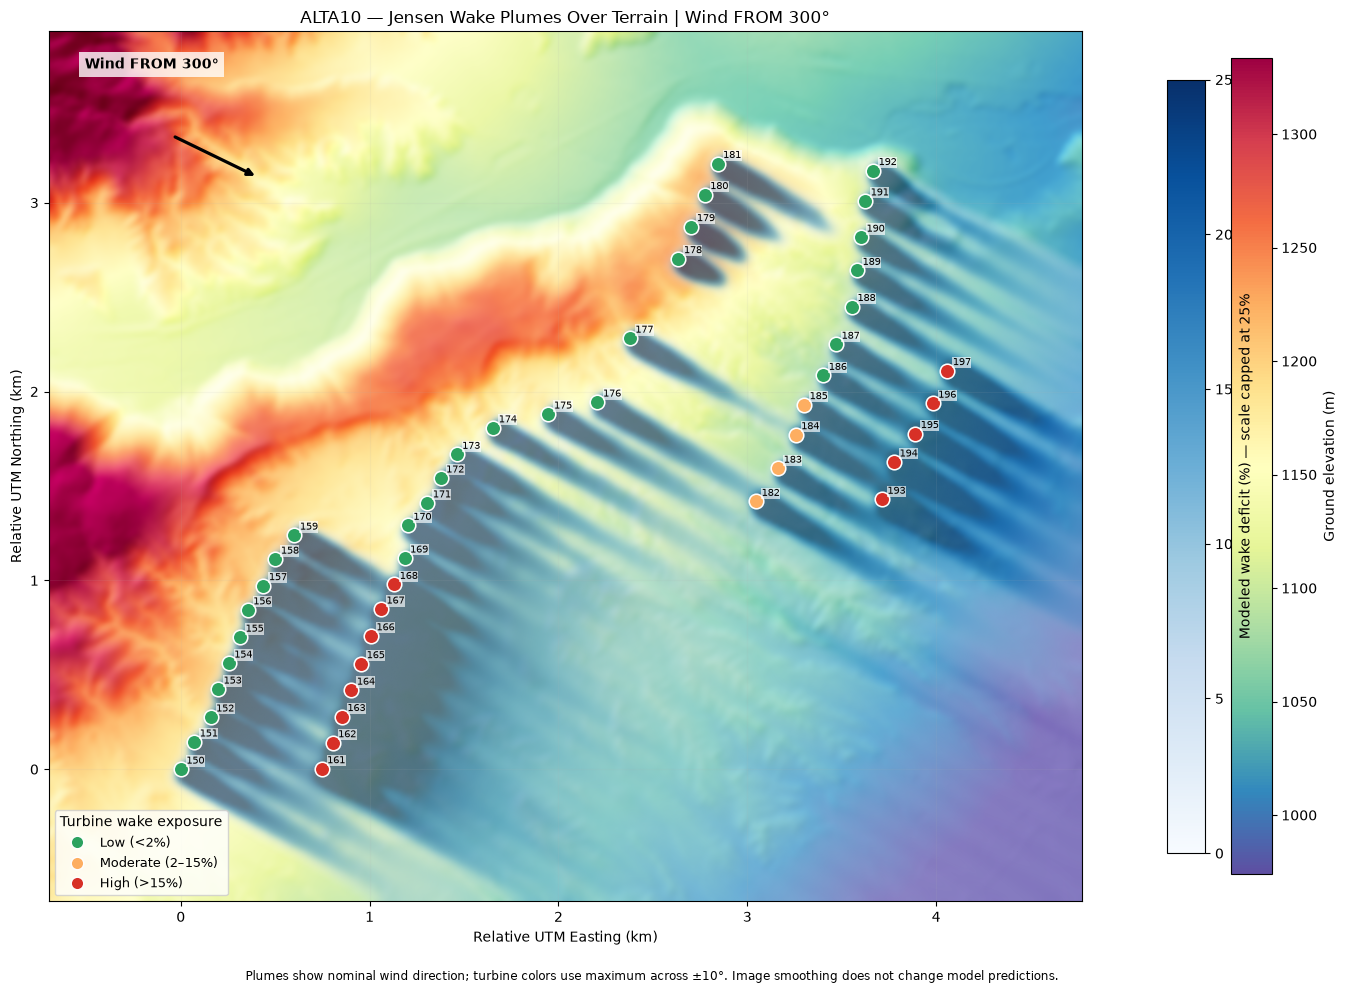


Jensen wake classification:
wake_category
LOW         30
HIGH        13
MODERATE     4
Name: count, dtype: int64
Saved map: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\12_farmwide_wake_exposure\integrated_smooth_maps\ALTA10_jensen_terrain_plumes_300deg_high15.png

jensen: Top 10 most frequently high-wake turbines


,turbine,low_pct,moderate_pct,high_pct,valid_mast_records
16,WTG167,3.79,1.46,94.75,20832
14,WTG165,3.97,1.55,94.48,20832
15,WTG166,3.97,1.55,94.48,20832
13,WTG164,4.22,1.59,94.18,20832
12,WTG163,4.53,1.58,93.89,20832
11,WTG162,5.16,1.03,93.81,20832
43,WTG194,5.37,0.83,93.80,20832
45,WTG196,6.74,0.00,93.26,20832
46,WTG197,6.85,0.00,93.15,20832
44,WTG195,7.21,0.00,92.79,20832



Calculating gaussian_style model...


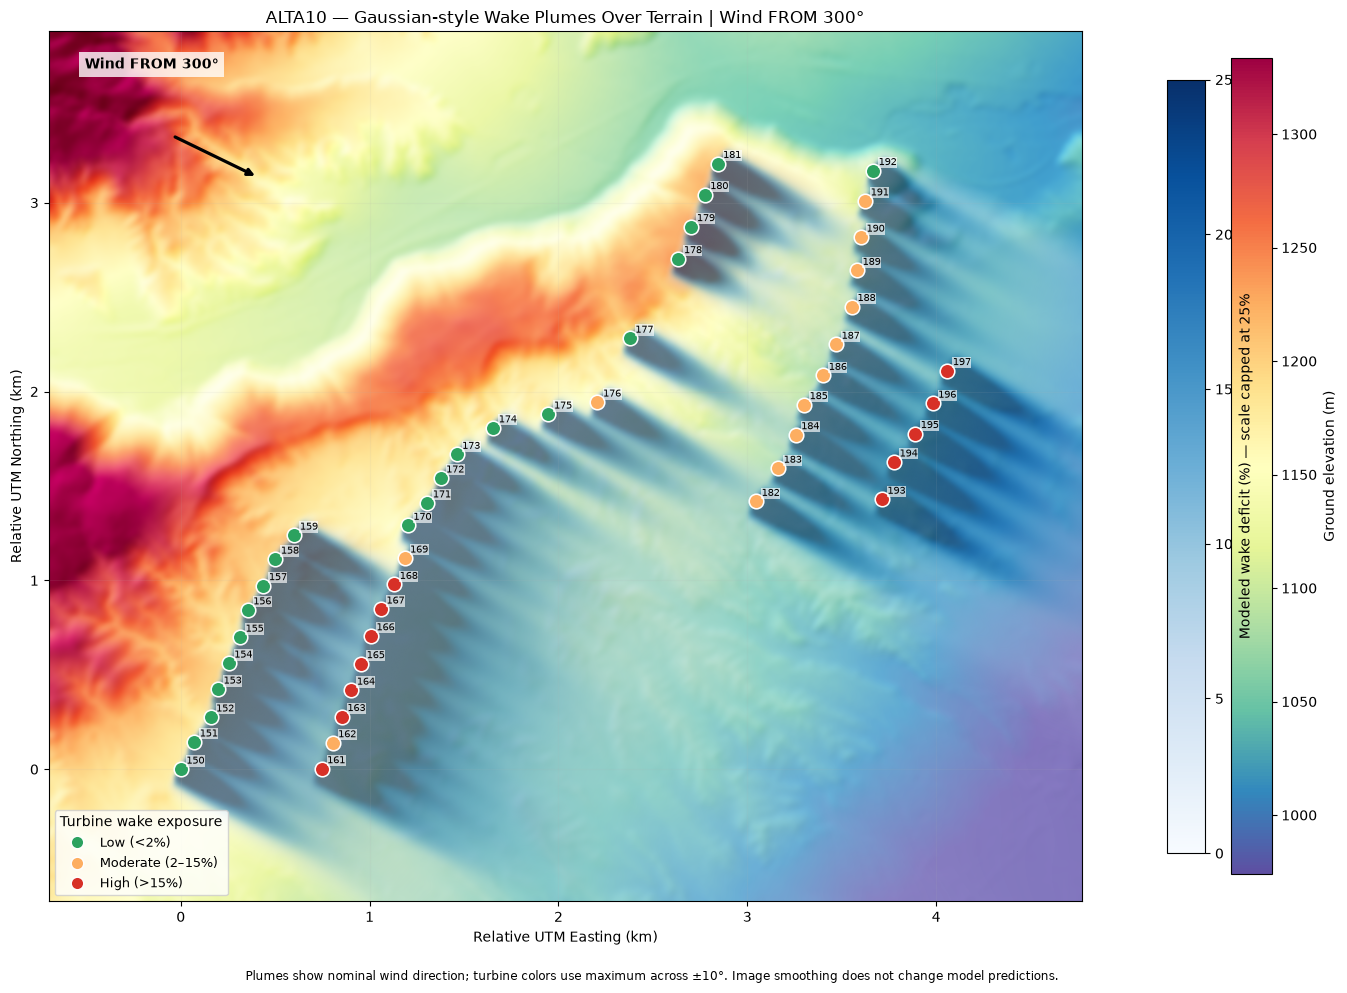


Gaussian-style wake classification:
wake_category
LOW         22
MODERATE    13
HIGH        12
Name: count, dtype: int64
Saved map: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\12_farmwide_wake_exposure\integrated_smooth_maps\ALTA10_gaussian_style_terrain_plumes_300deg_high15.png

gaussian_style: Top 10 most frequently high-wake turbines


,turbine,low_pct,moderate_pct,high_pct,valid_mast_records
16,WTG167,1.25,3.15,95.60,20832
12,WTG163,1.21,3.40,95.39,20832
13,WTG164,1.21,3.40,95.39,20832
14,WTG165,1.44,3.20,95.36,20832
15,WTG166,1.49,3.30,95.21,20832
43,WTG194,2.15,3.23,94.63,20832
45,WTG196,3.41,2.35,94.24,20832
44,WTG195,3.41,2.40,94.19,20832
46,WTG197,4.93,1.13,93.95,20832
17,WTG168,1.70,8.86,89.44,20832


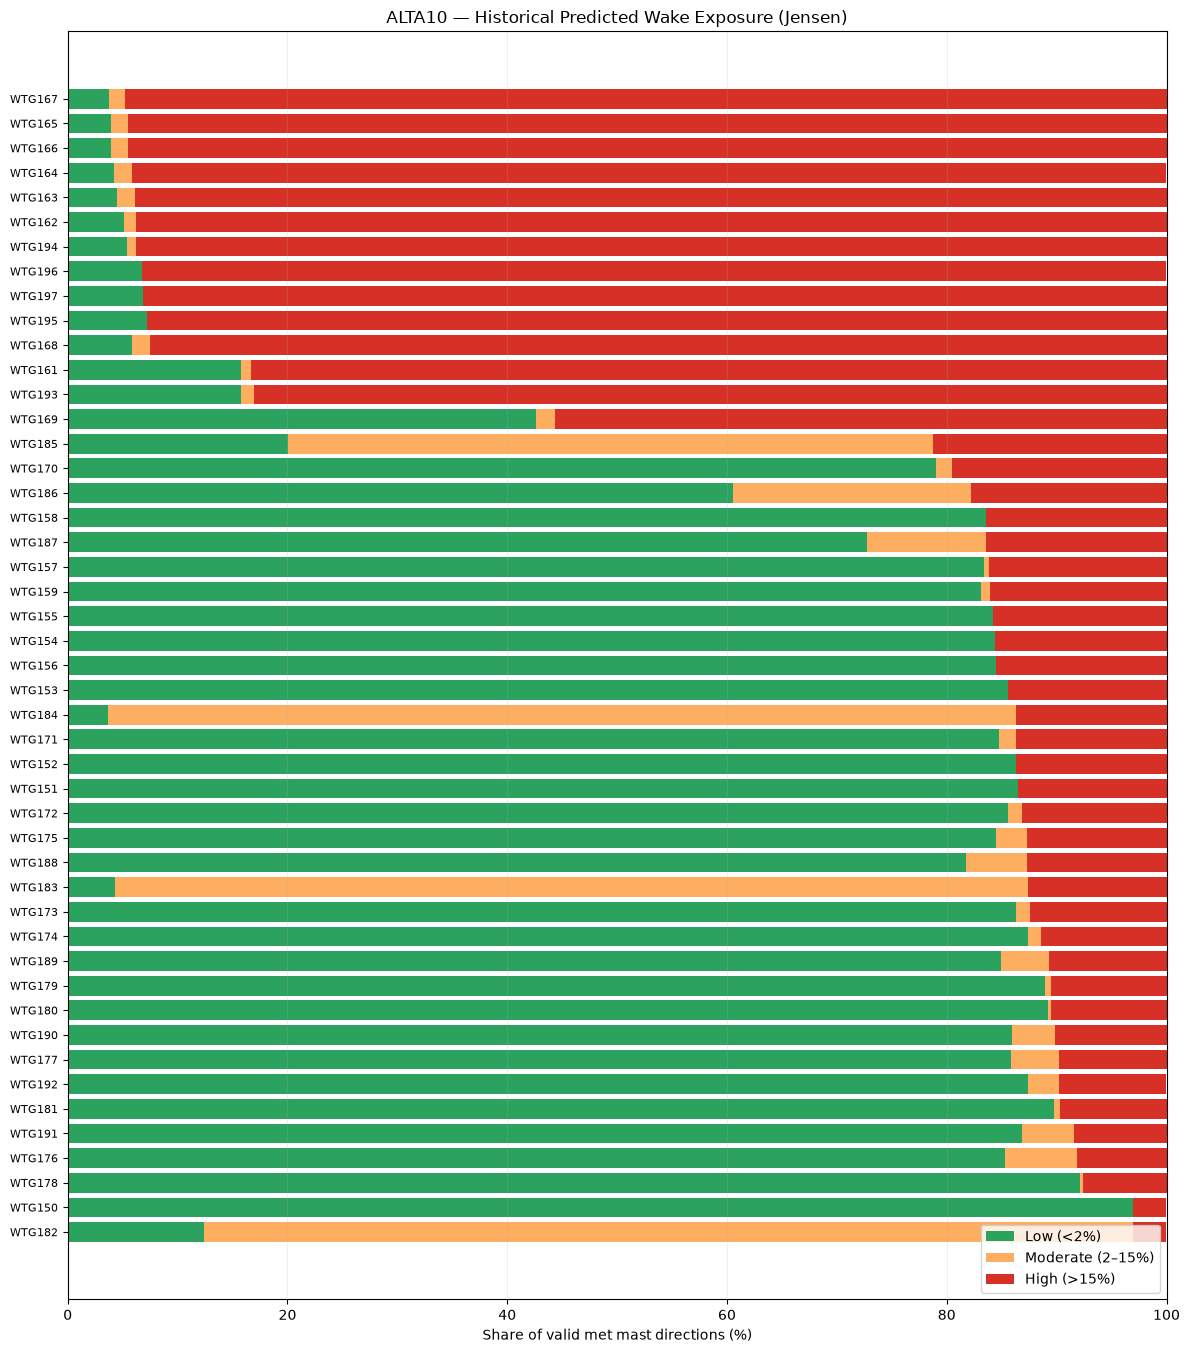

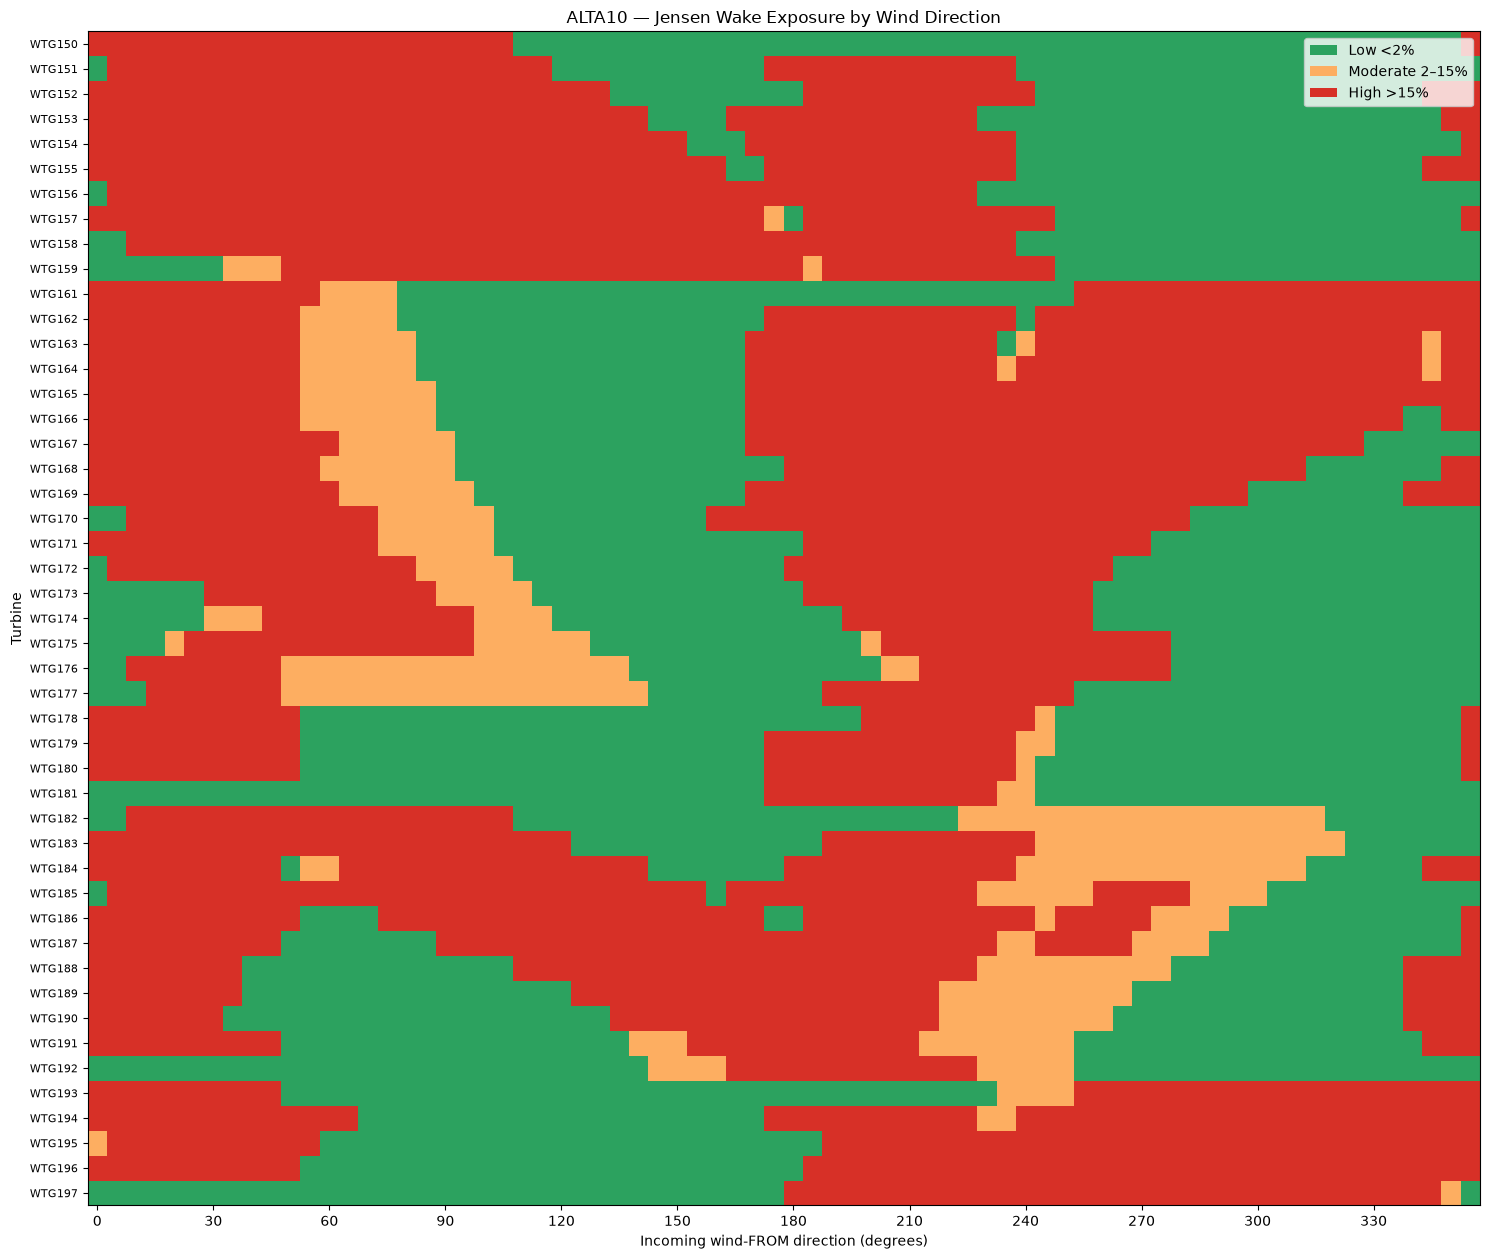


ALTA10 INTEGRATED WAKE ANALYSIS COMPLETE

All maps, rankings, and CSV files saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\12_farmwide_wake_exposure\integrated_smooth_maps

Wake classifications use original model calculations.
Smoothing affects the maps only.
No LiDAR k-proxy values are displayed.


In [15]:

# ==============================================================
# ALTA10 | COMPLETE FARM-WIDE WAKE VISUALIZATION
#
# ONE STANDALONE CELL — no previous notebook cells needed.
#
# Outputs:
# 1. Smooth Jensen wake map over terrain
# 2. Smooth Gaussian-style wake map over terrain
# 3. Historical wake exposure ranking
# 4. Wind-direction wake heatmap
# 5. Turbine classifications saved to CSV
#
# Low wake:      < 2%
# Moderate wake: 2% to 15%
# High wake:     > 15%
#
# Turbine labels retained. No LiDAR k-proxy labels.
# ==============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from rasterio.warp import (
    reproject,
    Resampling,
    transform as rio_transform
)
from rasterio.transform import from_origin
from pyproj import Transformer
from scipy.ndimage import gaussian_filter
from matplotlib.colors import (
    Normalize,
    ListedColormap,
    LightSource
)
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

# ==============================================================
# 1. SETTINGS
# ==============================================================

PROJECT = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

# Change the direction to view different wake conditions.
WIND_FROM_DEG = 300.0

# Dates used for historical exposure percentages.
START_DATE = "2026-05-01"
END_DATE_EXCLUSIVE = "2026-10-01"

GRID_RESOLUTION_M = 18.0
MAP_PADDING_M = 700.0

LOW_WAKE_PCT = 2.0
HIGH_WAKE_PCT = 15.0

# Existing simplified wake model parameters.
ROTOR_DIAMETER_M = 103.0
HUB_HEIGHT_M = 85.0
WAKE_EXPANSION = 0.05
ASSUMED_INFLOW_MS = 8.2

DIRECTION_OFFSETS_DEG = [-10, -5, 0, 5, 10]

CT_SPEEDS = np.array([
    3, 4, 5, 6, 7, 8, 9, 10,
    11, 12, 12.5, 14, 16, 18, 20, 25
], dtype=float)

CT_VALUES = np.array([
    .95, .92, .88, .83, .80, .77, .70, .58,
    .44, .31, .25, .16, .11, .08, .06, .03
], dtype=float)

CT = float(
    np.interp(
        ASSUMED_INFLOW_MS,
        CT_SPEEDS,
        CT_VALUES
    )
)

DIRECTIONS = np.arange(0, 360, 5)

MODELS = [
    "jensen",
    "gaussian_style"
]

CATEGORY_COLORS = {
    "LOW": "#2ca25f",
    "MODERATE": "#fdae61",
    "HIGH": "#d73027"
}

OUTPUT = (
    PROJECT
    / "data/processed/12_farmwide_wake_exposure"
    / "integrated_smooth_maps"
)

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

# ==============================================================
# 2. FILE AND TURBINE HELPERS
# ==============================================================

def find_source(filename):

    hits = sorted(
        (PROJECT / "data").rglob(filename)
    )

    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename} "
            f"under data/; found {len(hits)}"
        )

    return hits[0]


def turbine_id(value):

    match = re.fullmatch(
        r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?",
        str(value).strip().upper()
    )

    if match is None:
        raise ValueError(
            f"Unknown turbine ID: {value!r}"
        )

    return f"WTG{int(match.group(1))}"


# ==============================================================
# 3. LOAD ALL TURBINES AND ELEVATION TIFF
# ==============================================================

coords = pd.read_csv(
    find_source("turbine_coordinate_ALTA10.csv")
)

required = {
    "Turbine_ID",
    "Latitude",
    "Longitude"
}

if not required.issubset(coords.columns):
    raise KeyError(
        f"Coordinate CSV missing: "
        f"{required - set(coords.columns)}"
    )

coords["turbine"] = (
    coords["Turbine_ID"].map(turbine_id)
)

coords["Latitude"] = pd.to_numeric(
    coords["Latitude"], errors="raise"
)

coords["Longitude"] = pd.to_numeric(
    coords["Longitude"], errors="raise"
)

if coords.turbine.duplicated().any():
    raise ValueError(
        "Duplicate turbine IDs in coordinate file."
    )

coords["_id_num"] = (
    coords.turbine
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

coords = (
    coords.sort_values("_id_num")
    .reset_index(drop=True)
)

# Convert to UTM Zone 11N.
projection = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32611",
    always_xy=True
)

coords["x"], coords["y"] = projection.transform(
    coords.Longitude.to_numpy(),
    coords.Latitude.to_numpy()
)

# Load ground elevation at each turbine.
tif_path = find_source("elevation.tif")

with rasterio.open(tif_path) as dem:

    if dem.crs is None:
        raise ValueError(
            "Elevation TIFF has no CRS."
        )

    sx, sy = rio_transform(
        "EPSG:32611",
        dem.crs,
        coords.x.tolist(),
        coords.y.tolist()
    )

    samples = list(
        dem.sample(
            zip(sx, sy),
            masked=True
        )
    )

    coords["elevation_m"] = [
        np.nan if np.ma.is_masked(s[0])
        else float(s[0])
        for s in samples
    ]

if not np.isfinite(
    coords.elevation_m
).all():
    raise ValueError(
        "Invalid elevation at one or more turbines."
    )

x = coords.x.to_numpy(float)
y = coords.y.to_numpy(float)
z = coords.elevation_m.to_numpy(float)

names = coords.turbine.to_numpy()

# ==============================================================
# 4. PREPARE THE TERRAIN MAP GRID
# ==============================================================

xmin = x.min() - MAP_PADDING_M
xmax = x.max() + MAP_PADDING_M

ymin = y.min() - MAP_PADDING_M
ymax = y.max() + MAP_PADDING_M

nx = int(
    np.ceil(
        (xmax - xmin) / GRID_RESOLUTION_M
    )
)

ny = int(
    np.ceil(
        (ymax - ymin) / GRID_RESOLUTION_M
    )
)

if nx * ny > 2_500_000:
    raise ValueError(
        "Map grid is too large. "
        "Increase GRID_RESOLUTION_M to approximately 25."
    )

raster_transform = from_origin(
    xmin,
    ymax,
    GRID_RESOLUTION_M,
    GRID_RESOLUTION_M
)

terrain = np.full(
    (ny, nx),
    np.nan,
    dtype=np.float32
)

with rasterio.open(tif_path) as dem:

    reproject(
        source=rasterio.band(dem, 1),
        destination=terrain,
        src_transform=dem.transform,
        src_crs=dem.crs,
        src_nodata=dem.nodata,
        dst_transform=raster_transform,
        dst_crs="EPSG:32611",
        dst_nodata=np.nan,
        resampling=Resampling.bilinear
    )

valid = np.isfinite(terrain)

if not valid.any():
    raise ValueError(
        "Elevation raster does not overlap the farm."
    )

# Coordinates of terrain grid pixel centers.
xvec = (
    xmin
    + (np.arange(nx) + 0.5)
    * GRID_RESOLUTION_M
)

yvec = (
    ymax
    - (np.arange(ny) + 0.5)
    * GRID_RESOLUTION_M
)

X = xvec[None, :].astype(np.float32)
Y = yvec[:, None].astype(np.float32)

# Relative coordinates for plotting.
x0 = x.min()
y0 = y.min()

plot_extent = (
    (xmin - x0) / 1000,
    (xmin + nx * GRID_RESOLUTION_M - x0) / 1000,
    (ymax - ny * GRID_RESOLUTION_M - y0) / 1000,
    (ymax - y0) / 1000
)

site_east_km = (x - x0) / 1000
site_north_km = (y - y0) / 1000

# ==============================================================
# 5. SMOOTH TERRAIN BACKGROUND
# ==============================================================

valid_z = terrain[valid]

zmin, zmax = np.percentile(
    valid_z,
    [2, 98]
)

if zmax <= zmin:
    zmax = zmin + 1

terrain_norm = Normalize(
    vmin=zmin,
    vmax=zmax
)

terrain_cmap = plt.get_cmap(
    "Spectral_r"
)

# Light hillshade maintains terrain detail.
background = LightSource(
    azdeg=315,
    altdeg=45
).shade(
    np.where(
        valid,
        terrain,
        float(np.median(valid_z))
    ),
    cmap=terrain_cmap,
    norm=terrain_norm,
    dx=GRID_RESOLUTION_M,
    dy=GRID_RESOLUTION_M,
    vert_exag=1.0,
    blend_mode="soft"
)

background[..., 3] = np.where(
    valid,
    1.0,
    0.0
)

print(
    f"Loaded {len(coords)} turbines "
    f"and elevation grid {nx} x {ny}."
)

# ==============================================================
# 6. MODEL WAKE PLUMES ACROSS THE TERRAIN GRID
# ==============================================================

def spatial_wake_pct(model, wind_from):

    theta = np.deg2rad(
        wind_from % 360
    )

    # Meteorological wind FROM -> downwind.
    down_x = -np.sin(theta)
    down_y = -np.cos(theta)

    total_sq = np.zeros(
        (ny, nx),
        dtype=np.float32
    )

    for source in coords.itertuples(index=False):

        east = X - source.x
        north = Y - source.y

        along = (
            east * down_x
            + north * down_y
        )

        across = (
            -east * down_y
            + north * down_x
        )

        positive = np.maximum(
            along,
            0
        )

        radius = (
            ROTOR_DIAMETER_M / 2
            + WAKE_EXPANSION * positive
        )

        center = (
            (1 - np.sqrt(1 - CT))
            /
            (
                1
                + 2 * WAKE_EXPANSION
                * positive / ROTOR_DIAMETER_M
            ) ** 2
        )

        # Identical hub heights cancel.
        vertical = (
            terrain - source.elevation_m
        )

        if model == "jensen":

            deficit = np.where(
                (along > 0)
                & (
                    np.hypot(across, vertical)
                    <= radius
                ),
                center,
                0
            )

        elif model == "gaussian_style":

            taper = np.exp(
                -0.5 * (
                    (across / radius) ** 2
                    + (vertical / radius) ** 2
                )
            )

            deficit = np.where(
                along > 0,
                center * taper,
                0
            )

        else:
            raise ValueError(
                f"Unknown model: {model}"
            )

        total_sq += np.where(
            valid,
            deficit ** 2,
            0
        ).astype(np.float32)

    result = (
        100
        * np.minimum(
            np.sqrt(total_sq),
            1.0
        )
    )

    result[~valid] = np.nan

    return result


# ==============================================================
# 7. CALCULATE WAKE EXPOSURE AT EACH TURBINE
# ==============================================================

# Rows represent upstream turbine sources.
# Columns represent receiving turbines.

east_pairs = (
    x[None, :] - x[:, None]
)

north_pairs = (
    y[None, :] - y[:, None]
)

vertical_pairs = (
    z[None, :] - z[:, None]
)


def receiver_wake_pct(model, wind_from):

    theta = np.deg2rad(
        wind_from % 360
    )

    down_x = -np.sin(theta)
    down_y = -np.cos(theta)

    along = (
        east_pairs * down_x
        + north_pairs * down_y
    )

    across = (
        -east_pairs * down_y
        + north_pairs * down_x
    )

    positive = np.maximum(
        along,
        0
    )

    radius = (
        ROTOR_DIAMETER_M / 2
        + WAKE_EXPANSION * positive
    )

    center = (
        (1 - np.sqrt(1 - CT))
        /
        (
            1
            + 2 * WAKE_EXPANSION
            * positive / ROTOR_DIAMETER_M
        ) ** 2
    )

    if model == "jensen":

        delta = np.where(
            (along > 0)
            & (
                np.hypot(
                    across,
                    vertical_pairs
                ) <= radius
            ),
            center,
            0
        )

    elif model == "gaussian_style":

        taper = np.exp(
            -0.5 * (
                (across / radius) ** 2
                + (vertical_pairs / radius) ** 2
            )
        )

        delta = np.where(
            along > 0,
            center * taper,
            0
        )

    else:
        raise ValueError(model)

    # No self-wake contribution.
    np.fill_diagonal(
        delta,
        0
    )

    return (
        100
        * np.minimum(
            np.sqrt(
                np.sum(
                    delta ** 2,
                    axis=0
                )
            ),
            1.0
        )
    )


def max_direction_offset_wake(lookup, angles):

    angles = np.asarray(
        angles,
        dtype=float
    ).reshape(-1)

    # Maximum deficit across ±10 degree sensitivity.
    return np.maximum.reduce([
        lookup[
            np.floor(
                (
                    (angles + offset) % 360
                    + 2.5
                ) / 5
            ).astype(int) % 72
        ]
        for offset in DIRECTION_OFFSETS_DEG
    ])


def categories(values):

    return np.where(
        values < LOW_WAKE_PCT,
        "LOW",
        np.where(
            values > HIGH_WAKE_PCT,
            "HIGH",
            "MODERATE"
        )
    )


# ==============================================================
# 8. LOAD HISTORICAL MET-MAST DIRECTIONS
# ==============================================================

mast_path = (
    PROJECT
    / "data/processed/metmasts_data.parquet"
)

mast = pd.read_parquet(
    mast_path
)

if not any(
    col in mast.columns
    for col in ["timestamp", "utc"]
):
    mast = mast.reset_index()

time_col = next(
    (
        col
        for col in ["timestamp", "utc"]
        if col in mast.columns
    ),
    None
)

if time_col is None:
    raise KeyError(
        "Mast file has no timestamp or utc column."
    )

needed = {
    "mm_wind_speed_3",
    "mm_wind_direction_3"
}

if not needed.issubset(mast.columns):
    raise KeyError(
        f"Missing mast columns: "
        f"{needed - set(mast.columns)}"
    )

mast["timestamp"] = pd.to_datetime(
    mast[time_col],
    utc=True,
    errors="coerce"
)

for col in needed:

    mast[col] = pd.to_numeric(
        mast[col],
        errors="coerce"
    )

mast = mast.loc[
    (
        mast.timestamp
        >= pd.Timestamp(START_DATE, tz="UTC")
    )
    & (
        mast.timestamp
        < pd.Timestamp(END_DATE_EXCLUSIVE, tz="UTC")
    )
    & mast.mm_wind_speed_3.between(3, 25)
    & mast.mm_wind_direction_3.between(0, 360)
].copy()

if mast.empty:
    raise ValueError(
        "No valid mast observations in selected date range."
    )

if mast.timestamp.duplicated().any():
    raise ValueError(
        "Duplicate met-mast timestamps."
    )

historical_directions = (
    mast.mm_wind_direction_3.to_numpy()
)

print(
    f"Historical exposure uses "
    f"{len(mast):,} valid mast readings."
)

# ==============================================================
# 9. DISPLAY-ONLY SMOOTHING
# ==============================================================

def smooth_for_display(data, sigma):

    is_valid = np.isfinite(data)

    numerator = gaussian_filter(
        np.where(
            is_valid,
            data,
            0.0
        ),
        sigma=sigma
    )

    denominator = gaussian_filter(
        is_valid.astype(float),
        sigma=sigma
    )

    result = (
        numerator
        / np.maximum(
            denominator,
            1e-6
        )
    )

    result[~is_valid] = np.nan

    return result


def blue_plume_rgba(values):

    # Colors saturate at 25% for display.
    display_scale = 25.0

    rgba = plt.get_cmap("Blues")(
        np.clip(
            np.nan_to_num(
                values,
                nan=0
            ) / display_scale,
            0,
            1
        )
    )

    # Gradual opacity creates softer plume edges.
    strength = np.clip(
        (values - 0.4) / 14,
        0,
        1
    )

    rgba[..., 3] = np.where(
        np.isfinite(values),
        0.64 * strength ** 0.7,
        0.0
    )

    return rgba


# ==============================================================
# 10. PLOT SMOOTH WAKE MAP
# ==============================================================

def draw_map(model, lookup):

    # Unsmoothed wake calculations.
    direct = spatial_wake_pct(
        model,
        WIND_FROM_DEG
    )

    # Only the displayed image is smoothed.
    sigma = (
        1.8
        if model == "jensen"
        else 0.7
    )

    smoothed = smooth_for_display(
        direct,
        sigma
    )

    plume_image = blue_plume_rgba(
        smoothed
    )

    # Turbine categories use unsmoothed model results.
    classified = max_direction_offset_wake(
        lookup,
        [WIND_FROM_DEG]
    )[0]

    groups = categories(
        classified
    )

    fig, ax = plt.subplots(
        figsize=(14, 10)
    )

    # Terrain background.
    ax.imshow(
        background,
        extent=plot_extent,
        origin="upper",
        interpolation="bicubic",
        zorder=0
    )

    # Smooth blue wake plumes.
    ax.imshow(
        plume_image,
        extent=plot_extent,
        origin="upper",
        interpolation="bicubic",
        zorder=1
    )

    # ----------------------------------------------------------
    # Turbine markers
    # ----------------------------------------------------------

    for group in [
        "LOW",
        "MODERATE",
        "HIGH"
    ]:

        selected = groups == group

        ax.scatter(
            site_east_km[selected],
            site_north_km[selected],
            color=CATEGORY_COLORS[group],
            s=110,
            edgecolors="white",
            linewidths=1.15,
            zorder=5
        )

    # Label every turbine.
    # Example: 159 represents WTG159.
    for i, name in enumerate(names):

        ax.annotate(
            name.replace("WTG", ""),
            (
                site_east_km[i],
                site_north_km[i]
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7.3,
            color="black",
            bbox=dict(
                facecolor="white",
                alpha=0.65,
                edgecolor="none",
                pad=0.4
            ),
            zorder=6
        )

    # ----------------------------------------------------------
    # Wind direction arrow
    # ----------------------------------------------------------

    theta = np.deg2rad(
        WIND_FROM_DEG
    )

    arrow_x = -np.sin(theta)
    arrow_y = -np.cos(theta)

    ax.annotate(
        "",
        xy=(
            0.12 + 0.095 * arrow_x,
            0.88 + 0.095 * arrow_y
        ),
        xytext=(0.12, 0.88),
        xycoords="axes fraction",
        arrowprops=dict(
            arrowstyle="-|>",
            lw=2.3,
            color="black"
        ),
        zorder=8
    )

    ax.text(
        0.035,
        0.97,
        f"Wind FROM {WIND_FROM_DEG:.0f}°",
        transform=ax.transAxes,
        va="top",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

    # ----------------------------------------------------------
    # Legend
    # ----------------------------------------------------------

    legend_items = []

    for category, label in [
        ("LOW", "Low (<2%)"),
        ("MODERATE", "Moderate (2–15%)"),
        ("HIGH", "High (>15%)")
    ]:

        legend_items.append(
            Line2D(
                [0], [0],
                marker="o",
                linestyle="none",
                markersize=9,
                markerfacecolor=CATEGORY_COLORS[category],
                markeredgecolor="white",
                label=label
            )
        )

    ax.legend(
        handles=legend_items,
        title="Turbine wake exposure",
        loc="lower left",
        fontsize=9
    )

    # ----------------------------------------------------------
    # Terrain and wake colorbars
    # ----------------------------------------------------------

    terrain_mapper = ScalarMappable(
        norm=terrain_norm,
        cmap=terrain_cmap
    )

    terrain_mapper.set_array([])

    fig.colorbar(
        terrain_mapper,
        ax=ax,
        fraction=0.032,
        pad=0.02
    ).set_label(
        "Ground elevation (m)"
    )

    wake_mapper = ScalarMappable(
        norm=Normalize(0, 25),
        cmap="Blues"
    )

    wake_mapper.set_array([])

    fig.colorbar(
        wake_mapper,
        ax=ax,
        fraction=0.032,
        pad=0.07
    ).set_label(
        "Modeled wake deficit (%) — "
        "scale capped at 25%"
    )

    # ----------------------------------------------------------
    # Formatting
    # ----------------------------------------------------------

    model_label = (
        "Jensen"
        if model == "jensen"
        else "Gaussian-style"
    )

    ax.set(
        title=(
            f"ALTA10 — {model_label} Wake Plumes "
            f"Over Terrain | Wind FROM {WIND_FROM_DEG:.0f}°"
        ),
        xlabel="Relative UTM Easting (km)",
        ylabel="Relative UTM Northing (km)"
    )

    ax.set_aspect("equal")
    ax.grid(alpha=0.1)

    fig.text(
        0.5,
        0.015,
        "Plumes show nominal wind direction; "
        "turbine colors use maximum across ±10°. "
        "Image smoothing does not change model predictions.",
        ha="center",
        fontsize=8.5
    )

    fig.tight_layout(
        rect=[0, 0.035, 1, 1]
    )

    filename = (
        OUTPUT
        / (
            f"ALTA10_{model}_terrain_plumes_"
            f"{int(WIND_FROM_DEG):03d}deg_high15.png"
        )
    )

    fig.savefig(
        filename,
        dpi=190,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Save the actual numerical turbine predictions.
    result = pd.DataFrame({
        "turbine": names,
        "model": model,
        "predicted_wake_deficit_pct": classified,
        "wake_category": groups
    })

    result.to_csv(
        OUTPUT / f"{model}_turbine_snapshot_high15.csv",
        index=False
    )

    print(
        f"\n{model_label} wake classification:"
    )

    print(
        result.wake_category.value_counts()
    )

    print("Saved map:", filename)

    return result


# ==============================================================
# 11. RUN BOTH WAKE MODELS
# ==============================================================

lookups = {}
summary_tables = {}
snapshot_tables = {}

for model in MODELS:

    print(
        f"\nCalculating {model} model..."
    )

    # Model every turbine at every 5-degree direction.
    lookup = np.stack([
        receiver_wake_pct(
            model,
            angle
        )
        for angle in DIRECTIONS
    ])

    lookups[model] = lookup

    # Generate the integrated terrain/wake map.
    snapshot_tables[model] = draw_map(
        model,
        lookup
    )

    # Historical wake exposure at recorded mast directions.
    exposure = max_direction_offset_wake(
        lookup,
        historical_directions
    )

    summary = pd.DataFrame({
        "turbine": names,

        "low_pct":
            100 * (
                exposure < LOW_WAKE_PCT
            ).mean(axis=0),

        "moderate_pct":
            100 * (
                (exposure >= LOW_WAKE_PCT)
                & (exposure <= HIGH_WAKE_PCT)
            ).mean(axis=0),

        "high_pct":
            100 * (
                exposure > HIGH_WAKE_PCT
            ).mean(axis=0),

        "valid_mast_records":
            len(historical_directions)
    })

    summary = summary.sort_values(
        "high_pct",
        ascending=False
    )

    summary.to_csv(
        OUTPUT / f"{model}_historical_exposure_high15.csv",
        index=False
    )

    summary_tables[model] = summary

    print(
        f"\n{model}: Top 10 most frequently "
        "high-wake turbines"
    )

    display(
        summary.head(10).round(2)
    )


# ==============================================================
# 12. HISTORICAL WAKE EXPOSURE RANKING — JENSEN
# ==============================================================

rank = summary_tables["jensen"].iloc[::-1]

positions = np.arange(
    len(rank)
)

low = rank.low_pct.to_numpy()
moderate = rank.moderate_pct.to_numpy()
high = rank.high_pct.to_numpy()

fig, ax = plt.subplots(
    figsize=(
        12,
        max(10, len(rank) * 0.29)
    )
)

ax.barh(
    positions,
    low,
    color=CATEGORY_COLORS["LOW"],
    label="Low (<2%)"
)

ax.barh(
    positions,
    moderate,
    left=low,
    color=CATEGORY_COLORS["MODERATE"],
    label="Moderate (2–15%)"
)

ax.barh(
    positions,
    high,
    left=low + moderate,
    color=CATEGORY_COLORS["HIGH"],
    label="High (>15%)"
)

ax.set(
    yticks=positions,
    yticklabels=rank.turbine,
    xlim=(0, 100),
    xlabel="Share of valid met mast directions (%)",
    title=(
        "ALTA10 — Historical Predicted "
        "Wake Exposure (Jensen)"
    )
)

ax.tick_params(
    axis="y",
    labelsize=8
)

ax.legend(
    loc="lower right"
)

ax.grid(
    axis="x",
    alpha=0.2
)

fig.tight_layout()

fig.savefig(
    OUTPUT / "ALTA10_Jensen_historical_wake_ranking_high15.png",
    dpi=190,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==============================================================
# 13. WIND-DIRECTION HEATMAP — JENSEN
# ==============================================================

jensen_offsets = max_direction_offset_wake(
    lookups["jensen"],
    DIRECTIONS
)

classes = np.where(
    jensen_offsets < LOW_WAKE_PCT,
    0,
    np.where(
        jensen_offsets > HIGH_WAKE_PCT,
        2,
        1
    )
).T

fig, ax = plt.subplots(
    figsize=(
        15,
        max(10, len(names) * 0.27)
    )
)

ax.imshow(
    classes,
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap([
        CATEGORY_COLORS["LOW"],
        CATEGORY_COLORS["MODERATE"],
        CATEGORY_COLORS["HIGH"]
    ]),
    vmin=-0.5,
    vmax=2.5
)

ax.set(
    yticks=np.arange(len(names)),
    yticklabels=names,
    xticks=np.arange(0, 72, 6),
    xticklabels=DIRECTIONS[::6],
    xlabel="Incoming wind-FROM direction (degrees)",
    ylabel="Turbine",
    title=(
        "ALTA10 — Jensen Wake Exposure "
        "by Wind Direction"
    )
)

ax.tick_params(
    axis="y",
    labelsize=8
)

ax.legend(
    handles=[
        Patch(
            facecolor=CATEGORY_COLORS[category],
            label=label
        )
        for category, label in [
            ("LOW", "Low <2%"),
            ("MODERATE", "Moderate 2–15%"),
            ("HIGH", "High >15%")
        ]
    ],
    loc="upper right"
)

fig.tight_layout()

fig.savefig(
    OUTPUT / "ALTA10_Jensen_wake_direction_heatmap_high15.png",
    dpi=190,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==============================================================
# 14. COMPLETE
# ==============================================================

print("\n" + "=" * 65)
print("ALTA10 INTEGRATED WAKE ANALYSIS COMPLETE")
print("=" * 65)

print("\nAll maps, rankings, and CSV files saved to:")
print(OUTPUT)

print(
    "\nWake classifications use original model calculations."
    "\nSmoothing affects the maps only."
    "\nNo LiDAR k-proxy values are displayed."
)


In [ ]:

# ===============================================================
# ALTA10 — TURBINE WAKE-DIRECTION DATASETS
#
# Creates:
# 1. Direction lookup: every turbine x every 5 degrees
# 2. Direction lists: LOW / MODERATE / HIGH for each turbine
# 3. Historical observations: every mast timestamp x turbine
#
# Includes Jensen and Gaussian-style predictions.
# Uses existing model calculations, without modifying them.
#
# LOW:      deficit < 2%
# MODERATE: 2% <= deficit <= 15%
# HIGH:     deficit > 15%
# ===============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ---------------------------------------------------------------
# 1. Check existing wake model results
# ---------------------------------------------------------------

required = [
    "lookups",
    "names",
    "DIRECTIONS",
    "max_direction_offset_wake",
    "mast",
    "OUTPUT"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the integrated farm-wide wake analysis first. "
        f"Missing: {missing}"
    )

SAVE_DIR = Path(OUTPUT)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

LOW_LIMIT = 2.0
HIGH_LIMIT = 15.0

turbines = np.asarray(names)
directions = np.asarray(DIRECTIONS, dtype=int)

N_TURBINES = len(turbines)
N_DIRECTIONS = len(directions)

def classify_wake(values):
    values = np.asarray(values, dtype=float)
    return np.where(
        values < LOW_LIMIT,
        "LOW",
        np.where(
            values > HIGH_LIMIT,
            "HIGH",
            "MODERATE"
        )
    )

# ---------------------------------------------------------------
# 2. Build complete wind-direction lookup
# ---------------------------------------------------------------

lookup_tables = []

for model in ["jensen", "gaussian_style"]:

    if model not in lookups:
        raise KeyError(f"Model not found: {model}")

    # Shape: 72 directions x 47 turbines
    nominal = np.asarray(lookups[model])

    if nominal.shape != (N_DIRECTIONS, N_TURBINES):
        raise ValueError(
            f"Unexpected lookup shape for {model}: "
            f"{nominal.shape}"
        )

    # Maximum modeled deficit over offsets
    # -10, -5, 0, +5, +10 degrees.
    conservative = max_direction_offset_wake(
        nominal,
        directions
    )

    table = pd.DataFrame({
        "model": model,

        "turbine": np.tile(
            turbines, N_DIRECTIONS
        ),

        "wind_from_deg": np.repeat(
            directions, N_TURBINES
        ),

        "nominal_deficit_pct":
            nominal.reshape(-1),

        "max_offset_deficit_pct":
            conservative.reshape(-1),

        "wake_category":
            classify_wake(
                conservative.reshape(-1)
            )
    })

    lookup_tables.append(table)

wake_lookup = pd.concat(
    lookup_tables,
    ignore_index=True
)

wake_lookup = wake_lookup.sort_values(
    ["model", "turbine", "wind_from_deg"]
).reset_index(drop=True)

lookup_path = (
    SAVE_DIR / "ALTA10_wake_direction_lookup_5deg.csv"
)

wake_lookup.to_csv(
    lookup_path,
    index=False
)

print("\nCOMPLETE DIRECTION LOOKUP")
print(f"Rows: {len(wake_lookup):,}")
print("Saved:", lookup_path)

display(wake_lookup.head(15).round(2))

# ---------------------------------------------------------------
# 3. Create readable direction lists for each turbine
# ---------------------------------------------------------------

# Example:
# WTG159 | HIGH | 260, 265, 270, 275 ...
#
# Each value is the CENTER of a 5-degree direction bin.

direction_lists = (
    wake_lookup
    .groupby(
        ["model", "turbine", "wake_category"]
    )["wind_from_deg"]
    .apply(
        lambda s: ", ".join(
            f"{int(v)}°" for v in sorted(s)
        )
    )
    .unstack(fill_value="")
    .reset_index()
)

for category in ["LOW", "MODERATE", "HIGH"]:
    if category not in direction_lists:
        direction_lists[category] = ""

direction_lists = direction_lists[
    ["model", "turbine", "LOW", "MODERATE", "HIGH"]
]

lists_path = (
    SAVE_DIR / "ALTA10_wake_directions_by_turbine.csv"
)

direction_lists.to_csv(
    lists_path,
    index=False
)

print("\nDIRECTION LISTS BY TURBINE")

display(
    direction_lists[
        direction_lists.turbine.isin(
            ["WTG159", "WTG172"]
        )
    ]
)

# ---------------------------------------------------------------
# 4. Create a direction-category matrix (Jensen)
# ---------------------------------------------------------------

jensen_matrix = (
    wake_lookup[
        wake_lookup.model.eq("jensen")
    ]
    .pivot(
        index="turbine",
        columns="wind_from_deg",
        values="wake_category"
    )
)

jensen_matrix.columns = [
    f"{int(c):03d}deg"
    for c in jensen_matrix.columns
]

matrix_path = (
    SAVE_DIR / "ALTA10_Jensen_wake_category_matrix.csv"
)

jensen_matrix.to_csv(matrix_path)

# ---------------------------------------------------------------
# 5. Assign wake exposure to historical observations
# ---------------------------------------------------------------

# One row for each recorded mast timestamp and turbine.
# The mast direction is treated as the shared wind direction
# across the farm, just as in our prior analysis.

required_mast = [
    "timestamp",
    "mm_wind_direction_3",
    "mm_wind_speed_3"
]

missing_mast = [
    c for c in required_mast
    if c not in mast.columns
]

if missing_mast:
    raise KeyError(
        f"Mast dataset missing columns: {missing_mast}"
    )

observed = mast[
    required_mast
].copy()

observed["timestamp"] = pd.to_datetime(
    observed["timestamp"],
    utc=True,
    errors="coerce"
)

for c in [
    "mm_wind_direction_3",
    "mm_wind_speed_3"
]:
    observed[c] = pd.to_numeric(
        observed[c], errors="coerce"
    )

observed = observed.loc[
    observed.timestamp.notna()
    & observed.mm_wind_direction_3.between(0, 360)
    & observed.mm_wind_speed_3.between(3, 25)
].sort_values("timestamp")

if observed.timestamp.duplicated().any():
    raise ValueError(
        "Duplicate mast timestamps found."
    )

wind_angles = (
    observed.mm_wind_direction_3.to_numpy()
)

n_times = len(observed)

# Each timestamp gets one observation per turbine.
history_data = pd.DataFrame({

    "timestamp_utc": pd.to_datetime(
        np.repeat(
            observed.timestamp.to_numpy(),
            N_TURBINES
        ),
        utc=True
    ),

    "turbine": np.tile(
        turbines, n_times
    ),

    "mast_wind_from_deg": np.repeat(
        wind_angles,
        N_TURBINES
    ),

    "mast_wind_speed_ms": np.repeat(
        observed.mm_wind_speed_3.to_numpy(),
        N_TURBINES
    )
})

# Add predicted wake exposure from both models.
for model in ["jensen", "gaussian_style"]:

    exposure = max_direction_offset_wake(
        lookups[model],
        wind_angles
    )

    if exposure.shape != (
        n_times, N_TURBINES
    ):
        raise ValueError(
            "Historical wake array shape mismatch."
        )

    values = exposure.reshape(-1)

    history_data[
        f"{model}_wake_deficit_pct"
    ] = values

    history_data[
        f"{model}_wake_category"
    ] = classify_wake(values)

# Parquet is recommended for the larger timestamp-level table.
history_path = (
    SAVE_DIR
    / "ALTA10_historical_turbine_wake_observations.parquet"
)

history_data.to_parquet(
    history_path,
    index=False
)

print("\nHISTORICAL TURBINE WAKE OBSERVATIONS")
print(f"Rows: {len(history_data):,}")
print(f"Mast timestamps: {n_times:,}")
print(f"Turbines: {N_TURBINES}")
print("Saved:", history_path)

display(history_data.head(12).round(2))

# ---------------------------------------------------------------
# 6. Summary: share of directions in each category
# ---------------------------------------------------------------

direction_summary = (
    wake_lookup
    .groupby(
        ["model", "turbine", "wake_category"]
    )
    .size()
    .unstack(fill_value=0)
)

for category in ["LOW", "MODERATE", "HIGH"]:
    if category not in direction_summary:
        direction_summary[category] = 0

direction_summary = (
    direction_summary[
        ["LOW", "MODERATE", "HIGH"]
    ]
    .reset_index()
)

direction_summary = direction_summary.rename(
    columns={
        "LOW": "low_direction_bins",
        "MODERATE": "moderate_direction_bins",
        "HIGH": "high_direction_bins"
    }
)

for category in [
    "low", "moderate", "high"
]:
    direction_summary[
        f"{category}_pct_of_360deg"
    ] = (
        100
        * direction_summary[
            f"{category}_direction_bins"
        ]
        / N_DIRECTIONS
    )

summary_path = (
    SAVE_DIR
    / "ALTA10_wake_direction_coverage_summary.csv"
)

direction_summary.to_csv(
    summary_path,
    index=False
)

print("\nDIRECTION COVERAGE SUMMARY")

display(
    direction_summary.sort_values(
        ["model", "high_pct_of_360deg"],
        ascending=[True, False]
    ).head(15).round(2)
)

print("\n" + "=" * 65)
print("WAKE-DIRECTION DATASETS COMPLETE")
print("=" * 65)
print("\nSaved to:", SAVE_DIR)
print("\nFiles created:")
print("1.", lookup_path.name)
print("2.", lists_path.name)
print("3.", matrix_path.name)
print("4.", history_path.name)
print("5.", summary_path.name)



COMPLETE DIRECTION LOOKUP
Rows: 6,768
Saved: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\12_farmwide_wake_exposure\integrated_smooth_maps\ALTA10_wake_direction_lookup_5deg.csv


,model,turbine,wind_from_deg,nominal_deficit_pct,max_offset_deficit_pct,wake_category
0,gaussian_style,WTG150,0,18.80,30.74,HIGH
1,gaussian_style,WTG150,5,24.12,40.65,HIGH
2,gaussian_style,WTG150,10,30.74,54.40,HIGH
3,gaussian_style,WTG150,15,40.65,61.99,HIGH
4,gaussian_style,WTG150,20,54.40,61.99,HIGH
5,gaussian_style,WTG150,25,61.99,61.99,HIGH
6,gaussian_style,WTG150,30,56.23,61.99,HIGH
7,gaussian_style,WTG150,35,46.73,61.99,HIGH
8,gaussian_style,WTG150,40,39.58,56.23,HIGH
9,gaussian_style,WTG150,45,33.55,46.73,HIGH



DIRECTION LISTS BY TURBINE


wake_category,model,turbine,LOW,MODERATE,HIGH
9,gaussian_style,WTG159,"0°, 5°, 10°, 15°, 20°, 25°, 30°, 290°, 295°, 3...","35°, 40°, 45°, 260°, 265°, 270°, 275°, 280°, 285°","50°, 55°, 60°, 65°, 70°, 75°, 80°, 85°, 90°, 9..."
21,gaussian_style,WTG172,"115°, 120°, 125°, 130°, 285°, 290°, 295°, 300°...","85°, 90°, 95°, 100°, 105°, 110°, 135°, 140°, 1...","0°, 5°, 10°, 15°, 20°, 25°, 30°, 35°, 40°, 45°..."
56,jensen,WTG159,"0°, 5°, 10°, 15°, 20°, 25°, 30°, 250°, 255°, 2...","35°, 40°, 45°, 185°","50°, 55°, 60°, 65°, 70°, 75°, 80°, 85°, 90°, 9..."
68,jensen,WTG172,"0°, 110°, 115°, 120°, 125°, 130°, 135°, 140°, ...","85°, 90°, 95°, 100°, 105°","5°, 10°, 15°, 20°, 25°, 30°, 35°, 40°, 45°, 50..."
